# 08 · Liquidity by hour: spot and perpetual, 48 h of snapshots and 12 months of `bookDepth`

Module **M3: liquidity** (Phase 1).

**Task.** Notebooks 06 and 07 measured one 45-minute window (Thursday 2026-11-19, 22:00–22:45
UTC). Here we ask how much the hour and the day change spread, depth and the cost of a round
trip, with two sources:

1. **Our collector**: one snapshot per minute of 4 Binance books (spot BTC/USDT, ETH/USDT,
   PENGU/USDT and the USDⓈ-M perpetual BTC/USDT:USDT) for ~48 h, Saturday 2026-11-21 23:46 UTC →
   Tuesday 2026-11-24 00:10 UTC. Raw levels, so we can compute anything, but only **one Sunday and
   one Monday**.
2. **Binance's public `bookDepth` files** (perpetual BTCUSDT only): depth at fixed distances from
   the mid every ~30 s, free, for years. Undocumented, so **Part 1 tests what the columns mean**
   against our own snapshots before anything is built on them.

Plus 1-minute candles (spot BTCUSDT, ETHUSDT, PENGUUSDT; perp BTCUSDT) to compare **volume**
with **depth** and to express depth in BTC.

**Questions.** *No prior hypotheses were recorded for this notebook.* The questions below are
what the notebook measures; the Findings table (section 7) answers each one with numbers.

| # | Question |
|---|---|
| H1 | Does the perpetual's depth change with the hour of the week? (Tuesday 14 UTC vs Sunday 03 UTC; weekdays 13–21 UTC vs weekend nights 21–03 UTC; in how many of 12 months.) |
| H2 | Was the hour of notebooks 06/07 (Thursday 22 UTC) a typical hour? (its percentile among the 168 hour-of-week cells) |
| H3 | Do spot and perp BTC depth move together across the hours of the 48 h run? |
| H4 | How much does the book part of a round trip (spread + impact) change from hour to hour, at 10k and at 1M USDT? |
| H5 | Is volume a proxy for depth, across hours and across coins? |
| H6 | How much did depth change after the Binance hack and on 10 October 2025? |
| H7 | Does a stress day look different from a normal day (Sunday vs Monday of the run)? |

**What is fixed before looking (lab rule 4)**, and labeled *post-inspection* if changed later:
bands ±0.1% / ±0.2% / ±1% of the mid; spread in bps; depth in USDT; statistics median, p10, p90;
fees from notebook 07 (spot 0.10% / 0.10%, perp maker 0.02% / taker 0.05%); the 12-month window
**2025-11-24 → 2026-11-23**; the windows of H1 (Mon–Fri 13:00–20:59 UTC vs Sat–Sun 21:00–02:59
UTC, by the UTC calendar day); the Binance hack period **2026-10-29 → 2026-11-14** is labeled and
**kept out of every "normal" pattern**; the bookDepth pass criterion of Part 1.

**Times.** Everything is UTC. Mexico City (CDMX) is UTC−6 all year (no daylight saving since 2022);
it is shown as a label only, e.g. `14 UTC (08 CDMX)`. Weekdays are UTC calendar days, so "Monday
03 UTC" is still Sunday evening in Mexico City.

## 1. Setup

In [1]:
%matplotlib inline
import json
import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.data.binance_vision import (book_depth_path, futures_klines_path, klines_periods,
                                     read_book_depth_zip, read_klines_zip, spot_klines_path)
from src.data.order_book import DEDUP_KEY, default_markets, load_snapshots
from src.execution_costs import (STATUS_EXHAUSTED, STATUS_FILLED, STATUS_TRUNCATED,
                                 market_order_legs, round_trips)
from src.liquidity import (BUSINESS, WEEKDAYS, WEEKEND_NIGHT, add_time_labels, add_total_depth,
                           book_depth_side_totals, book_depth_wide, cdmx_hour, cell_percentile,
                           check_cumulative, clean_book_depth, daily_from_minutes, hour_label, implied_price,
                           in_window, lagged_correlation, match_nearest, process_collector_run,
                           quantile, ratio_by_month, resample_hourly, stress_table, week_heatmap,
                           window_month)
from src.order_book import snapshot_metrics

RUN_DIR = REPO_ROOT / "data" / "collector" / "2026-11-21"      # the 48 h collector run
SESSION_06 = REPO_ROOT / "data" / "06_order_book" / "session"   # notebook 06's 45 minutes
VISION = REPO_ROOT / "data" / "binance_vision"                  # scripts/download_binance_vision.py
CACHE = REPO_ROOT / "data" / "08_liquidity"
CACHE.mkdir(exist_ok=True)

MARKETS = [m.label for m in default_markets("PENGU/USDT")]
PERP, BTC_SPOT, ETH_SPOT, PENGU = ("perp BTC/USDT:USDT", "spot BTC/USDT", "spot ETH/USDT",
                                   "spot PENGU/USDT")
# Round-trip sizes per leg (USDT): PENGU's book is much thinner (notebook 07), so smaller sizes.
SIZES = {m: (1_000.0, 10_000.0, 100_000.0) if m == PENGU else (10_000.0, 100_000.0, 1_000_000.0)
         for m in MARKETS}
# Same fees as notebook 07, fractions of the notional (0.001 = 0.10%).
SPOT_REGULAR = {"maker": 0.0010, "taker": 0.0010}
USDM_REGULAR = {"maker": 0.0002, "taker": 0.0005}
FEES = {m: (SPOT_REGULAR if m.startswith("spot") else USDM_REGULAR) for m in MARKETS}

RUN_DAYS = {pd.Timestamp("2026-11-22", tz="UTC"): "Sun 2026-11-22",
            pd.Timestamp("2026-11-23", tz="UTC"): "Mon 2026-11-23"}
WINDOW_12M = ("2025-11-24", "2026-11-23")
POST_HACK = (pd.Timestamp("2026-10-29", tz="UTC"), pd.Timestamp("2026-11-14", tz="UTC"))
STRESS_10_10 = ("2025-10-06", "2025-10-15")
DAY_06 = "2026-11-19"
USDT_M = 1e6

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
pd.DataFrame(FEES).T.mul(100).add_suffix(" (%)")

,maker (%),taker (%)
spot BTC/USDT,0.10,0.10
spot ETH/USDT,0.10,0.10
spot PENGU/USDT,0.10,0.10
perp BTC/USDT:USDT,0.02,0.05


How to read it: one row per market, the maker and taker fee (percent of the notional) that every
round trip below uses, copied from notebook 07. A taker → taker round trip pays the taker fee
twice: 20 bps on spot, 10 bps on the perpetual.

## 2. Part 0 · Inventory of the collector run and stress label of each day

### 2.1 What the collector brought

`process_collector_run` (in `src/liquidity.py`) reads the run **one hour file and one market at a
time** and applies the same functions as notebooks 06 and 07 to every snapshot:
`snapshot_metrics` (spread, depth per band and side, truncation flags) and
`market_order_legs` + `round_trips` (taker → taker, the 07 code and fees). The results are cached
in `data/08_liquidity/`; delete those files to recompute (~5 minutes).

In [2]:
metrics_path, rt_path = CACHE / "collector_metrics.parquet", CACHE / "collector_round_trips.parquet"
if not (metrics_path.exists() and rt_path.exists()):
    _m, _rt = process_collector_run(RUN_DIR, MARKETS, SIZES, FEES)
    _m.to_parquet(metrics_path)
    _rt.to_parquet(rt_path)
metrics = add_time_labels(add_total_depth(pd.read_parquet(metrics_path)), "local_receive_utc")
rt = add_time_labels(pd.read_parquet(rt_path), "local_receive_utc")

log_lines = (RUN_DIR / "collector.log").read_text(encoding="utf-8").splitlines()
end_line = next(line for line in reversed(log_lines) if "  end: " in line)
run_summary = json.loads(end_line.split("  end: ", 1)[1])
print("collector summary:", {k: v for k, v in run_summary.items() if k not in ("start_ms", "end_ms")})

m_sorted = metrics.sort_values("local_receive_utc")
gap_s = m_sorted.groupby("market")["local_receive_utc"].diff().dt.total_seconds()
inventory = m_sorted.assign(gap_s=gap_s).groupby("market").agg(
    snapshots=("mid", "size"),
    first_receive_utc=("local_receive_utc", "min"), last_receive_utc=("local_receive_utc", "max"),
    median_gap_s=("gap_s", "median"), min_gap_s=("gap_s", "min"), max_gap_s=("gap_s", "max"),
    gaps_over_90s=("gap_s", lambda x: int((x > 90).sum())),
    bid_levels_min=("n_levels_bid", "min"), ask_levels_min=("n_levels_ask", "min"),
    median_mid=("mid", "median")).reindex(MARKETS)
inventory["±1% reached, both sides (%)"] = metrics.groupby("market")["complete_1pct_both"].mean().reindex(MARKETS) * 100
start, end = inventory["first_receive_utc"].min(), inventory["last_receive_utc"].max()
print(f"run: {start:%a %Y-%m-%d %H:%M:%S} UTC ({start.tz_convert('America/Mexico_City'):%a %H:%M} "
      f"CDMX) -> {end:%a %Y-%m-%d %H:%M:%S} UTC ({end.tz_convert('America/Mexico_City'):%a %H:%M} CDMX)")
inventory

collector summary: {'rounds': 2905, 'skipped_slots': 0, 'snapshots': 11620, 'failures': 0, 'max_used_weight': {'binance': 750, 'binanceusdm': 20}}
run: Sat 2026-11-21 23:46:29 UTC (Sat 17:46 CDMX) -> Tue 2026-11-24 00:10:29 UTC (Mon 18:10 CDMX)


,snapshots,first_receive_utc,last_receive_utc,median_gap_s,min_gap_s,max_gap_s,gaps_over_90s,bid_levels_min,ask_levels_min,median_mid,"±1% reached, both sides (%)"
market,,,,,,,,,,,
spot BTC/USDT,2905,2026-11-21 23:46:29.106+00:00,2026-11-24 00:10:28.485+00:00,60.0,58.199,61.848,0,5000,5000,61072.295000,100.0
spot ETH/USDT,2905,2026-11-21 23:46:29.393+00:00,2026-11-24 00:10:28.694+00:00,60.0,58.171,61.850,0,5000,5000,1717.575000,100.0
spot PENGU/USDT,2905,2026-11-21 23:46:29.625+00:00,2026-11-24 00:10:28.891+00:00,60.0,57.875,63.970,0,283,5000,0.004292,100.0
perp BTC/USDT:USDT,2905,2026-11-21 23:46:30.336+00:00,2026-11-24 00:10:29.082+00:00,60.0,35.872,84.008,0,1000,1000,61040.550000,0.0


How to read it: the first line is the collector's own summary (rounds, slots skipped, snapshots,
failed requests, highest weight used per minute). The table has one row per market: snapshots
kept, first and last receive time (UTC), the seconds between consecutive snapshots of that
market (median, min, max; 60 if the schedule held), how many gaps were longer than 90 s (a missed
round would show as ~120 s), the fewest levels received per side (5000 on spot and 1000 on the
perp are the endpoints' maximums; fewer means the book ended), the median mid price in USDT (a
sanity check of units: BTC and ETH in thousands, PENGU a fraction of a cent), and the share of
snapshots whose levels reach ±1% of the mid on both sides (below 100% = the ±1% depth of that
market is only a lower bound).

In [3]:
coverage = (metrics.assign(hour=metrics["local_receive_utc"].dt.floor("1h"))
            .groupby(["hour", "market"]).size().unstack("market").reindex(columns=MARKETS))
full = coverage.iloc[1:-1]            # first and last hours are partial (start 23:46, end 00:10)
print(f"{len(coverage)} UTC hours touched; first {coverage.index[0]:%a %H:%M}, last "
      f"{coverage.index[-1]:%a %H:%M} UTC")
print(f"full hours (all but the first and last): {len(full)}; snapshots per market and hour: "
      f"min {int(full.min().min())}, max {int(full.max().max())}")
print("partial hours:")
coverage.iloc[[0, -1]]

50 UTC hours touched; first Sat 23:00, last Tue 00:00 UTC
full hours (all but the first and last): 48; snapshots per market and hour: min 60, max 60
partial hours:


market,spot BTC/USDT,spot ETH/USDT,spot PENGU/USDT,perp BTC/USDT:USDT
hour,,,,
2026-11-21 23:00:00+00:00,14,14,14,14
2026-11-24 00:00:00+00:00,11,11,11,11


How to read it: snapshots per UTC hour and market. With one round per minute a full hour has 60
(a snapshot whose receive time slips past the hour boundary can make it 59 / 61). The first hour
(Saturday 23:xx) and the last (Tuesday 00:xx) are partial and are **left out of every hourly
table** below, which use the two full UTC days: Sunday 2026-11-22 and Monday 2026-11-23.

### 2.2 Stress label of the two days

**Rule:** with daily BTC/USDT spot candles, compute each day's return (close / previous close − 1)
and range ((high − low) / close), and their percentile against the 90 days before. **Each day** is
labeled **"stress"** if either percentile (|return| or range) is above 90, otherwise **"normal"**.
*(Changed at the owner's request after the first version: the label was first given to the whole
run; one day's stress does not make the other day stressed.)*

The daily candles are built from the 1-minute spot candles of data.binance.vision (needed in
Part 4 anyway; timestamps in **microseconds**, see `src/data/binance_vision.py`) and checked
against the daily candles stored by earlier notebooks (`data/binance_spot_1d/`, from ccxt) where
both exist.

In [4]:
def load_minute_klines(symbol, start=WINDOW_12M[0], end=WINDOW_12M[1]):
    # 1-minute spot candles over [start, end] (UTC days), cached as one Parquet file.
    path = CACHE / f"{symbol}_1m_{start}_{end}.parquet"
    if not path.exists():
        frames = []
        for period in klines_periods(start, end):
            rel = spot_klines_path(symbol, "1m", period)
            frames.append(read_klines_zip(VISION / rel))
        df = pd.concat(frames).sort_index()
        df.to_parquet(path)
    df = pd.read_parquet(path)
    lo, hi = pd.Timestamp(start, tz="UTC"), pd.Timestamp(end, tz="UTC") + pd.Timedelta(days=1)
    df = df[(df.index >= lo) & (df.index < hi)]
    assert df.index.is_unique and df.index.is_monotonic_increasing
    return df


klines = {s: load_minute_klines(s) for s in ("BTCUSDT", "ETHUSDT")}
for s, k in klines.items():
    expected = pd.date_range(k.index[0], k.index[-1], freq="1min")
    print(f"{s}: {len(k):,} 1-min candles, {k.index[0]} -> {k.index[-1]}, missing "
          f"{len(expected.difference(k.index))}, zero-volume {int((k['volume'] == 0).sum())}")

btc_daily = daily_from_minutes(klines["BTCUSDT"])
ccxt_daily = pd.read_parquet(REPO_ROOT / "data" / "binance_spot_1d" / "BTCUSDT_1d_from_2018-01-01.parquet")
both = btc_daily[["open", "high", "low", "close"]].merge(
    ccxt_daily[["open", "high", "low", "close"]], left_index=True, right_index=True,
    suffixes=("", "_ccxt"), how="inner")
rel_diff = max((both[c] / both[f"{c}_ccxt"] - 1).abs().max() for c in ("open", "high", "low", "close"))
print(f"daily candles from 1-min vs ccxt daily: {len(both)} common days, largest relative "
      f"difference in O/H/L/C = {rel_diff:.2e}")
print(f"days in the minute data with fewer than 1440 candles: "
      f"{int((btc_daily['minutes'] < 1440).sum())}")

stress = stress_table(btc_daily, ["2026-11-22", "2026-11-23"], lookback=90)
stress["label"] = np.where(stress["stress"], "stress", "normal")
DAY_LABEL = {pd.Timestamp(d, tz="UTC"): lab for d, lab in stress["label"].items()}
RUN_DAYS = {d: f"{name} ({DAY_LABEL[d]})" for d, name in RUN_DAYS.items()}   # used in every table below
print("day labels:", list(RUN_DAYS.values()))
stress.round(2)

BTCUSDT: 525,600 1-min candles, 2025-11-24 00:00:00+00:00 -> 2026-11-23 23:59:00+00:00, missing 0, zero-volume 0
ETHUSDT: 525,600 1-min candles, 2025-11-24 00:00:00+00:00 -> 2026-11-23 23:59:00+00:00, missing 0, zero-volume 0
daily candles from 1-min vs ccxt daily: 355 common days, largest relative difference in O/H/L/C = 0.00e+00
days in the minute data with fewer than 1440 candles: 0
day labels: ['Sun 2026-11-22 (normal)', 'Mon 2026-11-23 (stress)']


,close,high,low,return (%),range (%),|return| percentile,range percentile,prior p90 |return| (%),prior p90 range (%),prior days,stress,label
day,,,,,,,,,,,,
2026-11-22,61271.08,61669.99,58768.51,1.75,4.74,70.0,85.56,3.5,5.94,90,False,normal
2026-11-23,61270.93,64603.12,60386.00,-0.00,6.88,0.0,94.44,3.5,5.94,90,True,stress


How to read it: the first lines check the minute data (candles, first/last, missing minutes,
minutes with no trade) and that daily candles built from them match the ccxt daily candles of
earlier notebooks (a difference near 1e-16 means identical up to float rounding). The table has
one row per day: BTC/USDT spot close, high and low (USDT); the day's return and range in %; the
share of the previous 90 days with a smaller |return| / range (the percentile); the p90 of those
90 days for reference; `stress` = True if either percentile is above 90, and the resulting label
of that day. The labels are carried into the day names of every table and plot below.

## 3. Part 1 · Validate the `bookDepth` format against our own snapshots

`bookDepth` files (perpetual BTCUSDT, `data/futures/um/daily/bookDepth/`, one zip per UTC day)
are not documented. Notebook 06 inferred four things; each is tested here:

1. **Cumulative** depth from the mid up to each percentage, not depth of each band alone: then on
   every row the values must grow from ±0.2% to ±5%.
2. **Sign**: negative percentage = bids (below the mid), positive = asks.
3. **Units**: `depth` in BTC and `notional` in USDT. Then `notional / depth` is an average price
   that must sit just below the mid for bids and just above for asks, within the band.
4. **Time zone**: `timestamp` (text without zone) is UTC. Test: correlation of the hourly series
   of ±0.2% depth against our collector's, shifting bookDepth by −8 … +8 h; the best shift must be 0.

Then a direct comparison at ±0.2% per side: each bookDepth timestamp is matched with the nearest
collector snapshot of the perpetual (≤ 30 s apart). The perp snapshot has only 1000 levels per
side, which may end **before** ±0.2% (`complete_0.2pct_<side>` = False): there the collector value
is a lower bound and is reported separately.

**Pass criterion (fixed before looking):** the median ratio bookDepth / collector at ±0.2% is
between **0.8 and 1.25 on both sides**, and the best time shift is **0 h**. If it fails, the notebook
stops here: every perp conclusion of Parts 2–4 depends on it.

In [5]:
BD_DIR = VISION / "futures" / "um" / "daily" / "bookDepth" / "BTCUSDT"


def read_book_depth_day(day):
    return read_book_depth_zip(VISION / book_depth_path("BTCUSDT", day))


bd_raw = {day: read_book_depth_day(day) for day in ("2026-11-22", "2026-11-23", DAY_06)}
print("raw columns and types:", dict(bd_raw["2026-11-22"].dtypes.astype(str)))
rows = []
for day, raw in bd_raw.items():
    ts = raw["timestamp_utc"].drop_duplicates().sort_values()
    step = ts.diff().dt.total_seconds()
    rows.append({"day": day, "rows": len(raw), "timestamps": len(ts),
                 "percentages": " ".join(f"{p:g}" for p in sorted(raw["percentage"].unique())),
                 "rows per timestamp": raw.groupby("timestamp_utc").size().unique().tolist(),
                 "first": ts.iloc[0], "last": ts.iloc[-1],
                 "median step (s)": step.median(), "max step (s)": step.max()})
display(pd.DataFrame(rows).set_index("day"))
bd_raw["2026-11-22"].head(12)

raw columns and types: {'timestamp_utc': 'datetime64[ms, UTC]', 'percentage': 'float64', 'depth': 'float64', 'notional': 'float64'}


,rows,timestamps,percentages,rows per timestamp,first,last,median step (s),max step (s)
day,,,,,,,,
2026-11-22,34560,2880,-5 -4 -3 -2 -1 -0.2 0.2 1 2 3 4 5,[12],2026-11-22 00:00:01+00:00,2026-11-22 23:59:30+00:00,30.0,35.0
2026-11-23,34560,2880,-5 -4 -3 -2 -1 -0.2 0.2 1 2 3 4 5,[12],2026-11-23 00:00:01+00:00,2026-11-23 23:59:30+00:00,30.0,35.0
2026-11-19,34560,2880,-5 -4 -3 -2 -1 -0.2 0.2 1 2 3 4 5,[12],2026-11-19 00:00:01+00:00,2026-11-19 23:59:30+00:00,30.0,39.0


,timestamp_utc,percentage,depth,notional
0,2026-11-22 00:00:01+00:00,-5.0,6021.235,3.570688e+08
1,2026-11-22 00:00:01+00:00,-4.0,5764.999,3.423421e+08
2,2026-11-22 00:00:01+00:00,-3.0,5470.837,3.252650e+08
3,2026-11-22 00:00:01+00:00,-2.0,4729.326,2.816994e+08
4,2026-11-22 00:00:01+00:00,-1.0,1918.420,1.148288e+08
5,2026-11-22 00:00:01+00:00,-0.2,375.767,2.259244e+07
6,2026-11-22 00:00:01+00:00,0.2,281.760,1.697864e+07
7,2026-11-22 00:00:01+00:00,1.0,1624.858,9.834619e+07
8,2026-11-22 00:00:01+00:00,2.0,4760.500,2.897567e+08
9,2026-11-22 00:00:01+00:00,3.0,5855.290,3.573851e+08


How to read it: first the raw column names and types (after parsing `timestamp` as UTC; the other
three come exactly as in the file). The table has one row per day downloaded: rows, distinct
timestamps, the percentages present (negative and positive), how many rows each timestamp has
(12 = one per percentage), the first and last timestamp, and the seconds between timestamps
(median and largest; a large maximum is a hole in Binance's file). The last table is the first
timestamp of 2026-11-22, raw: `percentage` in %, `depth` and `notional` as published.

In [6]:
bd_wide = {day: book_depth_wide(raw) for day, raw in bd_raw.items()}
cum = pd.concat({(day, field): check_cumulative(w, field) for day, w in bd_wide.items()
                 for field in ("notional", "depth")}, names=["day", "field", "side"])
cum[["timestamps", "monotonic (% of timestamps)", "smallest step"]]

timestamps monotonic (% of timestamps)  smallest step
day        field    side                                                                  
2026-11-22 notional bid (negative %)       2880                       100.0  10989617.0235
                    ask (positive %)       2880                       100.0  13645183.0119
           depth    bid (negative %)       2880                       100.0        185.188
                    ask (positive %)       2880                       100.0        212.061
2026-11-23 notional bid (negative %)       2880                       100.0   3264113.3396
                    ask (positive %)       2880                       100.0   6196631.1187
           depth    bid (negative %)       2880                       100.0         53.221
                    ask (positive %)       2880                       100.0         96.291
2026-11-19 notional bid (negative %)       2880                       100.0  24564540.9626
                    ask (positive %)       2880                       100.0  15041616.2612
           depth    bid (negative %)       2880                       100.0        413.694
                    ask (positive %)       2880                       100.0        238.208

How to read it (assumption 1): one row per day, field and side. `monotonic` is the share of
timestamps in which the value never decreases when moving away from the mid
(0.2 → 1 → 2 → 3 → 4 → 5 %). `smallest step` is the smallest change between neighboring
percentages over all timestamps: if it is ≥ 0, no row ever shrinks outward, which is what a
**cumulative** sum must do. Per-band values (e.g. only the orders between 1% and 2%) would go up
and down.

In [7]:
perp = metrics[metrics["market"] == PERP].sort_values("local_receive_utc")
perp_cols = ["local_receive_utc", "mid", "depth_0.2pct_bid_usdt", "depth_0.2pct_ask_usdt",
             "depth_0.2pct_total_usdt", "complete_0.2pct_bid", "complete_0.2pct_ask"]
bd_run = pd.concat([bd_wide["2026-11-22"], bd_wide["2026-11-23"]]).sort_index()
bd_run_sides = book_depth_side_totals(bd_run, pcts=(0.2, 1.0)).reset_index()
matched = match_nearest(bd_run_sides, perp[perp_cols], tolerance="30s")
print(f"bookDepth timestamps 2026-11-22/23: {len(bd_run_sides):,}; matched with a collector "
      f"snapshot within 30 s: {len(matched):,}; |gap| median {matched['gap_s'].abs().median():.1f} s, "
      f"max {matched['gap_s'].abs().max():.1f} s")

# Assumptions 2 and 3: implied average price notional / depth versus the collector's mid
price = implied_price(bd_run).reset_index().merge(matched[["timestamp_utc", "mid"]], on="timestamp_utc")
units = pd.DataFrame({p: (price[p] / price["mid"] - 1) * 100 for p in sorted(bd_run["notional"].columns)})
unit_table = units.describe(percentiles=[0.5]).T[["count", "min", "50%", "max"]]
unit_table.columns = ["n", "min (%)", "median (%)", "max (%)"]
unit_table["inside the band"] = [((units[p] <= 0) & (units[p] >= p)).mean() * 100 if p < 0 else
                                 ((units[p] >= 0) & (units[p] <= p)).mean() * 100 for p in units]
unit_table.index.name = "percentage"
unit_table.round(4)

bookDepth timestamps 2026-11-22/23: 5,760; matched with a collector snapshot within 30 s: 5,719; |gap| median 1.9 s, max 30.0 s


,n,min (%),median (%),max (%),inside the band
percentage,,,,,
-5.0,5719.0,-3.2157,-1.5235,-0.7354,100.0000
-4.0,5719.0,-3.0557,-1.3197,-0.5977,100.0000
-3.0,5719.0,-2.9125,-1.1715,-0.5059,100.0000
-2.0,5719.0,-2.8103,-1.0471,-0.4209,99.9650
-1.0,5719.0,-2.1974,-0.5265,0.1535,99.7727
-0.2,5719.0,-1.8477,-0.1109,0.5683,92.3063
0.2,5719.0,-1.6506,0.1101,0.7878,92.2014
1.0,5719.0,-1.2445,0.5112,1.1598,99.7377
2.0,5719.0,-0.7269,1.0746,1.8583,99.9825


How to read it (assumptions 2 and 3): the first line says how many bookDepth timestamps found a
collector snapshot of the perpetual within 30 s, and how far apart they were. The table has one
row per bookDepth percentage. Each value is `notional / depth` divided by the collector's mid,
minus 1, in %: where the average price of that depth sits relative to the mid. If `depth` is in
BTC and `notional` in USDT, this is a price close to the mid and the numbers are small
(fractions of a %); if both were USDT (or both BTC) the ratio would be 1 and every row would read
about −100% or +5 million %. `inside the band` = share of timestamps where the average price lies
between the mid and the band's edge on the expected side (below the mid for negative
percentages = bids, above for positive = asks). A cumulative band of ±p% must average less than
p% away.

In [8]:
side_rows = []
for side, other in (("bid", "ask"), ("ask", "bid")):
    complete = matched[f"complete_0.2pct_{side}"].astype(bool)
    ratio = matched[f"0.2pct_{side}"] / matched[f"depth_0.2pct_{side}_usdt"]
    swapped = matched[f"0.2pct_{side}"] / matched[f"depth_0.2pct_{other}_usdt"]
    side_rows.append({
        "side": side, "matched": len(ratio),
        "collector reaches ±0.2% (% of matched)": 100 * complete.mean(),
        "median ratio bookDepth / collector": ratio.median(),
        "p10 ratio": ratio.quantile(0.1), "p90 ratio": ratio.quantile(0.9),
        "median ratio, complete snapshots only": ratio[complete].median(),
        "median ratio, incomplete only (collector = lower bound)": ratio[~complete].median(),
        "median |log ratio|, this side": np.log(ratio).abs().median(),
        "median |log ratio|, sides swapped": np.log(swapped).abs().median()})
side_check = pd.DataFrame(side_rows).set_index("side")
side_check.T.round(4)

side,bid,ask
matched,5719.0000,5719.0000
collector reaches ±0.2% (% of matched),99.9301,100.0000
median ratio bookDepth / collector,0.9974,0.9961
p10 ratio,0.8989,0.8938
p90 ratio,1.1047,1.1162
"median ratio, complete snapshots only",0.9974,0.9961
"median ratio, incomplete only (collector = lower bound)",1.0087,NaN
"median |log ratio|, this side",0.0483,0.0519
"median |log ratio|, sides swapped",0.1152,0.1177


How to read it (direct comparison at ±0.2%, and assumption 2 again): one column per side.
`matched` = pairs (bookDepth timestamp, nearest collector snapshot ≤ 30 s). `collector reaches
±0.2%` = share of those snapshots whose 1000 levels went past ±0.2% of the mid (if not, the
collector's number is a lower bound and the ratio is biased up). The ratio is bookDepth's
`notional` at −0.2% (bids) or +0.2% (asks) divided by the collector's USDT depth within ±0.2% on
that side: 1 = identical. p10 and p90 show the spread of the ratio across timestamps: the two
sources are not taken at the same instant (up to 30 s apart) and depth near the mid changes a lot
in seconds (notebook 06, section 9). The last two rows compare the **typical size of the error**
(|log ratio|, 0 = equal) when bids are paired with bids versus with asks: if the sign convention
were reversed, the swapped pairing would fit better.

best shift: +0 h (corr 0.998); corr at 0 h 0.998; next best 0.822 at +1 h


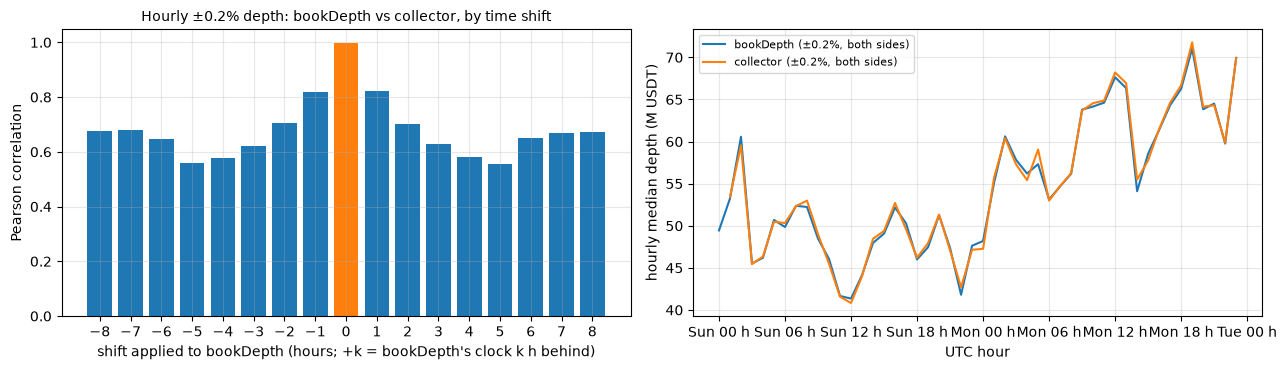

lag_h,-8,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6,7,8
corr,0.675,0.68,0.649,0.56,0.579,0.621,0.707,0.819,0.998,0.822,0.701,0.63,0.58,0.556,0.652,0.669,0.674
n,39.000,40.00,41.000,42.00,43.000,44.000,45.000,46.000,47.000,47.000,46.000,45.00,44.00,43.000,42.000,41.000,40.000


In [9]:
bd_hourly = resample_hourly(bd_run_sides.set_index("timestamp_utc")[["0.2pct_total"]])["0.2pct_total"]
col_hourly = resample_hourly(perp.set_index("local_receive_utc")[["depth_0.2pct_total_usdt"]])
col_hourly = col_hourly.loc[col_hourly.index.isin(bd_hourly.index), "depth_0.2pct_total_usdt"]
col_hourly = col_hourly.iloc[1:]                 # drop the partial first hour (Sat 23:46-23:59)
lags = lagged_correlation(bd_hourly, col_hourly, range(-8, 9))
BEST_LAG = int(lags["corr"].idxmax())
print(f"best shift: {BEST_LAG:+d} h (corr {lags['corr'].max():.3f}); corr at 0 h "
      f"{lags.loc[0, 'corr']:.3f}; next best {lags['corr'].drop(BEST_LAG).max():.3f} at "
      f"{int(lags['corr'].drop(BEST_LAG).idxmax()):+d} h")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].bar(lags.index, lags["corr"], color=["tab:orange" if l == BEST_LAG else "tab:blue" for l in lags.index])
axes[0].set_xlabel("shift applied to bookDepth (hours; +k = bookDepth's clock k h behind)")
axes[0].set_ylabel("Pearson correlation")
axes[0].set_title("Hourly ±0.2% depth: bookDepth vs collector, by time shift", fontsize=10)
axes[0].set_xticks(lags.index)
axes[0].grid(alpha=0.3)
axes[1].plot(bd_hourly.index, bd_hourly / USDT_M, label="bookDepth (±0.2%, both sides)")
axes[1].plot(col_hourly.index, col_hourly / USDT_M, label="collector (±0.2%, both sides)")
axes[1].set_ylabel("hourly median depth (M USDT)")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%a %H h", tz="UTC"))
axes[1].set_xlabel("UTC hour")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)
fig.tight_layout()
plt.show()
lags.T.round(3)

How to read it (assumption 4): left, one bar per time shift from −8 to +8 hours; the height is
the correlation between the hourly median ±0.2% depth (both sides) of bookDepth, moved by that
many hours, and the collector's (n = number of hours that overlap, in the table). If the
timestamps were, say, UTC+8 (Asia) but read as UTC, they would run 8 h ahead and the best bar
would be at −8. The best one is orange. Right,
the two hourly series in millions of USDT over the run: if the sources agree they rise and fall
together, at about the same level.

In [10]:
# The same comparison on notebook 06's window (2026-11-19 22:00-22:45 UTC, snapshots every 10 s)
levels_06 = load_snapshots(SESSION_06, markets=[PERP])
m06 = snapshot_metrics(levels_06)
m06["local_receive_utc"] = m06["local_request_utc"].map(
    levels_06.groupby("local_request_utc", observed=True)["local_receive_utc"].first())
del levels_06
sides_06 = book_depth_side_totals(bd_wide[DAY_06], pcts=(0.2,)).reset_index()
matched_06 = match_nearest(sides_06, m06[perp_cols[:2] + perp_cols[2:4] + perp_cols[5:]],
                           tolerance="30s")
rows = {}
for side in ("bid", "ask"):
    r = matched_06[f"0.2pct_{side}"] / matched_06[f"depth_0.2pct_{side}_usdt"]
    rows[side] = {"matched": len(r),
                  "collector reaches ±0.2% (%)": 100 * matched_06[f"complete_0.2pct_{side}"].mean(),
                  "median ratio": r.median(), "p10": r.quantile(0.1), "p90": r.quantile(0.9),
                  "median |gap| (s)": matched_06["gap_s"].abs().median()}
check_06 = pd.DataFrame(rows)
check_06.round(4)

,bid,ask
matched,92.0000,92.0000
collector reaches ±0.2% (%),100.0000,98.9130
median ratio,1.0024,0.9942
p10,0.9011,0.8919
p90,1.0790,1.0962
median |gap| (s),4.0330,4.0330


How to read it: the same per-side ratio (bookDepth ÷ our snapshot at ±0.2%) on notebook 06's
45 minutes, where snapshots were 10 s apart, so every bookDepth timestamp has a snapshot at most
~5 s away (`median |gap|`). It is a second, independent day for the comparison.

In [11]:
gate = {
    "bid median ratio in [0.8, 1.25]": 0.8 <= side_check.loc["bid", "median ratio bookDepth / collector"] <= 1.25,
    "ask median ratio in [0.8, 1.25]": 0.8 <= side_check.loc["ask", "median ratio bookDepth / collector"] <= 1.25,
    "best time shift = 0 h": BEST_LAG == 0,
    "(info) cumulative on every row": bool((cum["smallest step"] >= 0).all()),
    "(info) sides not swapped": bool((side_check["median |log ratio|, this side"]
                                      < side_check["median |log ratio|, sides swapped"]).all()),
    "(info) notebook 06 day also in [0.8, 1.25]": bool(check_06.loc["median ratio"].between(0.8, 1.25).all()),
}
for k, v in gate.items():
    print(f"{'PASS' if v else 'FAIL'}  {k}")
BOOKDEPTH_OK = all(v for k, v in gate.items() if not k.startswith("(info)"))
if not BOOKDEPTH_OK:
    raise RuntimeError("bookDepth failed the validation: stop here (every perp conclusion depends on it)")
print("bookDepth validated: negative % = bids, positive % = asks, cumulative from the mid, "
      "depth in BTC, notional in USDT, timestamps in UTC")

PASS  bid median ratio in [0.8, 1.25]
PASS  ask median ratio in [0.8, 1.25]
PASS  best time shift = 0 h
PASS  (info) cumulative on every row
PASS  (info) sides not swapped
PASS  (info) notebook 06 day also in [0.8, 1.25]
bookDepth validated: negative % = bids, positive % = asks, cumulative from the mid, depth in BTC, notional in USDT, timestamps in UTC


How to read it: one line per check. The first three are the pass criterion fixed before looking;
the `(info)` lines are the other assumptions, reported but not part of the criterion. If any of the
first three failed, the cell raises an error and the notebook stops. From here on, bookDepth
`notional` is used as **USDT of cumulative depth**, negative % = bids, positive % = asks, UTC.

## 4. Part 2 · Spot and perp over the 48 h (collector)

> **Warning: n = 1 Sunday and n = 1 Monday.** Every "Sunday vs Monday" difference below is one
> day against one other day. A single news item, a large order or one market maker switching off
> can make an hour look special. These tables describe **this run**; Part 3 (12 months, perp
> only) is where hour-of-week patterns can be judged.

Only the two full UTC days are used (Sunday 2026-11-22 and Monday 2026-11-23, 1,440 snapshots
per market and day; each day carries its stress label from Part 0). Per UTC hour and day: spread
in bps (median, p90 across the ~60 snapshots of the hour) and **in ticks** (spread ÷ the market's
tick size, from notebook 06), and depth within ±0.1% and ±1% of the mid per side and in total (median, p10), in
millions of USDT.

Where a market's snapshots do not reach ±1% (last column of the Part 0 inventory), its ±1% from
the collector is a **lower bound** (`LB`): this is the case of the perpetual's 1000 levels; *post-inspection*, the validated bookDepth ±1% of the
perp is shown next to it.

In [12]:
run = metrics[metrics["date_utc"].isin(list(RUN_DAYS))].copy()
run["day"] = run["date_utc"].map(RUN_DAYS)
DAYS = list(RUN_DAYS.values())
assert run.groupby(["market", "day"]).size().between(1439, 1441).all()
# Tick size per market (price step), measured in notebook 06 on 2026-11-19
ticks = json.loads((REPO_ROOT / "data" / "06_order_book" / "step0_checks.json").read_text())["ticks"]
run["spread_ticks"] = run["spread_usdt"] / run["market"].map(ticks)
run["at_one_tick"] = run["spread_ticks"].round(6) == 1

stat_spec = {"spread med (bps)": ("spread_bps", "median"),
             "spread p90 (bps)": ("spread_bps", quantile(0.9)),
             "spread med (ticks)": ("spread_ticks", "median"),
             "at 1 tick (%)": ("at_one_tick", lambda x: 100 * x.mean())}
for band in ("0.1pct", "1pct"):
    for part in ("bid", "ask", "total"):
        col = f"depth_{band}_{part}_usdt"
        b = band.replace("pct", "%")
        stat_spec[f"±{b} {part} med"] = (col, "median")
        stat_spec[f"±{b} {part} p10"] = (col, quantile(0.1))
hourly_run = run.groupby(["market", "day", "hour_utc"]).agg(
    n=("mid", "size"), **stat_spec)
depth_cols = [c for c in hourly_run.columns if c.startswith("±")]
hourly_run[depth_cols] = hourly_run[depth_cols] / USDT_M         # M USDT


def run_table(market, columns):
    t = hourly_run.loc[market, columns].unstack("day")
    t = t.swaplevel(axis=1).reindex(columns=pd.MultiIndex.from_product([DAYS, columns]))
    t.index = [hour_label(h) for h in t.index]
    t.index.name = "hour"
    return t


MAIN_COLS = ["spread med (bps)", "spread p90 (bps)", "spread med (ticks)", "at 1 tick (%)",
             "±0.1% total med", "±0.1% total p10", "±1% total med", "±1% total p10"]
SIDE_COLS = [f"±{b} {s} {q}" for b in ("0.1%", "1%") for s in ("bid", "ask") for q in ("med", "p10")]
print("spread in bps and ticks; depth in M USDT. Perp ±1%: LOWER BOUND (1000 levels never reach ±1%).")
tick_table = run.groupby(["market", "day"]).agg(
    median_mid=("mid", "median"),
    spread_median_ticks=("spread_ticks", "median"),
    spread_p90_ticks=("spread_ticks", quantile(0.9)),
    at_one_tick_pct=("at_one_tick", lambda x: 100 * x.mean())).reindex(MARKETS, level=0)
tick_table.insert(0, "tick_usdt", [ticks[m] for m in tick_table.index.get_level_values("market")])
tick_table["one_tick_in_bps"] = tick_table["tick_usdt"] / tick_table["median_mid"] * 1e4
lowest_hour = run.groupby(["market", "day", "hour_utc"])["at_one_tick"].mean().groupby(["market", "day"]).min() * 100
tick_table["lowest hourly share at 1 tick (%)"] = lowest_hour
tick_table

spread in bps and ticks; depth in M USDT. Perp ±1%: LOWER BOUND (1000 levels never reach ±1%).


tick_usdt    median_mid  spread_median_ticks  spread_p90_ticks  at_one_tick_pct  one_tick_in_bps  \
market             day                                                                                                                         
spot BTC/USDT      Mon 2026-11-23 (stress)   0.010000  61394.825000                  1.0               1.0        99.583333         0.001629   
                   Sun 2026-11-22 (normal)   0.010000  60727.415000                  1.0               1.0       100.000000         0.001647   
spot ETH/USDT      Mon 2026-11-23 (stress)   0.010000   1725.200000                  1.0               1.0        99.861111         0.057964   
                   Sun 2026-11-22 (normal)   0.010000   1707.840000                  1.0               1.0        99.791667         0.058553   
spot PENGU/USDT    Mon 2026-11-23 (stress)   0.000001      0.004365                  1.0               2.0        89.027778         2.291213   
                   Sun 2026-11-22 (normal)   0.000001      0.004263                  1.0               1.0        92.291667         2.346041   
perp BTC/USDT:USDT Mon 2026-11-23 (stress)   0.100000  61365.850000                  1.0               1.0        99.166667         0.016296   
                   Sun 2026-11-22 (normal)   0.100000  60700.050000                  1.0               1.0        99.652778         0.016474   

                                            lowest hourly share at 1 tick (%)  
market             day                                                         
spot BTC/USDT      Mon 2026-11-23 (stress)                          96.666667  
                   Sun 2026-11-22 (normal)                         100.000000  
spot ETH/USDT      Mon 2026-11-23 (stress)                          98.333333  
                   Sun 2026-11-22 (normal)                          98.333333  
spot PENGU/USDT    Mon 2026-11-23 (stress)                          66.666667  
                   Sun 2026-11-22 (normal)                          80.000000  
perp BTC/USDT:USDT Mon 2026-11-23 (stress)                          93.333333  
                   Sun 2026-11-22 (normal)                          98.333333

> **Note: where the spread sits at the minimum tick** (median of 1 tick in the table above), a
> spread in bps is one tick ÷ the price, so when the
> price moves, the spread in bps moves with it while the book is unchanged: **hour-to-hour changes
> of the spread in bps reflect the price, not liquidity.** Liquidity differences between hours show
> up in depth and in the share of snapshots *above* one tick, not in the median spread.

How to read it: one row per market and day: the tick (smallest price step, USDT), the median mid,
the median and p90 spread **in ticks**, the share of snapshots with a spread of exactly one tick,
what one tick is worth in bps at the median price, and the lowest share at one tick in any hour of
that day.

In [13]:
print('spot BTC/USDT', "· spread (bps) and total depth (M USDT) by UTC hour" + (" · ±1% = LOWER BOUND" if 'spot BTC/USDT' == PERP else ""))
display(run_table('spot BTC/USDT', MAIN_COLS).round(4 if 'spot BTC/USDT' in (BTC_SPOT, PERP) else 3))
print('spot BTC/USDT', "· depth per side (M USDT)")
run_table('spot BTC/USDT', SIDE_COLS).round(3)

spot BTC/USDT · spread (bps) and total depth (M USDT) by UTC hour


Sun 2026-11-22 (normal)                                                                                                                \
                        spread med (bps) spread p90 (bps) spread med (ticks) at 1 tick (%) ±0.1% total med ±0.1% total p10 ±1% total med ±1% total p10   
hour                                                                                                                                                     
00 UTC (18 CDMX)                  0.0017           0.0017                1.0         100.0          7.7270          7.1478       23.8263       22.8089   
01 UTC (19 CDMX)                  0.0017           0.0017                1.0         100.0          8.2045          7.3611       23.5751       22.5943   
02 UTC (20 CDMX)                  0.0017           0.0017                1.0         100.0          8.3546          7.6301       22.8239       21.6278   
03 UTC (21 CDMX)                  0.0017           0.0017                1.0         100.0          8.0569          7.3876       27.9962       24.5650   
04 UTC (22 CDMX)                  0.0017           0.0017                1.0         100.0          8.6193          7.8073       26.9931       25.2681   
05 UTC (23 CDMX)                  0.0017           0.0017                1.0         100.0          8.0780          7.2184       21.7632       20.3514   
06 UTC (00 CDMX)                  0.0017           0.0017                1.0         100.0          7.7790          7.1403       20.1502       19.0852   
07 UTC (01 CDMX)                  0.0017           0.0017                1.0         100.0          7.6991          7.1729       19.6583       19.0171   
08 UTC (02 CDMX)                  0.0017           0.0017                1.0         100.0          7.5897          6.6169       21.6861       18.4958   
09 UTC (03 CDMX)                  0.0017           0.0017                1.0         100.0          6.9469          6.1149       21.3629       17.9962   
10 UTC (04 CDMX)                  0.0016           0.0016                1.0         100.0          6.9468          6.1598       20.3004       19.0601   
11 UTC (05 CDMX)                  0.0016           0.0016                1.0         100.0          6.3257          5.8056       17.9580       16.5331   
12 UTC (06 CDMX)                  0.0016           0.0016                1.0         100.0          6.7315          5.8262       21.9920       14.7558   
13 UTC (07 CDMX)                  0.0016           0.0016                1.0         100.0          6.7723          5.9785       18.6002       17.2067   
14 UTC (08 CDMX)                  0.0016           0.0016                1.0         100.0          6.9190          6.1943       18.7038       17.8612   
15 UTC (09 CDMX)                  0.0016           0.0016                1.0         100.0          7.0630          6.5664       19.2627       18.4336   
16 UTC (10 CDMX)                  0.0016           0.0016                1.0         100.0          7.5673          7.0501       22.6209       19.1534   
17 UTC (11 CDMX)                  0.0016           0.0016                1.0         100.0          7.7491          7.1261       20.5752       19.5637   
18 UTC (12 CDMX)                  0.0016           0.0016                1.0         100.0          8.1696          7.5683       21.0127       20.3407   
19 UTC (13 CDMX)                  0.0016           0.0016                1.0         100.0          7.7860          7.3439       19.7604       19.2711   
20 UTC (14 CDMX)                  0.0016           0.0016                1.0         100.0          7.8993          7.2499       20.0283       19.4416   
21 UTC (15 CDMX)                  0.0016           0.0016                1.0         100.0          6.4674          6.0465       18.7642       18.1080   
22 UTC (16 CDMX)                  0.0016           0.0016                1.0         100.0          6.5723          6.1039       19.1724       18.2265   
23 UTC (17 CD

spot BTC/USDT · depth per side (M USDT)


Sun 2026-11-22 (normal)                                                                                           Mon 2026-11-23 (stress)  \
                           ±0.1% bid med ±0.1% bid p10 ±0.1% ask med ±0.1% ask p10 ±1% bid med ±1% bid p10 ±1% ask med ±1% ask p10           ±0.1% bid med   
hour                                                                                                                                                         
00 UTC (18 CDMX)                   3.934         3.370         3.816         3.238      13.103      11.777      10.934       9.962                   3.353   
01 UTC (19 CDMX)                   4.129         3.387         4.003         3.466      12.659      11.796      10.852      10.226                   3.578   
02 UTC (20 CDMX)                   3.914         3.451         4.278         3.775      11.909      10.433      11.096       9.963                   3.681   
03 UTC (21 CDMX)                   3.754         3.066         4.158         3.691      14.656      12.173      13.245      10.003                   3.209   
04 UTC (22 CDMX)                   4.060         3.600         4.507         3.979      12.157      10.762      14.337      12.570                   3.552   
05 UTC (23 CDMX)                   4.079         3.345         4.063         3.495      12.139      10.482       9.895       8.900                   3.887   
06 UTC (00 CDMX)                   3.989         3.390         3.881         3.384      10.557       9.377       9.583       8.888                   3.929   
07 UTC (01 CDMX)                   3.908         3.505         3.812         3.417      10.256       9.442       9.537       8.933                   4.463   
08 UTC (02 CDMX)                   3.592         2.802         3.810         3.447      10.065       7.913      11.142       9.449                   4.356   
09 UTC (03 CDMX)                   3.237         2.582         3.661         3.169       8.488       7.526      13.331       8.859                   4.245   
10 UTC (04 CDMX)                   3.532         3.055         3.379         2.858       9.686       9.003      10.784       9.554                   4.275   
11 UTC (05 CDMX)                   3.248         2.651         3.021         2.662       7.714       6.852      10.327       8.715                   4.702   
12 UTC (06 CDMX)                   3.290         2.631         3.430         2.898       8.997       7.167       9.759       7.526                   4.659   
13 UTC (07 CDMX)                   3.335         2.797         3.352         2.938       8.870       8.352       9.603       8.626                   4.087   
14 UTC (08 CDMX)                   3.524         3.044         3.438         2.904       9.694       8.826       8.901       8.243                   3.384   
15 UTC (09 CDMX)                   3.561         3.125         3.527         3.069      10.214       9.391       9.060       8.159                   3.072   
16 UTC (10 CDMX)                   3.578         3.001         4.035         3.528       9.748       8.752      12.740       9.296                   3.781   
17 UTC (11 CDMX)                   3.704         3.249         4.052         3.486      10.618       9.545       9.997       9.339                   3.551   
18 UTC (12 CDMX)                   4.123         3.473         4.082         3.614      11.092      10.064      10.052       9.295                   3.512   
19 UTC (13 CDMX)                   3.844         3.566         3.915         3.468      10.050       9.433       9.814       9.246                   3.427   
20 UTC (14 CDMX)                   3.932         3.244         4.028         3.515      10.231       9.619       9.700       9.042                   3.274   
21 UTC (15 CDMX)                   3.095         2.717         3.382         2.836       8.909       8.178       9.829       9.239                   3.346   
22 UTC (16 CDMX)                   3.124         2.639         3.59

How to read it (spot BTC/USDT): first table, one row per UTC hour (CDMX hour in brackets); for each
day, the median and p90 spread in bps across the snapshots of that hour, then the median and p10
of the depth within ±0.1% and ±1% of the mid, **both sides added**, in millions of USDT (p10 =
the depth that 90% of the snapshots of that hour exceeded: a "bad minute" of the hour). Second
table: the same depth statistics for each side (bids below the mid, asks above). Compare a row
across the two days (same hour, Sunday vs Monday) and down a column (hour to hour within a day).

In [14]:
print('spot ETH/USDT', "· spread (bps) and total depth (M USDT) by UTC hour" + (" · ±1% = LOWER BOUND" if 'spot ETH/USDT' == PERP else ""))
display(run_table('spot ETH/USDT', MAIN_COLS).round(4 if 'spot ETH/USDT' in (BTC_SPOT, PERP) else 3))
print('spot ETH/USDT', "· depth per side (M USDT)")
run_table('spot ETH/USDT', SIDE_COLS).round(3)

spot ETH/USDT · spread (bps) and total depth (M USDT) by UTC hour


Sun 2026-11-22 (normal)                                                                                                                \
                        spread med (bps) spread p90 (bps) spread med (ticks) at 1 tick (%) ±0.1% total med ±0.1% total p10 ±1% total med ±1% total p10   
hour                                                                                                                                                     
00 UTC (18 CDMX)                   0.059            0.059                1.0       100.000           3.817           3.549        14.584        14.159   
01 UTC (19 CDMX)                   0.059            0.059                1.0       100.000           4.428           4.001        15.621        14.850   
02 UTC (20 CDMX)                   0.060            0.060                1.0       100.000           4.283           3.986        15.432        14.931   
03 UTC (21 CDMX)                   0.060            0.060                1.0       100.000           4.153           3.925        20.856        14.932   
04 UTC (22 CDMX)                   0.060            0.060                1.0       100.000           4.279           3.902        14.769        14.345   
05 UTC (23 CDMX)                   0.060            0.061                1.0       100.000           4.220           3.992        15.300        14.722   
06 UTC (00 CDMX)                   0.060            0.060                1.0        98.333           4.223           4.027        14.717        14.306   
07 UTC (01 CDMX)                   0.060            0.060                1.0       100.000           4.407           4.163        15.044        14.499   
08 UTC (02 CDMX)                   0.059            0.060                1.0       100.000           4.074           3.700        15.311        14.437   
09 UTC (03 CDMX)                   0.059            0.059                1.0        98.333           3.981           3.641        15.429        14.776   
10 UTC (04 CDMX)                   0.058            0.059                1.0       100.000           4.091           3.725        15.192        14.599   
11 UTC (05 CDMX)                   0.058            0.059                1.0       100.000           4.278           4.000        11.244        10.090   
12 UTC (06 CDMX)                   0.059            0.059                1.0       100.000           4.130           3.758        14.504         9.610   
13 UTC (07 CDMX)                   0.059            0.059                1.0       100.000           4.197           3.797        14.751         9.730   
14 UTC (08 CDMX)                   0.059            0.059                1.0       100.000           4.148           3.737        14.815        14.357   
15 UTC (09 CDMX)                   0.058            0.058                1.0       100.000           4.154           3.747        14.947        14.148   
16 UTC (10 CDMX)                   0.058            0.058                1.0        98.333           4.219           3.970        15.359        14.672   
17 UTC (11 CDMX)                   0.058            0.058                1.0       100.000           4.149           3.788        21.300        20.870   
18 UTC (12 CDMX)                   0.058            0.058                1.0       100.000           4.370           4.076        21.815        21.316   
19 UTC (13 CDMX)                   0.058            0.058                1.0       100.000           4.368           4.152        22.019        21.721   
20 UTC (14 CDMX)                   0.058            0.058                1.0       100.000           4.297           4.103        22.075        21.685   
21 UTC (15 CDMX)                   0.058            0.058                1.0       100.000           4.145           3.473        21.262        19.975   
22 UTC (16 CDMX)                   0.058            0.058                1.0       100.000           3.266           2.936        19.551        14.098   
23 UTC (17 CD

spot ETH/USDT · depth per side (M USDT)


Sun 2026-11-22 (normal)                                                                                           Mon 2026-11-23 (stress)  \
                           ±0.1% bid med ±0.1% bid p10 ±0.1% ask med ±0.1% ask p10 ±1% bid med ±1% bid p10 ±1% ask med ±1% ask p10           ±0.1% bid med   
hour                                                                                                                                                         
00 UTC (18 CDMX)                   1.850         1.580         1.987         1.638       7.031       6.607       7.637       7.055                   1.636   
01 UTC (19 CDMX)                   2.122         1.732         2.277         1.934       7.417       6.797       8.241       7.382                   2.040   
02 UTC (20 CDMX)                   2.031         1.583         2.301         1.999       7.468       6.781       8.003       7.431                   2.131   
03 UTC (21 CDMX)                   1.978         1.686         2.161         1.842      13.058       7.319       7.616       7.010                   2.159   
04 UTC (22 CDMX)                   2.035         1.720         2.235         1.910       7.481       6.867       7.316       6.829                   2.206   
05 UTC (23 CDMX)                   2.121         1.698         2.140         1.841       8.028       7.257       7.353       6.879                   2.268   
06 UTC (00 CDMX)                   2.055         1.745         2.185         1.777       7.314       6.787       7.360       6.839                   2.148   
07 UTC (01 CDMX)                   2.065         1.862         2.280         1.927       7.682       7.048       7.499       6.905                   2.359   
08 UTC (02 CDMX)                   1.961         1.518         2.175         1.711       7.338       6.627       7.869       7.220                   2.276   
09 UTC (03 CDMX)                   1.948         1.558         2.026         1.634       7.484       6.691       7.969       7.308                   2.251   
10 UTC (04 CDMX)                   1.925         1.598         2.133         1.788       7.571       6.967       7.551       7.023                   2.296   
11 UTC (05 CDMX)                   2.050         1.714         2.200         1.904       5.754       4.781       5.158       4.792                   2.308   
12 UTC (06 CDMX)                   2.042         1.607         2.153         1.755       7.111       4.584       7.119       4.589                   2.321   
13 UTC (07 CDMX)                   1.973         1.678         2.232         1.787       6.957       4.724       7.397       4.862                   2.207   
14 UTC (08 CDMX)                   1.831         1.486         2.351         2.062       6.946       6.273       7.917       7.206                   1.432   
15 UTC (09 CDMX)                   1.899         1.532         2.243         1.944       7.017       6.309       7.993       7.235                   1.552   
16 UTC (10 CDMX)                   1.967         1.718         2.246         1.886       7.452       6.607       8.090       7.597                   1.624   
17 UTC (11 CDMX)                   1.969         1.703         2.245         1.820      13.310      12.621       8.073       7.443                   1.632   
18 UTC (12 CDMX)                   2.128         1.765         2.234         1.910      13.696      13.301       8.089       7.515                   1.671   
19 UTC (13 CDMX)                   2.131         1.829         2.213         1.995      13.847      13.440       8.150       7.708                   2.097   
20 UTC (14 CDMX)                   2.109         1.773         2.208         1.935      13.847      13.247       8.279       7.626                   2.091   
21 UTC (15 CDMX)                   1.897         1.540         2.149         1.876      12.784      12.120       8.277       7.715                   2.175   
22 UTC (16 CDMX)                   1.571         1.300         1.61

How to read it (spot ETH/USDT): first table, one row per UTC hour (CDMX hour in brackets); for each
day, the median and p90 spread in bps across the snapshots of that hour, then the median and p10
of the depth within ±0.1% and ±1% of the mid, **both sides added**, in millions of USDT (p10 =
the depth that 90% of the snapshots of that hour exceeded: a "bad minute" of the hour). Second
table: the same depth statistics for each side (bids below the mid, asks above). Compare a row
across the two days (same hour, Sunday vs Monday) and down a column (hour to hour within a day).

In [15]:
print('spot PENGU/USDT', "· spread (bps) and total depth (M USDT) by UTC hour" + (" · ±1% = LOWER BOUND" if 'spot PENGU/USDT' == PERP else ""))
display(run_table('spot PENGU/USDT', MAIN_COLS).round(4 if 'spot PENGU/USDT' in (BTC_SPOT, PERP) else 3))
print('spot PENGU/USDT', "· depth per side (M USDT)")
run_table('spot PENGU/USDT', SIDE_COLS).round(3)

spot PENGU/USDT · spread (bps) and total depth (M USDT) by UTC hour


Sun 2026-11-22 (normal)                                                                                                                \
                        spread med (bps) spread p90 (bps) spread med (ticks) at 1 tick (%) ±0.1% total med ±0.1% total p10 ±1% total med ±1% total p10   
hour                                                                                                                                                     
00 UTC (18 CDMX)                   2.331            2.335                1.0        93.333           0.015           0.012         0.300         0.264   
01 UTC (19 CDMX)                   2.328            2.333                1.0        95.000           0.017           0.013         0.293         0.284   
02 UTC (20 CDMX)                   2.353            4.688                1.0        85.000           0.017           0.013         0.299         0.275   
03 UTC (21 CDMX)                   2.382            2.389                1.0        95.000           0.016           0.013         0.286         0.270   
04 UTC (22 CDMX)                   2.376            2.381                1.0        98.333           0.015           0.012         0.288         0.268   
05 UTC (23 CDMX)                   2.387            2.632                1.0        90.000           0.016           0.012         0.286         0.263   
06 UTC (00 CDMX)                   2.375            2.382                1.0        93.333           0.015           0.012         0.287         0.268   
07 UTC (01 CDMX)                   2.381            2.621                1.0        90.000           0.016           0.012         0.296         0.281   
08 UTC (02 CDMX)                   2.356            4.684                1.0        80.000           0.015           0.010         0.296         0.261   
09 UTC (03 CDMX)                   2.343            2.347                1.0        93.333           0.015           0.012         0.296         0.263   
10 UTC (04 CDMX)                   2.310            4.615                1.0        81.667           0.015           0.011         0.302         0.271   
11 UTC (05 CDMX)                   2.304            2.308                1.0        98.333           0.016           0.012         0.307         0.289   
12 UTC (06 CDMX)                   2.316            4.611                1.0        83.333           0.014           0.010         0.295         0.259   
13 UTC (07 CDMX)                   2.332            4.654                1.0        81.667           0.016           0.011         0.311         0.282   
14 UTC (08 CDMX)                   2.335            2.341                1.0        95.000           0.015           0.010         0.302         0.272   
15 UTC (09 CDMX)                   2.337            4.665                1.0        88.333           0.016           0.013         0.307         0.291   
16 UTC (10 CDMX)                   2.339            2.342                1.0        96.667           0.018           0.015         0.314         0.295   
17 UTC (11 CDMX)                   2.343            2.348                1.0        98.333           0.021           0.015         0.307         0.292   
18 UTC (12 CDMX)                   2.354            2.360                1.0        95.000           0.020           0.015         0.295         0.271   
19 UTC (13 CDMX)                   2.351            2.355                1.0        98.333           0.023           0.018         0.306         0.292   
20 UTC (14 CDMX)                   2.353            2.356                1.0       100.000           0.027           0.021         0.315         0.294   
21 UTC (15 CDMX)                   2.351            2.354                1.0       100.000           0.025           0.019         0.304         0.278   
22 UTC (16 CDMX)                   2.368            2.607                1.0        90.000           0.019           0.014         0.303         0.269   
23 UTC (17 CD

spot PENGU/USDT · depth per side (M USDT)


Sun 2026-11-22 (normal)                                                                                           Mon 2026-11-23 (stress)  \
                           ±0.1% bid med ±0.1% bid p10 ±0.1% ask med ±0.1% ask p10 ±1% bid med ±1% bid p10 ±1% ask med ±1% ask p10           ±0.1% bid med   
hour                                                                                                                                                         
00 UTC (18 CDMX)                   0.007         0.003         0.009         0.005       0.153       0.127       0.153       0.134                   0.012   
01 UTC (19 CDMX)                   0.008         0.004         0.009         0.006       0.150       0.125       0.145       0.136                   0.010   
02 UTC (20 CDMX)                   0.006         0.002         0.012         0.007       0.146       0.121       0.159       0.140                   0.013   
03 UTC (21 CDMX)                   0.006         0.002         0.011         0.007       0.142       0.119       0.151       0.134                   0.010   
04 UTC (22 CDMX)                   0.005         0.002         0.011         0.007       0.143       0.116       0.149       0.130                   0.011   
05 UTC (23 CDMX)                   0.006         0.002         0.010         0.007       0.146       0.119       0.139       0.124                   0.010   
06 UTC (00 CDMX)                   0.008         0.004         0.007         0.005       0.149       0.124       0.141       0.120                   0.011   
07 UTC (01 CDMX)                   0.008         0.005         0.008         0.004       0.160       0.135       0.141       0.124                   0.012   
08 UTC (02 CDMX)                   0.009         0.005         0.006         0.003       0.157       0.136       0.135       0.119                   0.013   
09 UTC (03 CDMX)                   0.010         0.007         0.006         0.003       0.165       0.136       0.135       0.120                   0.013   
10 UTC (04 CDMX)                   0.008         0.005         0.007         0.004       0.168       0.141       0.138       0.124                   0.012   
11 UTC (05 CDMX)                   0.009         0.006         0.007         0.002       0.171       0.150       0.138       0.126                   0.014   
12 UTC (06 CDMX)                   0.007         0.004         0.007         0.004       0.149       0.130       0.141       0.124                   0.009   
13 UTC (07 CDMX)                   0.009         0.004         0.007         0.004       0.162       0.149       0.151       0.124                   0.010   
14 UTC (08 CDMX)                   0.009         0.005         0.006         0.003       0.162       0.143       0.140       0.124                   0.006   
15 UTC (09 CDMX)                   0.007         0.005         0.009         0.005       0.158       0.136       0.150       0.137                   0.011   
16 UTC (10 CDMX)                   0.009         0.005         0.008         0.005       0.164       0.139       0.155       0.128                   0.009   
17 UTC (11 CDMX)                   0.011         0.007         0.009         0.005       0.169       0.152       0.140       0.126                   0.009   
18 UTC (12 CDMX)                   0.009         0.005         0.011         0.006       0.158       0.135       0.144       0.129                   0.010   
19 UTC (13 CDMX)                   0.014         0.006         0.011         0.007       0.158       0.137       0.149       0.136                   0.007   
20 UTC (14 CDMX)                   0.014         0.009         0.012         0.007       0.164       0.143       0.160       0.142                   0.004   
21 UTC (15 CDMX)                   0.014         0.010         0.011         0.006       0.163       0.154       0.141       0.116                   0.006   
22 UTC (16 CDMX)                   0.011         0.007         0.00

How to read it (spot PENGU/USDT): first table, one row per UTC hour (CDMX hour in brackets); for each
day, the median and p90 spread in bps across the snapshots of that hour, then the median and p10
of the depth within ±0.1% and ±1% of the mid, **both sides added**, in millions of USDT (p10 =
the depth that 90% of the snapshots of that hour exceeded: a "bad minute" of the hour). Second
table: the same depth statistics for each side (bids below the mid, asks above). Compare a row
across the two days (same hour, Sunday vs Monday) and down a column (hour to hour within a day).

In [16]:
print('perp BTC/USDT:USDT', "· spread (bps) and total depth (M USDT) by UTC hour" + (" · ±1% = LOWER BOUND" if 'perp BTC/USDT:USDT' == PERP else ""))
display(run_table('perp BTC/USDT:USDT', MAIN_COLS).round(4 if 'perp BTC/USDT:USDT' in (BTC_SPOT, PERP) else 3))
print('perp BTC/USDT:USDT', "· depth per side (M USDT)")
run_table('perp BTC/USDT:USDT', SIDE_COLS).round(3)

perp BTC/USDT:USDT · spread (bps) and total depth (M USDT) by UTC hour · ±1% = LOWER BOUND


Sun 2026-11-22 (normal)                                                                                                                \
                        spread med (bps) spread p90 (bps) spread med (ticks) at 1 tick (%) ±0.1% total med ±0.1% total p10 ±1% total med ±1% total p10   
hour                                                                                                                                                     
00 UTC (18 CDMX)                  0.0166           0.0166                1.0      100.0000         20.6069         17.0157       57.1354       51.9999   
01 UTC (19 CDMX)                  0.0166           0.0167                1.0      100.0000         22.5548         20.9374       61.4798       57.1490   
02 UTC (20 CDMX)                  0.0167           0.0168                1.0      100.0000         24.7418         20.0876       72.8408       58.0439   
03 UTC (21 CDMX)                  0.0169           0.0169                1.0      100.0000         18.1912         15.9384       54.3350       51.0426   
04 UTC (22 CDMX)                  0.0169           0.0169                1.0       98.3333         18.1463         16.7753       55.0364       52.5646   
05 UTC (23 CDMX)                  0.0170           0.0170                1.0       98.3333         20.9410         18.1076       60.3266       54.8078   
06 UTC (00 CDMX)                  0.0169           0.0170                1.0       98.3333         20.4381         18.5705       60.9844       56.0697   
07 UTC (01 CDMX)                  0.0169           0.0169                1.0      100.0000         22.3419         20.8223       62.3004       57.3532   
08 UTC (02 CDMX)                  0.0168           0.0169                1.0      100.0000         22.2687         17.7206       65.7919       56.1709   
09 UTC (03 CDMX)                  0.0167           0.0167                1.0      100.0000         19.2552         15.7773       59.5194       53.9026   
10 UTC (04 CDMX)                  0.0164           0.0165                1.0      100.0000         18.2511         15.6848       56.7952       52.2581   
11 UTC (05 CDMX)                  0.0164           0.0164                1.0      100.0000         16.7049         15.2892       50.7520       47.5399   
12 UTC (06 CDMX)                  0.0164           0.0165                1.0       98.3333         15.9252         13.7137       52.0978       47.8949   
13 UTC (07 CDMX)                  0.0165           0.0165                1.0      100.0000         17.0156         15.2227       53.8696       50.6512   
14 UTC (08 CDMX)                  0.0165           0.0165                1.0      100.0000         18.7095         17.0449       56.8964       52.6148   
15 UTC (09 CDMX)                  0.0164           0.0164                1.0      100.0000         19.5085         17.8246       57.0966       52.1784   
16 UTC (10 CDMX)                  0.0163           0.0164                1.0      100.0000         21.1748         19.6226       60.7080       56.4961   
17 UTC (11 CDMX)                  0.0164           0.0164                1.0      100.0000         18.6144         17.1392       59.3957       55.1231   
18 UTC (12 CDMX)                  0.0165           0.0165                1.0      100.0000         18.2312         16.8255       54.2043       52.1852   
19 UTC (13 CDMX)                  0.0165           0.0165                1.0      100.0000         19.3899         17.0604       54.9230       52.0334   
20 UTC (14 CDMX)                  0.0165           0.0165                1.0      100.0000         20.2949         18.5467       58.2604       53.2552   
21 UTC (15 CDMX)                  0.0164           0.0164                1.0      100.0000         19.4938         17.1872       55.5026       52.4232   
22 UTC (16 CDMX)                  0.0164           0.0165                1.0      100.0000         15.9628         13.6990       51.4360       47.9207   
23 UTC (17 CD

perp BTC/USDT:USDT · depth per side (M USDT)


Sun 2026-11-22 (normal)                                                                                           Mon 2026-11-23 (stress)  \
                           ±0.1% bid med ±0.1% bid p10 ±0.1% ask med ±0.1% ask p10 ±1% bid med ±1% bid p10 ±1% ask med ±1% ask p10           ±0.1% bid med   
hour                                                                                                                                                         
00 UTC (18 CDMX)                  11.093         9.012         9.426         7.704      30.016      26.883      26.649      24.896                   9.860   
01 UTC (19 CDMX)                  11.733        10.212        11.211         9.240      31.923      27.903      29.812      27.552                  11.154   
02 UTC (20 CDMX)                  11.265         8.494        13.995        10.229      31.000      27.421      40.920      28.530                  11.929   
03 UTC (21 CDMX)                   8.043         6.483         9.821         8.592      25.724      23.578      27.940      25.265                  11.881   
04 UTC (22 CDMX)                   9.031         7.722         9.099         7.994      27.802      25.830      27.250      25.655                  11.661   
05 UTC (23 CDMX)                   9.781         8.038        10.416         9.124      30.052      27.138      29.934      27.031                  12.500   
06 UTC (00 CDMX)                  10.572         9.471         9.679         8.269      30.595      28.793      29.838      25.719                  10.985   
07 UTC (01 CDMX)                  11.909        10.017        10.563         8.394      31.893      28.906      30.572      27.877                  11.096   
08 UTC (02 CDMX)                  11.796         8.504         9.749         7.908      32.748      27.474      31.378      27.121                  10.865   
09 UTC (03 CDMX)                  10.578         8.189         8.052         6.874      31.749      26.992      27.130      24.399                  13.112   
10 UTC (04 CDMX)                  10.194         7.888         7.993         6.418      29.734      26.138      26.772      24.021                  13.274   
11 UTC (05 CDMX)                   9.491         8.088         7.119         6.202      26.005      24.509      24.166      22.354                  13.366   
12 UTC (06 CDMX)                   8.165         5.998         7.584         5.823      25.815      23.135      25.361      22.226                  14.410   
13 UTC (07 CDMX)                   7.968         6.340         8.833         7.485      25.810      23.301      27.469      24.846                  15.059   
14 UTC (08 CDMX)                   8.778         7.160        10.043         8.213      27.167      24.654      30.017      26.108                  10.794   
15 UTC (09 CDMX)                  10.062         8.491         9.824         8.259      28.013      26.046      28.835      25.311                  11.664   
16 UTC (10 CDMX)                  11.157         9.184        10.123         8.190      30.349      27.076      29.957      26.443                  11.507   
17 UTC (11 CDMX)                   8.172         7.027        10.441         8.837      28.072      25.666      31.287      27.234                  12.684   
18 UTC (12 CDMX)                   8.205         7.052         9.920         8.414      26.429      24.665      27.486      25.418                  13.496   
19 UTC (13 CDMX)                   9.941         8.089         9.193         8.072      27.949      25.308      26.655      24.684                  14.867   
20 UTC (14 CDMX)                  10.493         9.020         9.729         8.607      29.784      27.175      27.758      25.257                  13.764   
21 UTC (15 CDMX)                  10.934         9.098         8.187         7.009      29.489      26.652      26.353      23.029                  14.034   
22 UTC (16 CDMX)                   7.599         6.271         7.98

How to read it (perp BTC/USDT:USDT): first table, one row per UTC hour (CDMX hour in brackets); for each
day, the median and p90 spread in bps across the snapshots of that hour, then the median and p10
of the depth within ±0.1% and ±1% of the mid, **both sides added**, in millions of USDT (p10 =
the depth that 90% of the snapshots of that hour exceeded: a "bad minute" of the hour). Second
table: the same depth statistics for each side (bids below the mid, asks above). Compare a row
across the two days (same hour, Sunday vs Monday) and down a column (hour to hour within a day).

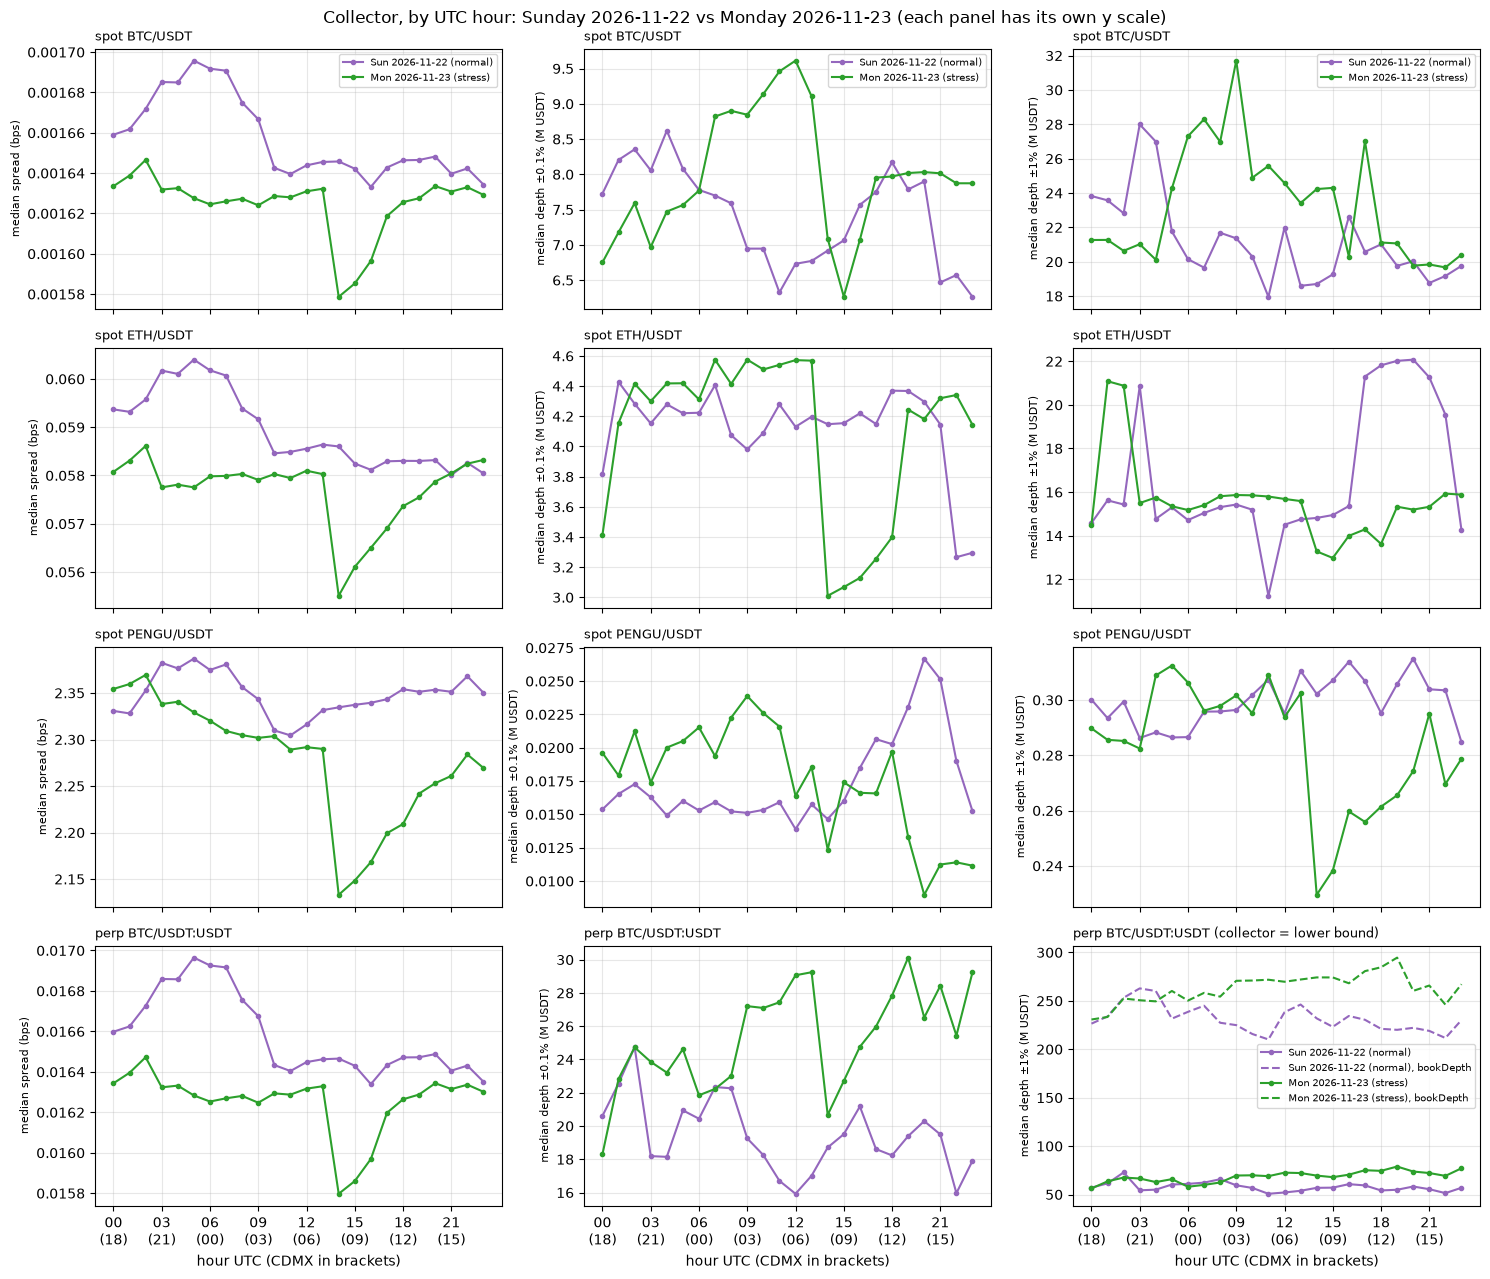

In [17]:
bd_run_hourly = resample_hourly(bd_run_sides.set_index("timestamp_utc")[["1pct_total"]])
bd_run_hourly = add_time_labels(bd_run_hourly.reset_index(), "timestamp_utc")
bd_run_hourly = bd_run_hourly[bd_run_hourly["date_utc"].isin(list(RUN_DAYS))]
bd_run_hourly["day"] = bd_run_hourly["date_utc"].map(RUN_DAYS)

fig, axes = plt.subplots(4, 3, figsize=(15, 13), sharex=True)
panels = [("spread med (bps)", "median spread (bps)"), ("±0.1% total med", "median depth ±0.1% (M USDT)"),
          ("±1% total med", "median depth ±1% (M USDT)")]
colors = {DAYS[0]: "tab:purple", DAYS[1]: "tab:green"}
for row, market in enumerate(MARKETS):
    for col, (stat, ylabel) in enumerate(panels):
        ax = axes[row, col]
        for day in DAYS:
            s = hourly_run.loc[(market, day), stat]
            ax.plot(s.index, s.values, marker=".", color=colors[day], label=day)
            if market == PERP and stat == "±1% total med":
                b = bd_run_hourly[bd_run_hourly["day"] == day].set_index("hour_utc")["1pct_total"] / USDT_M
                ax.plot(b.index, b.values, ls="--", color=colors[day], label=f"{day}, bookDepth")
        ax.set_title(f"{market}" + (" (collector = lower bound)" if market == PERP and col == 2 else ""),
                     fontsize=9, loc="left")
        ax.set_ylabel(ylabel, fontsize=8)
        ax.grid(alpha=0.3)
        if row == 0 or (market == PERP and col == 2):
            ax.legend(fontsize=7)
for ax in axes[-1]:
    ax.set_xticks(range(0, 24, 3))
    ax.set_xticklabels([f"{h:02d}\n({int(cdmx_hour(h)):02d})" for h in range(0, 24, 3)])
    ax.set_xlabel("hour UTC (CDMX in brackets)")
fig.suptitle("Collector, by UTC hour: Sunday 2026-11-22 vs Monday 2026-11-23 (each panel has its own y scale)")
fig.tight_layout()
plt.show()

How to read it: one row of panels per market, one column per measure: median spread (bps),
median depth within ±0.1% and within ±1% (both sides, M USDT). x = UTC hour (CDMX below it, in
brackets); purple = Sunday, green = Monday. Each panel has its own y scale, so compare shapes
within a panel and levels with the tables. In the perp's ±1% panel the solid lines are the
collector's lower bound and the dashed lines bookDepth's ±1% for the same hours (complete, as
validated in Part 1).

### 4.1 Round-trip cost by hour (taker → taker)

Same code and fees as notebook 07 (`market_order_legs` + `round_trips`): buy at market, sell at
market on the same snapshot, same notional per leg. Sizes: 10k / 100k / 1M USDT (BTC spot, ETH
spot, BTC perp) and 1k / 10k / 100k (PENGU). The cost is split into **fee** (fixed: 20 bps spot,
10 bps perp) and **spread + impact** (what the book costs). Median across the snapshots of each
hour.

In [18]:
rt_run = rt[rt["date_utc"].isin(list(RUN_DAYS))].copy()
rt_run["day"] = rt_run["date_utc"].map(RUN_DAYS)
rt_run["book_bps"] = rt_run["spread_bps"] + rt_run["impact_bps"]
fill = rt_run.groupby(["market", "size_usdt"])["status"].apply(lambda s: f"{(s == STATUS_FILLED).sum()}/{len(s)}")
print("fillable snapshots per market and size:", fill.to_dict())
# Medians below drop NaN costs; they are only valid if every round trip could be filled.
assert (rt_run["status"] == STATUS_FILLED).all(), "some round trips cannot fill: use the 'cannot fill' rule of 4.2"
rt_hourly = rt_run.groupby(["market", "size_usdt", "day", "hour_utc"]).agg(
    total=("total_bps", "median"), fee=("fee_bps", "median"), book=("book_bps", "median"))


def cost_table(market):
    t = rt_hourly.loc[market][["total", "book"]].unstack(["size_usdt", "day"])
    t.columns = pd.MultiIndex.from_tuples([(f"{s:,.0f}", d, "total" if c == "total" else "spread+impact")
                                           for c, s, d in t.columns])
    t = t.sort_index(axis=1, level=[0, 1], sort_remaining=False)
    t = t[[c for s in dict.fromkeys(c[0] for c in t.columns) for d in DAYS
           for c in [(s, d, "total"), (s, d, "spread+impact")]]]
    t.index = [hour_label(h) for h in t.index]
    t.index.name = "hour"
    return t


for market in MARKETS:
    fee = rt_hourly.loc[market, "fee"].iloc[0]
    print(f"{market} · taker -> taker median by hour, bps of the notional · fee = {fee:.0f} bps at every hour")
    display(cost_table(market).round(3))

fillable snapshots per market and size: {('perp BTC/USDT:USDT', 10000.0): '2880/2880', ('perp BTC/USDT:USDT', 100000.0): '2880/2880', ('perp BTC/USDT:USDT', 1000000.0): '2880/2880', ('spot BTC/USDT', 10000.0): '2880/2880', ('spot BTC/USDT', 100000.0): '2880/2880', ('spot BTC/USDT', 1000000.0): '2880/2880', ('spot ETH/USDT', 10000.0): '2880/2880', ('spot ETH/USDT', 100000.0): '2880/2880', ('spot ETH/USDT', 1000000.0): '2880/2880', ('spot PENGU/USDT', 1000.0): '2880/2880', ('spot PENGU/USDT', 10000.0): '2880/2880', ('spot PENGU/USDT', 100000.0): '2880/2880'}
spot BTC/USDT · taker -> taker median by hour, bps of the notional · fee = 20 bps at every hour


1,000,000                                                                      10,000                                        \
                 Sun 2026-11-22 (normal)               Mon 2026-11-23 (stress)               Sun 2026-11-22 (normal)               Mon 2026-11-23 (stress)   
                                   total spread+impact                   total spread+impact                   total spread+impact                   total   
hour                                                                                                                                                         
00 UTC (18 CDMX)                  22.321         2.321                  23.250         3.250                  20.002         0.002                  20.002   
01 UTC (19 CDMX)                  22.200         2.200                  23.025         3.025                  20.002         0.002                  20.002   
02 UTC (20 CDMX)                  22.402         2.402                  22.761         2.761                  20.002         0.002                  20.002   
03 UTC (21 CDMX)                  22.695         2.695                  23.430         3.430                  20.002         0.002                  20.002   
04 UTC (22 CDMX)                  22.509         2.509                  22.905         2.905                  20.002         0.002                  20.002   
05 UTC (23 CDMX)                  22.600         2.600                  22.773         2.773                  20.002         0.002                  20.002   
06 UTC (00 CDMX)                  22.645         2.645                  22.615         2.615                  20.002         0.002                  20.002   
07 UTC (01 CDMX)                  22.566         2.566                  22.355         2.355                  20.002         0.002                  20.002   
08 UTC (02 CDMX)                  23.055         3.055                  22.389         2.389                  20.002         0.002                  20.002   
09 UTC (03 CDMX)                  23.264         3.264                  22.556         2.556                  20.002         0.002                  20.002   
10 UTC (04 CDMX)                  23.022         3.022                  22.282         2.282                  20.002         0.002                  20.002   
11 UTC (05 CDMX)                  23.377         3.377                  21.924         1.924                  20.002         0.002                  20.002   
12 UTC (06 CDMX)                  23.310         3.310                  22.091         2.091                  20.002         0.002                  20.002   
13 UTC (07 CDMX)                  23.211         3.211                  22.616         2.616                  20.002         0.002                  20.002   
14 UTC (08 CDMX)                  22.883         2.883                  23.505         3.505                  20.002         0.002                  20.002   
15 UTC (09 CDMX)                  22.960         2.960                  24.100         4.100                  20.002         0.002                  20.002   
16 UTC (10 CDMX)                  22.798         2.798                  23.588         3.588                  20.002         0.002                  20.002   
17 UTC (11 CDMX)                  22.773         2.773                  22.780         2.780                  20.002         0.002                  20.002   
18 UTC (12 CDMX)                  22.665         2.665                  22.623         2.623                  20.002         0.002                  20.002   
19 UTC (13 CDMX)                  22.395         2.395                  22.697         2.697                  20.002         0.002                  20.002   
20 UTC (14 CDMX)                  22.388         2.388                  22.630         2.630                  20.002         0.002                  20.002   
21 UTC (15 CDMX)                  23.117         3.117                  22.508   

spot ETH/USDT · taker -> taker median by hour, bps of the notional · fee = 20 bps at every hour


1,000,000                                                                      10,000                                        \
                 Sun 2026-11-22 (normal)               Mon 2026-11-23 (stress)               Sun 2026-11-22 (normal)               Mon 2026-11-23 (stress)   
                                   total spread+impact                   total spread+impact                   total spread+impact                   total   
hour                                                                                                                                                         
00 UTC (18 CDMX)                  25.402         5.402                  26.127         6.127                  20.059         0.059                  20.082   
01 UTC (19 CDMX)                  25.169         5.169                  25.611         5.611                  20.059         0.059                  20.058   
02 UTC (20 CDMX)                  25.629         5.629                  25.530         5.530                  20.060         0.060                  20.059   
03 UTC (21 CDMX)                  25.826         5.826                  25.672         5.672                  20.060         0.060                  20.236   
04 UTC (22 CDMX)                  25.652         5.652                  25.299         5.299                  20.060         0.060                  20.058   
05 UTC (23 CDMX)                  25.739         5.739                  25.303         5.303                  20.090         0.090                  20.058   
06 UTC (00 CDMX)                  25.710         5.710                  25.201         5.201                  20.064         0.064                  20.058   
07 UTC (01 CDMX)                  25.591         5.591                  24.967         4.967                  20.060         0.060                  20.058   
08 UTC (02 CDMX)                  25.929         5.929                  25.034         5.034                  20.060         0.060                  20.058   
09 UTC (03 CDMX)                  26.110         6.110                  25.013         5.013                  20.059         0.059                  20.058   
10 UTC (04 CDMX)                  25.815         5.815                  24.929         4.929                  20.058         0.058                  20.058   
11 UTC (05 CDMX)                  25.552         5.552                  24.746         4.746                  20.059         0.059                  20.058   
12 UTC (06 CDMX)                  25.721         5.721                  24.920         4.920                  20.061         0.061                  20.058   
13 UTC (07 CDMX)                  25.692         5.692                  25.202         5.202                  20.059         0.059                  20.058   
14 UTC (08 CDMX)                  25.545         5.545                  27.647         7.647                  20.059         0.059                  20.056   
15 UTC (09 CDMX)                  25.571         5.571                  27.206         7.206                  20.058         0.058                  20.057   
16 UTC (10 CDMX)                  25.379         5.379                  27.094         7.094                  20.058         0.058                  20.057   
17 UTC (11 CDMX)                  25.537         5.537                  26.731         6.731                  20.058         0.058                  20.057   
18 UTC (12 CDMX)                  25.216         5.216                  26.340         6.340                  20.058         0.058                  20.057   
19 UTC (13 CDMX)                  24.985         4.985                  25.420         5.420                  20.058         0.058                  20.058   
20 UTC (14 CDMX)                  24.949         4.949                  25.189         5.189                  20.058         0.058                  20.058   
21 UTC (15 CDMX)                  25.384         5.384                  25.206   

spot PENGU/USDT · taker -> taker median by hour, bps of the notional · fee = 20 bps at every hour


1,000                                                                      10,000                                        \
                 Sun 2026-11-22 (normal)               Mon 2026-11-23 (stress)               Sun 2026-11-22 (normal)               Mon 2026-11-23 (stress)   
                                   total spread+impact                   total spread+impact                   total spread+impact                   total   
hour                                                                                                                                                         
00 UTC (18 CDMX)                  27.970         7.970                  25.936         5.936                  35.670        15.670                  33.767   
01 UTC (19 CDMX)                  26.429         6.429                  25.914         5.914                  34.503        14.503                  33.814   
02 UTC (20 CDMX)                  27.474         7.474                  26.328         6.328                  35.219        15.219                  33.471   
03 UTC (21 CDMX)                  27.657         7.657                  26.165         6.165                  35.688        15.688                  34.353   
04 UTC (22 CDMX)                  28.072         8.072                  26.267         6.267                  35.921        15.921                  34.069   
05 UTC (23 CDMX)                  28.100         8.100                  26.442         6.442                  35.662        15.662                  33.352   
06 UTC (00 CDMX)                  27.841         7.841                  25.439         5.439                  35.694        15.694                  32.650   
07 UTC (01 CDMX)                  27.170         7.170                  25.197         5.197                  35.246        15.246                  32.729   
08 UTC (02 CDMX)                  26.878         6.878                  25.580         5.580                  35.668        15.668                  32.679   
09 UTC (03 CDMX)                  26.798         6.798                  25.595         5.595                  35.374        15.374                  31.895   
10 UTC (04 CDMX)                  27.016         7.016                  25.570         5.570                  35.179        15.179                  31.673   
11 UTC (05 CDMX)                  27.389         7.389                  26.041         6.041                  34.754        14.754                  33.039   
12 UTC (06 CDMX)                  27.239         7.239                  25.744         5.744                  35.663        15.663                  34.180   
13 UTC (07 CDMX)                  26.471         6.471                  25.946         5.946                  35.061        15.061                  33.458   
14 UTC (08 CDMX)                  26.815         6.815                  27.275         7.275                  35.496        15.496                  38.108   
15 UTC (09 CDMX)                  26.831         6.831                  26.667         6.667                  35.345        15.345                  36.053   
16 UTC (10 CDMX)                  26.568         6.568                  27.230         7.230                  34.621        14.621                  36.056   
17 UTC (11 CDMX)                  26.348         6.348                  27.010         7.010                  33.527        13.527                  36.456   
18 UTC (12 CDMX)                  26.737         6.737                  27.855         7.855                  33.611        13.611                  35.448   
19 UTC (13 CDMX)                  26.514         6.514                  27.602         7.602                  33.084        13.084                  37.408   
20 UTC (14 CDMX)                  26.237         6.237                  28.558         8.558                  32.608        12.608                  38.621   
21 UTC (15 CDMX)                  26.156         6.156                  28.372       

perp BTC/USDT:USDT · taker -> taker median by hour, bps of the notional · fee = 10 bps at every hour


1,000,000                                                                      10,000                                        \
                 Sun 2026-11-22 (normal)               Mon 2026-11-23 (stress)               Sun 2026-11-22 (normal)               Mon 2026-11-23 (stress)   
                                   total spread+impact                   total spread+impact                   total spread+impact                   total   
hour                                                                                                                                                         
00 UTC (18 CDMX)                  11.681         1.681                  12.265         2.265                  10.017         0.017                  10.016   
01 UTC (19 CDMX)                  11.448         1.448                  11.851         1.851                  10.017         0.017                  10.016   
02 UTC (20 CDMX)                  11.519         1.519                  11.556         1.556                  10.017         0.017                  10.016   
03 UTC (21 CDMX)                  11.959         1.959                  11.799         1.799                  10.017         0.017                  10.016   
04 UTC (22 CDMX)                  11.938         1.938                  11.680         1.680                  10.017         0.017                  10.016   
05 UTC (23 CDMX)                  11.759         1.759                  11.628         1.628                  10.017         0.017                  10.016   
06 UTC (00 CDMX)                  11.808         1.808                  11.567         1.567                  10.017         0.017                  10.016   
07 UTC (01 CDMX)                  11.825         1.825                  11.614         1.614                  10.017         0.017                  10.016   
08 UTC (02 CDMX)                  11.950         1.950                  11.768         1.768                  10.017         0.017                  10.016   
09 UTC (03 CDMX)                  12.006         2.006                  11.602         1.602                  10.017         0.017                  10.016   
10 UTC (04 CDMX)                  12.148         2.148                  11.435         1.435                  10.016         0.016                  10.016   
11 UTC (05 CDMX)                  12.033         2.033                  11.558         1.558                  10.016         0.016                  10.016   
12 UTC (06 CDMX)                  12.463         2.463                  11.563         1.563                  10.016         0.016                  10.016   
13 UTC (07 CDMX)                  12.531         2.531                  11.635         1.635                  10.016         0.016                  10.016   
14 UTC (08 CDMX)                  12.152         2.152                  12.500         2.500                  10.016         0.016                  10.016   
15 UTC (09 CDMX)                  12.025         2.025                  12.123         2.123                  10.016         0.016                  10.016   
16 UTC (10 CDMX)                  12.037         2.037                  11.945         1.945                  10.016         0.016                  10.016   
17 UTC (11 CDMX)                  12.234         2.234                  11.732         1.732                  10.016         0.016                  10.016   
18 UTC (12 CDMX)                  12.210         2.210                  11.562         1.562                  10.016         0.016                  10.016   
19 UTC (13 CDMX)                  12.305         2.305                  11.419         1.419                  10.016         0.016                  10.016   
20 UTC (14 CDMX)                  12.098         2.098                  11.720         1.720                  10.016         0.016                  10.016   
21 UTC (15 CDMX)                  12.039         2.039                  11.683   

How to read it: the first line counts the snapshots where the visible book could fill both legs
(all of them if every entry reads n/n). Then one table per market: one row per UTC hour; for
each size (USDT per leg) and day, `total` is the median round-trip cost in **bps of the notional**
(20 = 0.20% of the position, paid once to get in and out) and `spread+impact` is the part paid
to the book. The fee is the same at every hour and is printed above each table, so `total` −
`spread+impact` ≈ fee (exactly, since the fee is a constant).

In [19]:
rows = []
for (market, size), g in rt_hourly.groupby(level=["market", "size_usdt"]):
    g = g.droplevel(["market", "size_usdt"])
    lo, hi = g["book"].idxmin(), g["book"].idxmax()
    rows.append({"market": market, "size (USDT)": f"{size:,.0f}", "fee (bps)": g["fee"].iloc[0],
                 "spread+impact: lowest hourly median (bps)": g["book"].min(),
                 "at": f"{lo[0][:3]} {hour_label(lo[1])}",
                 "spread+impact: highest hourly median (bps)": g["book"].max(),
                 "at ": f"{hi[0][:3]} {hour_label(hi[1])}",
                 "highest / lowest": g["book"].max() / g["book"].min(),
                 "fee share of total at the worst hour (%)": 100 * g["fee"].iloc[0] / g.loc[hi, "total"]})
cost_range = pd.DataFrame(rows).set_index(["market", "size (USDT)"]).reindex(MARKETS, level=0)
cost_range.round(3)

fee (bps)  spread+impact: lowest hourly median (bps)                    at  spread+impact: highest hourly median (bps)  \
market             size (USDT)                                                                                                                           
spot BTC/USDT      10,000            20.0                                      0.002  Mon 14 UTC (08 CDMX)                                       0.002   
                   100,000           20.0                                      0.033  Mon 11 UTC (05 CDMX)                                       0.986   
                   1,000,000         20.0                                      1.924  Mon 11 UTC (05 CDMX)                                       4.100   
spot ETH/USDT      10,000            20.0                                      0.056  Mon 14 UTC (08 CDMX)                                       0.236   
                   100,000           20.0                                      0.573  Mon 11 UTC (05 CDMX)                                       1.454   
                   1,000,000         20.0                                      4.746  Mon 11 UTC (05 CDMX)                                       7.647   
spot PENGU/USDT    1,000             20.0                                      5.197  Mon 07 UTC (01 CDMX)                                       9.298   
                   10,000            20.0                                     11.673  Mon 10 UTC (04 CDMX)                                      18.621   
                   100,000           20.0                                     49.822  Sun 21 UTC (15 CDMX)                                      84.829   
perp BTC/USDT:USDT 10,000            10.0                                      0.016  Mon 14 UTC (08 CDMX)                                       0.017   
                   100,000           10.0                                      0.016  Mon 16 UTC (10 CDMX)                                       0.218   
                   1,000,000         10.0                                      1.419  Mon 19 UTC (13 CDMX)                                       2.553   

                                                 at   highest / lowest  fee share of total at the worst hour (%)  
market             size (USDT)                                                                                    
spot BTC/USDT      10,000       Sun 05 UTC (23 CDMX)             1.070                                    99.992  
                   100,000      Mon 14 UTC (08 CDMX)            30.156                                    95.301  
                   1,000,000    Mon 15 UTC (09 CDMX)             2.130                                    82.988  
spot ETH/USDT      10,000       Mon 03 UTC (21 CDMX)             4.214                                    98.831  
                   100,000      Mon 15 UTC (09 CDMX)             2.537                                    93.223  
                   1,000,000    Mon 14 UTC (08 CDMX)             1.611                                    72.340  
spot PENGU/USDT    1,000        Mon 22 UTC (16 CDMX)             1.789                                    68.265  
                   10,000       Mon 20 UTC (14 CDMX)             1.595                                    51.786  
                   100,000      Mon 14 UTC (08 CDMX)             1.703                                    19.079  
perp BTC/USDT:USDT 10,000       Sun 05 UTC (23 CDMX)             1.072                                    99.831  
                   100,000      Mon 14 UTC (08 CDMX)            13.519                                    97.870  
                   1,000,000    Sun 22 UTC (16 CDMX)             1.800                                    79.661

How to read it: one row per market and size, summarizing the 48 hourly medians of the previous
tables. The lowest and highest hourly median of the **book part** (spread + impact, bps) and the
day and hour where each happened; their ratio (how many times more expensive the book was at its
worst hour than at its best); and the share of the fee in the total at that worst hour (close to
100% = the hour barely matters next to the fee).

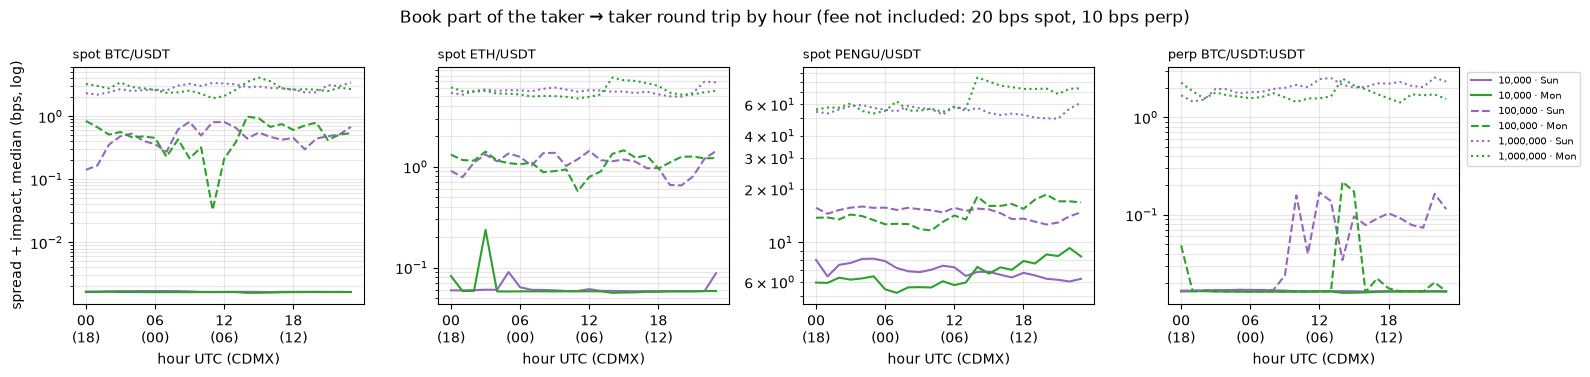

In [20]:
fig, axes = plt.subplots(1, len(MARKETS), figsize=(16, 3.8))
for ax, market in zip(axes, MARKETS):
    for size, ls in zip(SIZES[market], ["-", "--", ":"]):
        for day in DAYS:
            s = rt_hourly.loc[(market, size, day), "book"]
            ax.plot(s.index, s.values, ls=ls, color=colors[day], label=f"{size:,.0f} · {day[:3]}")
    ax.set_yscale("log")
    ax.set_title(market, fontsize=9, loc="left")
    ax.set_xticks(range(0, 24, 6))
    ax.set_xticklabels([f"{h:02d}\n({int(cdmx_hour(h)):02d})" for h in range(0, 24, 6)])
    ax.set_xlabel("hour UTC (CDMX)")
    ax.grid(alpha=0.3, which="both")
axes[0].set_ylabel("spread + impact, median (bps, log)")
axes[-1].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.suptitle("Book part of the taker → taker round trip by hour (fee not included: 20 bps spot, 10 bps perp)")
fig.tight_layout()
plt.show()

How to read it: one panel per market; x = UTC hour (CDMX), y = median spread + impact of the
round trip in bps on a **log scale** (each grid step ×10). Line style = size (solid smallest,
dotted largest), color = day (purple Sunday, green Monday). The fee is left out on purpose: add
20 bps (spot) or 10 bps (perp) to read the total. Flat lines = the hour does not matter for that
size; bumps = hours when the book was thinner or the spread wider.

### 4.2 PENGU: how often can each size be filled at all?

The cost tables above are only computed when every snapshot could be filled (the code stops
otherwise). Here PENGU is walked again with
**1k / 10k / 100k / 1M** USDT per leg and **both directions** (long = buy then sell, short = sell
then buy), same code and fees as notebook 07. A snapshot whose visible book cannot fill an order
is labeled **"cannot fill"** and is **kept** in the statistics: the median below treats it as an
infinite cost, so if more than half of the snapshots cannot fill, the median itself reads
"cannot fill". The same function is run on notebook 06's 45 minutes, which reproduces notebook
07's number for the same window.

In [21]:
PENGU_SIZES = (1_000.0, 10_000.0, 100_000.0, 1_000_000.0)
BOTH_DIRECTIONS = {"long": ("buy", "sell"), "short": ("sell", "buy")}
TT = {"taker -> taker": ("taker", "taker")}


def pengu_round_trips(levels):
    legs = market_order_legs(levels, PENGU_SIZES)
    out = round_trips(legs, {PENGU: FEES[PENGU]}, combos=TT, directions=BOTH_DIRECTIONS)
    side_total = legs.groupby(["local_request_utc", "side"])["total_quote"].first().unstack("side")
    return out, side_total


pengu_path = CACHE / "pengu_round_trips_both.parquet"
pengu_side_path = CACHE / "pengu_visible_notional.parquet"
if not (pengu_path.exists() and pengu_side_path.exists()):
    parts, sides = [], []
    for f in sorted(RUN_DIR.glob("*.parquet")):           # one hour file at a time
        lv = pd.read_parquet(f, filters=[("market", "==", PENGU)])
        lv = lv.drop_duplicates(DEDUP_KEY, keep="last")
        o, sd = pengu_round_trips(lv)
        parts.append(o)
        sides.append(sd)
    pd.concat(parts, ignore_index=True).to_parquet(pengu_path)
    pd.concat(sides).to_parquet(pengu_side_path)
pengu_rt = add_time_labels(pd.read_parquet(pengu_path), "local_receive_utc")
pengu_rt = pengu_rt[pengu_rt["date_utc"].isin(list(RUN_DAYS))]
pengu_visible = pd.read_parquet(pengu_side_path)

levels_06_pengu = load_snapshots(SESSION_06, markets=[PENGU])
pengu_rt_06, pengu_visible_06 = pengu_round_trips(levels_06_pengu)
del levels_06_pengu


def fill_table(rt_):
    rows = []
    for (size, direction), g in rt_.groupby(["size_usdt", "direction"]):
        cost = g["total_bps"].where(g["status"] == STATUS_FILLED, np.inf)   # cannot fill = infinite
        med = cost.median()
        rows.append({"size (USDT)": f"{size:,.0f}", "direction": direction, "snapshots": len(g),
                     "filled (%)": 100 * (g["status"] == STATUS_FILLED).mean(),
                     "cannot fill: book exhausted (%)": 100 * (g["status"] == STATUS_EXHAUSTED).mean(),
                     "cannot fill: truncated by the API (%)": 100 * (g["status"] == STATUS_TRUNCATED).mean(),
                     "median total, all snapshots (bps)": "cannot fill" if np.isinf(med) else round(med, 2),
                     "median total, filled only (bps)": round(g.loc[g["status"] == STATUS_FILLED, "total_bps"].median(), 2)})
    return pd.DataFrame(rows).set_index(["size (USDT)", "direction"])


fills = pd.concat({"48 h run (Sun + Mon)": fill_table(pengu_rt), "notebook 06 window (Thu 22 UTC)": fill_table(pengu_rt_06)})
fills

snapshots  filled (%)  cannot fill: book exhausted (%)  cannot fill: truncated by the API (%)  \
                                size (USDT) direction                                                                                                  
48 h run (Sun + Mon)            1,000       long            2880       100.0                              0.0                                    0.0   
                                            short           2880       100.0                              0.0                                    0.0   
                                10,000      long            2880       100.0                              0.0                                    0.0   
                                            short           2880       100.0                              0.0                                    0.0   
                                100,000     long            2880       100.0                              0.0                                    0.0   
                                            short           2880       100.0                              0.0                                    0.0   
                                1,000,000   long            2880         0.0                            100.0                                    0.0   
                                            short           2880         0.0                            100.0                                    0.0   
notebook 06 window (Thu 22 UTC) 1,000       long             270       100.0                              0.0                                    0.0   
                                            short            270       100.0                              0.0                                    0.0   
                                10,000      long             270       100.0                              0.0                                    0.0   
                                            short            270       100.0                              0.0                                    0.0   
                                100,000     long             270       100.0                              0.0                                    0.0   
                                            short            270       100.0                              0.0                                    0.0   
                                1,000,000   long             270         0.0                            100.0                                    0.0   
                                            short            270         0.0                            100.0                                    0.0   

                                                      median total, all snapshots (bps)  median total, filled only (bps)  
                                size (USDT) direction                                                                     
48 h run (Sun + Mon)            1,000       long                                  26.68                            26.68  
                                            short                                 26.68                            26.68  
                                10,000      long                                  34.69                            34.69  
                                            short                                 34.69                            34.69  
                                100,000     long                                  77.27                            77.27  
                                            short                                 77.27                            77.27  
                                1,000,000   long                            cannot fill                              NaN  
                                            short                           cannot fill                              NaN  
notebook 06 window (Thu 22 UTC) 1,000       long                                  26.42 

How to read it: one row per sample (the 48 h run, notebook 06's 45 minutes), size (USDT per leg)
and direction. `filled` = share of snapshots where both legs could be filled by the visible book;
the next two columns split the rest: **book exhausted** (the API returned fewer levels than asked:
we saw the whole book and it is too small) and **truncated by the API** (we got every level we
could ask for and they were not enough: the book may go on). `median total, all snapshots` counts
"cannot fill" as an infinitely expensive round trip; `filled only` is the median of the fillable
snapshots alone (the statistic of the earlier tables, biased low when some cannot fill).

In [22]:
win06 = pengu_rt_06[(pengu_rt_06["size_usdt"] == 100_000.0) & (pengu_rt_06["direction"] == "long")]
run100 = pengu_rt[(pengu_rt["size_usdt"] == 100_000.0) & (pengu_rt["direction"] == "long")]
d06 = snapshot_metrics(load_snapshots(SESSION_06, markets=[PENGU]))
d_run = run[run["market"] == PENGU]
compare_pengu = pd.DataFrame({
    "notebook 06 window": {"median taker -> taker 100k (bps)": win06["total_bps"].median(),
                           "median book part (bps)": (win06["spread_bps"] + win06["impact_bps"]).median(),
                           "median depth ±1% bid (M USDT)": d06["depth_1pct_bid_usdt"].median() / USDT_M,
                           "median depth ±1% ask (M USDT)": d06["depth_1pct_ask_usdt"].median() / USDT_M,
                           "median depth ±1% total (M USDT)": (d06["depth_1pct_bid_usdt"] + d06["depth_1pct_ask_usdt"]).median() / USDT_M,
                           "median visible bids, all levels (M USDT)": pengu_visible_06["bid"].median() / USDT_M,
                           "median visible asks, all levels (M USDT)": pengu_visible_06["ask"].median() / USDT_M,
                           "median mid (USDT)": d06["mid"].median()},
    "48 h run": {"median taker -> taker 100k (bps)": run100["total_bps"].median(),
                 "median book part (bps)": (run100["spread_bps"] + run100["impact_bps"]).median(),
                 "median depth ±1% bid (M USDT)": d_run["depth_1pct_bid_usdt"].median() / USDT_M,
                 "median depth ±1% ask (M USDT)": d_run["depth_1pct_ask_usdt"].median() / USDT_M,
                 "median depth ±1% total (M USDT)": d_run["depth_1pct_total_usdt"].median() / USDT_M,
                 "median visible bids, all levels (M USDT)": pengu_visible.loc[
                     pengu_visible.index.isin(run.loc[run["market"] == PENGU, "local_request_utc"]), "bid"].median() / USDT_M,
                 "median visible asks, all levels (M USDT)": pengu_visible.loc[
                     pengu_visible.index.isin(run.loc[run["market"] == PENGU, "local_request_utc"]), "ask"].median() / USDT_M,
                 "median mid (USDT)": d_run["mid"].median()}})
compare_pengu["48 h / notebook 06"] = compare_pengu["48 h run"] / compare_pengu["notebook 06 window"]
compare_pengu.round(4)

,notebook 06 window,48 h run,48 h / notebook 06
median taker -> taker 100k (bps),82.2723,77.2674,0.9392
median book part (bps),62.2723,57.2674,0.9196
median depth ±1% bid (M USDT),0.1732,0.1563,0.9022
median depth ±1% ask (M USDT),0.1230,0.1389,1.1297
median depth ±1% total (M USDT),0.2948,0.2950,1.0006
"median visible bids, all levels (M USDT)",0.4553,0.3839,0.8432
"median visible asks, all levels (M USDT)",4.6763,4.6780,1.0004
median mid (USDT),0.0046,0.0043,0.9422


How to read it: the PENGU 100k long round trip (taker → taker) with the same function and fees on
two samples: notebook 06's 45 minutes (the window of notebook 07) and the 48 h run. Rows: the
median total and its book part (bps), the median depth within ±1% per side and in total, the
median USDT of **all** visible levels per side (5000 levels), and the median mid. The last
column is the ratio run ÷ notebook 06.

Why ±1% depth does not tell the whole story: a 100k order walks **one side** only. If that side
holds about half of the ±1% total, a 100k order eats a large part of it and keeps walking past
±1%, where the book is thinner, so its impact is large. An order larger than everything the 5000
visible levels hold on one side is a "cannot fill" in the table above.

### 4.3 Spot vs perp: do their depth profiles move together?

Correlation between the 48 hourly medians (Sunday + Monday) of spot depth and perp depth.
±0.1% and ±0.2% use the collector on both sides (both complete); ±1% uses spot from the collector
and the perp from bookDepth (*post-inspection*: the collector's perp ±1% is only a lower bound).

perp source  hours  Pearson corr  rank corr
spot market     band                                            
spot BTC/USDT   0.1%   collector     48         0.608      0.561
                0.2%   collector     48         0.474      0.458
                1%     bookDepth     48         0.505      0.542
spot ETH/USDT   0.1%   collector     48         0.225      0.381
                0.2%   collector     48         0.098      0.216
                1%     bookDepth     48        -0.326     -0.176
spot PENGU/USDT 0.1%   collector     48        -0.073      0.065
                0.2%   collector     48        -0.398     -0.356
                1%     bookDepth     48        -0.545     -0.480

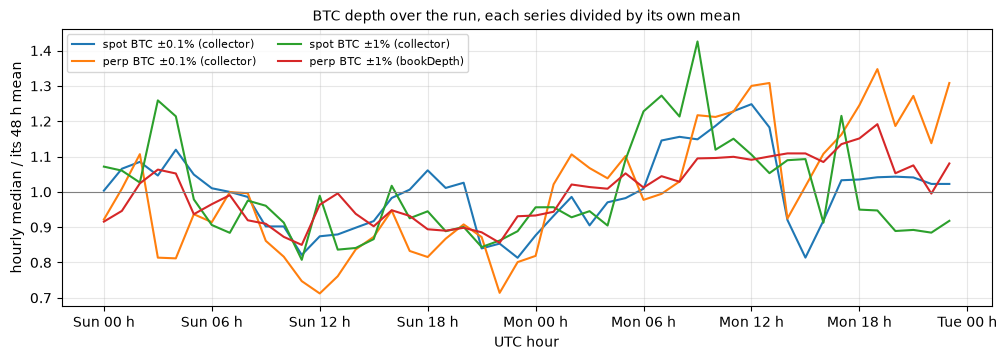

In [23]:
hourly_key = run.assign(hour=run["local_receive_utc"].dt.floor("1h"))
prof = hourly_key.groupby(["market", "hour"])[["depth_0.1pct_total_usdt", "depth_0.2pct_total_usdt",
                                                "depth_1pct_total_usdt"]].median()
bd_1pct = resample_hourly(bd_run_sides.set_index("timestamp_utc")[["1pct_total"]])["1pct_total"]
rows = []
for spot in (BTC_SPOT, ETH_SPOT, PENGU):
    for band in ("0.1pct", "0.2pct", "1pct"):
        x = prof.loc[spot, f"depth_{band}_total_usdt"]
        y = bd_1pct.reindex(x.index) if band == "1pct" else prof.loc[PERP, f"depth_{band}_total_usdt"]
        both = pd.concat([x, y], axis=1, keys=["spot", "perp"]).dropna()
        rows.append({"spot market": spot, "band": band.replace("pct", "%"),
                     "perp source": "bookDepth" if band == "1pct" else "collector",
                     "hours": len(both), "Pearson corr": both["spot"].corr(both["perp"]),
                     "rank corr": both["spot"].rank().corr(both["perp"].rank())})
spot_perp = pd.DataFrame(rows).set_index(["spot market", "band"])
display(spot_perp.round(3))

fig, ax = plt.subplots(figsize=(12, 3.6))
for name, s in (("spot BTC ±0.1% (collector)", prof.loc[BTC_SPOT, "depth_0.1pct_total_usdt"]),
                ("perp BTC ±0.1% (collector)", prof.loc[PERP, "depth_0.1pct_total_usdt"]),
                ("spot BTC ±1% (collector)", prof.loc[BTC_SPOT, "depth_1pct_total_usdt"]),
                ("perp BTC ±1% (bookDepth)", bd_1pct.reindex(prof.loc[BTC_SPOT].index))):
    ax.plot(s.index, s / s.mean(), label=name)
ax.axhline(1, color="grey", lw=0.8)
ax.set_ylabel("hourly median / its 48 h mean")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %H h", tz="UTC"))
ax.set_xlabel("UTC hour")
ax.set_title("BTC depth over the run, each series divided by its own mean", fontsize=10)
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=0.3)
plt.show()

How to read it: the table has one row per spot market and band; `hours` = hourly points paired
(48 if both full days are there); `Pearson corr` = linear correlation of the two hourly series
(+1 = they rise and fall together in proportion, 0 = no linear relation, −1 = opposite);
`rank corr` = the same on ranks (less sensitive to one extreme hour). With 48 points, a
correlation of about ±0.28 or more is unlikely to come from pure chance if the hours were
independent; hourly depth is not independent from one hour to the next, so that threshold is
optimistic. The plot divides each BTC series by its own mean so books of different size share
one axis: 1.2 = 20% more depth than that book's average over the run.

### 4.4 Volume vs depth across coins (48 h)

Does the coin with more volume also have more depth? For the two full days of the run: the median
hourly spot volume (USDT, from 1-minute candles of data.binance.vision) and the median depth within
±0.1% and ±1% from the collector, per coin, and how the coins rank on each.

In [24]:
pengu_klines = pd.concat([read_klines_zip(VISION / spot_klines_path("PENGUUSDT", "1m", d))
                          for d in ("2026-11-22", "2026-11-23")]).sort_index()
minute = {"spot BTC/USDT": klines["BTCUSDT"], "spot ETH/USDT": klines["ETHUSDT"], PENGU: pengu_klines}
run_lo, run_hi = min(RUN_DAYS), max(RUN_DAYS) + pd.Timedelta(days=1)
rows = {}
for market, k in minute.items():
    k = k[(k.index >= run_lo) & (k.index < run_hi)]
    vol_h = k["quote_volume"].resample("1h").sum()
    d = run[run["market"] == market]
    rows[market] = {"1-min candles": len(k), "median hourly volume (M USDT)": vol_h.median() / USDT_M,
                    "median depth ±0.1% (M USDT)": d["depth_0.1pct_total_usdt"].median() / USDT_M,
                    "median depth ±1% (M USDT)": d["depth_1pct_total_usdt"].median() / USDT_M}
coins = pd.DataFrame(rows).T
coins["hourly volume / ±1% depth"] = coins["median hourly volume (M USDT)"] / coins["median depth ±1% (M USDT)"]
for c in ("median hourly volume (M USDT)", "median depth ±0.1% (M USDT)", "median depth ±1% (M USDT)"):
    coins[f"rank by {c.split(' (')[0].replace('median ', '')}"] = coins[c].rank(ascending=False).astype(int)
same_order = (coins["rank by hourly volume"] == coins["rank by depth ±1%"]).all()
print(f"same order by volume and by ±1% depth: {bool(same_order)}")
print(f"within BTC over 12 months (Part 4): correlation of the hour-of-day profiles of spot volume and perp ±1% depth -> section 6")
coins.round(3)

same order by volume and by ±1% depth: True
within BTC over 12 months (Part 4): correlation of the hour-of-day profiles of spot volume and perp ±1% depth -> section 6


,1-min candles,median hourly volume (M USDT),median depth ±0.1% (M USDT),median depth ±1% (M USDT),hourly volume / ±1% depth,rank by hourly volume,rank by depth ±0.1%,rank by depth ±1%
spot BTC/USDT,2880.0,41.099,7.693,21.220,1.937,1,1,1
spot ETH/USDT,2880.0,16.498,4.216,15.354,1.074,2,2,2
spot PENGU/USDT,2880.0,0.098,0.017,0.295,0.332,3,3,3


How to read it: one row per spot coin. The 1-minute candles count should be 2,880 (two days).
Then the median USDT traded per hour, the median depth within ±0.1% and ±1% (both sides) in
millions of USDT, and how many hours of volume the ±1% book holds (volume ÷ depth: how many times
the book near the mid "turns over" per hour). The ranks (1 = largest) say whether ordering the
coins by volume gives the same order as ordering them by depth. Across coins this compares very
different markets; the within-coin question (hours of one coin) is answered in Part 4.

## 5. Part 3 · Perp BTCUSDT over 12 months (bookDepth, 2025-11-24 → 2026-11-23)

Per bookDepth timestamp (~30 s): cumulative USDT depth within ±0.2% and ±1% of the mid, per side
and total. Each hour is summarized by the **median of its ~120 timestamps**; the patterns below
are statistics of those hourly values across days.

Periods kept apart (lab rule 4, fixed before looking): **post-hack, 2026-10-29 → 2026-11-14**
(labeled, shown on its own, excluded from every "normal" pattern), and the **10 October 2025**
stress case (2025-10-06 → 2025-10-15, outside the window).

In [25]:
bd_days = sorted({d.strftime("%Y-%m-%d") for d in pd.date_range(*WINDOW_12M, freq="D")}
                 | {d.strftime("%Y-%m-%d") for d in pd.date_range(*STRESS_10_10, freq="D")})
sides_path, quality_path = CACHE / "bookdepth_sides_30s.parquet", CACHE / "bookdepth_quality.parquet"
if not (sides_path.exists() and quality_path.exists()):
    frames, quality = [], []
    for day in bd_days:
        if not (VISION / book_depth_path("BTCUSDT", day)).exists():   # not published by Binance
            continue
        raw = read_book_depth_day(day)
        w = book_depth_wide(raw)
        ts = w.index.to_series()
        quality.append({"day": pd.Timestamp(day, tz="UTC"), "rows": len(raw), "timestamps": len(w),
                        "percentages": len(w["notional"].columns),
                        "has ±0.2": all(p in w["notional"].columns for p in (-0.2, 0.2)),
                        "has ±1": all(p in w["notional"].columns for p in (-1.0, 1.0)),
                        "max step (s)": ts.diff().dt.total_seconds().max(),
                        "first": ts.iloc[0], "last": ts.iloc[-1],
                        "cumulative (% complete rows)": check_cumulative(w.dropna())["monotonic (% of timestamps)"].min()})
        frames.append(book_depth_side_totals(w, pcts=(0.2, 1.0)))
    pd.concat(frames).to_parquet(sides_path)
    pd.DataFrame(quality).to_parquet(quality_path)
bd_sides = pd.read_parquet(sides_path)
bd_quality = pd.read_parquet(quality_path).set_index("day")
not_published = sorted(set(bd_days) - {d.strftime("%Y-%m-%d") for d in bd_quality.index})
print(f"{len(bd_quality)} daily files of {len(bd_days)} days asked, {len(bd_sides):,} timestamps; "
      f"not published on data.binance.vision (left out, not filled): {not_published}")
print(f"timestamps per day: min {bd_quality['timestamps'].min()}, median {bd_quality['timestamps'].median():.0f}, "
      f"max {bd_quality['timestamps'].max()}; every day has ±1%: {bool(bd_quality['has ±1'].all())}; "
      f"cumulative on every complete row of every day: {bool((bd_quality['cumulative (% complete rows)'] == 100).all())}")
short = bd_quality[bd_quality["timestamps"] < 2400]
print(f"days with fewer than 2,400 timestamps (of 2,880): {[f'{d:%Y-%m-%d} ({n})' for d, n in short['timestamps'].items()]}")
with_02 = bd_quality[bd_quality["has ±0.2"]]
print(f"days with ±0.2%: {len(with_02)} of {len(bd_quality)}; first {with_02.index.min():%Y-%m-%d}, last "
      f"{with_02.index.max():%Y-%m-%d}; days without it: {int((~bd_quality['has ±0.2']).sum())} "
      f"(first {bd_quality.index[~bd_quality['has ±0.2']].min():%Y-%m-%d}, last "
      f"{bd_quality.index[~bd_quality['has ±0.2']].max():%Y-%m-%d})")
holes = bd_quality[bd_quality["max step (s)"] > 120]
print(f"days with a hole longer than 2 min between timestamps: {len(holes)}")
holes[["timestamps", "max step (s)", "first", "last"]]

374 daily files of 375 days asked, 1,039,227 timestamps; not published on data.binance.vision (left out, not filled): ['2026-10-08']
timestamps per day: min 339, median 2821, max 2880; every day has ±1%: True; cumulative on every complete row of every day: True
days with fewer than 2,400 timestamps (of 2,880): ['2026-10-07 (339)', '2026-10-09 (2389)']
days with ±0.2%: 312 of 374; first 2026-01-15, last 2026-11-23; days without it: 62 (first 2025-10-06, last 2026-01-14)
days with a hole longer than 2 min between timestamps: 195


,timestamps,max step (s),first,last
day,,,,
2025-10-08 00:00:00+00:00,2863,177.0,2025-10-08 00:00:07+00:00,2025-10-08 23:59:31+00:00
2025-10-09 00:00:00+00:00,2821,1408.0,2025-10-09 00:00:07+00:00,2025-10-09 23:59:31+00:00
2025-10-11 00:00:00+00:00,2845,181.0,2025-10-11 00:00:07+00:00,2025-10-11 23:59:31+00:00
2025-10-12 00:00:00+00:00,2812,210.0,2025-10-12 00:00:07+00:00,2025-10-12 23:59:30+00:00
2025-10-13 00:00:00+00:00,2812,210.0,2025-10-13 00:00:07+00:00,2025-10-13 23:59:31+00:00
...,...,...,...,...
2026-05-30 00:00:00+00:00,2674,243.0,2026-05-30 00:00:08+00:00,2026-05-30 23:59:32+00:00
2026-05-31 00:00:00+00:00,2592,233.0,2026-05-31 00:00:07+00:00,2026-05-31 23:59:31+00:00
2026-06-01 00:00:00+00:00,2628,240.0,2026-06-01 00:00:07+00:00,2026-06-01 23:59:30+00:00


How to read it: the lines summarize the quality of every daily file: how many there are, the
number of timestamps per day (2,880 = one every 30 s for 24 h), whether every day has ±1%, which
days have ±0.2%, whether the cumulative property of Part 1 holds on every row that has all its
percentages (on the first day with ±0.2% those rows start during the day, so its earlier rows are
incomplete), and which days have far fewer timestamps than 2,880 (a short file: its hours rest on
fewer values). The table lists the days where Binance's file has a gap of more than 2 minutes
between consecutive timestamps (empty = none): those hours have fewer timestamps behind their
median, nothing is filled in.

*Post-inspection:* the older BTCUSDT files **have no ±0.2% rows** (only ±1 … ±5); the first day
with ±0.2% is printed above. Nothing is filled in: every ±0.2% number in this
part covers only the days that have it (fewer weeks per cell, fewer window months), while ±1%
covers the full 12 months. ±1% is therefore the main series for H1 and H2; ±0.2% is shown as
a second, shorter check. The 10/10 case (2025) has no ±0.2%.

### 5.1 Frozen and broken values (post-inspection)

Looking at the series showed values that a real book cannot produce: one side stuck at the same
value (or two values taking turns) for hours or days, and stretches where one side sits near zero
while the other is several times its usual size (as if the file measured both sides from a wrong
mid). A cumulative USDT sum with many decimals should not repeat exactly in a live book (the
table below shows the share flagged on the three days validated in Part 1), so an exact repeat is
a strong sign of a frozen file. The tables below show
where it happens.

**Rules (post-inspection; nothing is filled in):**

1. A side's value that appears **exactly ≥ 20 times in the same UTC day** (~10 minutes of rows)
   is set to NaN, and so is the total. Counting per day catches values that alternate or come
   back between other rows. The second table below shows how much the share flagged depends on
   the threshold (5 to 40 repeats).
2. A day where **any** column has **more than 5%** of its values flagged is **dropped from every
   12-month pattern**: on such days the other side looked distorted too. The 10/10 case keeps
   its days (it is shown on its own), with the frozen values removed.

Section 5.2 repeats the key numbers on the raw series, to show whether the rule matters.

In [26]:
bd_clean, frozen, frozen_day_share, BAD_DAYS = clean_book_depth(bd_sides, min_count=20, max_day_share=0.05)
in_window_rows = bd_sides.index >= pd.Timestamp(WINDOW_12M[0], tz="UTC")
has_value = bd_sides[frozen.columns].notna()
flagged = frozen & has_value


def share(rows):
    return flagged[rows].sum() / has_value[rows].sum() * 100


validation_rows = bd_sides.index.floor("D").isin(pd.to_datetime([DAY_06, "2026-11-22", "2026-11-23"], utc=True))
frozen_share = pd.DataFrame({"10/10 case": share(~in_window_rows), "12-month window": share(in_window_rows),
                             "Part 1 validation days": share(validation_rows)}).T
print("share of rows with a value that are flagged as frozen (%)")
display(frozen_share.round(2))
thresholds = {}
for k in (5, 10, 20, 40):
    _, fz, _, bad = clean_book_depth(bd_sides, min_count=k, max_day_share=0.05)
    hv = bd_sides[fz.columns].notna()
    row = ((fz & hv)[in_window_rows].sum() / hv[in_window_rows].sum() * 100).round(3).to_dict()
    row["days dropped (all periods)"] = len(bad)
    thresholds[f"≥ {k} repeats"] = row
print("sensitivity of rule 1 to its threshold, 12-month window (% of rows with a value)")
display(pd.DataFrame(thresholds).T)
print(f"days dropped from the 12-month patterns (> 5% frozen in some column): "
      f"{[f'{d:%Y-%m-%d}' for d in BAD_DAYS if d >= pd.Timestamp(WINDOW_12M[0], tz='UTC')]}")
frozen_day_share[(frozen_day_share > 0).any(axis=1)].mul(100).round(1)

share of rows with a value that are flagged as frozen (%)


,0.2pct_bid,0.2pct_ask,1pct_bid,1pct_ask
10/10 case,NaN,NaN,48.51,0.0
12-month window,0.31,2.28,0.07,1.2
Part 1 validation days,0.00,0.00,0.00,0.0


sensitivity of rule 1 to its threshold, 12-month window (% of rows with a value)


,0.2pct_bid,0.2pct_ask,1pct_bid,1pct_ask,days dropped (all periods)
≥ 5 repeats,0.307,2.288,0.07,1.200,17.0
≥ 10 repeats,0.307,2.285,0.07,1.200,17.0
≥ 20 repeats,0.307,2.282,0.07,1.200,17.0
≥ 40 repeats,0.303,2.282,0.07,1.193,17.0


days dropped from the 12-month patterns (> 5% frozen in some column): ['2026-03-20', '2026-04-22', '2026-09-03', '2026-09-04', '2026-09-05', '2026-09-06', '2026-09-07', '2026-09-08', '2026-09-09', '2026-09-10', '2026-09-11']


,0.2pct_bid,0.2pct_ask,1pct_bid,1pct_ask
timestamp_utc,,,,
2025-10-10 00:00:00+00:00,NaN,NaN,33.1,0.0
2025-10-11 00:00:00+00:00,NaN,NaN,100.0,0.0
2025-10-12 00:00:00+00:00,NaN,NaN,100.0,0.0
2025-10-13 00:00:00+00:00,NaN,NaN,100.0,0.0
2025-10-14 00:00:00+00:00,NaN,NaN,100.0,0.0
2025-10-15 00:00:00+00:00,NaN,NaN,55.2,0.0
2025-12-01 00:00:00+00:00,NaN,NaN,4.7,4.7
2026-03-20 00:00:00+00:00,11.2,11.2,11.2,11.2
2026-04-22 00:00:00+00:00,11.0,11.0,11.0,11.0


How to read it: first table, the share (%) of bookDepth rows **that have a value** flagged as
frozen, per side and band (columns), in the 10/10 case, in the 12-month window and on the three
days used in Part 1 (±0.2% only counts the days that have it). The second table repeats the
12-month share for thresholds of 5, 10, 20 and 40 repeats, with the number of days rule 2 would
drop. Then the list of days
dropped from the 12-month patterns. The last table shows every day with at least one frozen
value: the % of that day's values flagged in each column. A day at 100% in one column had that
side frozen all day.

### 5.1b Gaps: days without a file or with incomplete coverage

Every day of the 12-month window that is not a complete, usable day, with the reason. A day counts
as **short** if its file has fewer than 95% of the 2,880 timestamps of a full day (post-inspection
threshold). Gaps are never interpolated: in the daily plots below a day with no usable data has no
point and the line is broken there; that day, and any short day with less than half of its
timestamps, is shaded.

In [27]:
window_days = pd.date_range(*WINDOW_12M, freq="D", tz="UTC")
gap_rows = []
for d in window_days:
    if d not in bd_quality.index:
        gap_rows.append({"day": d, "reason": "no file (not published)", "timestamps": 0})
        continue
    n_ts = int(bd_quality.loc[d, "timestamps"])
    if d in BAD_DAYS:
        gap_rows.append({"day": d, "reason": "dropped: frozen / broken values (section 5.1)", "timestamps": n_ts})
    elif n_ts < 0.95 * 2880:
        gap_rows.append({"day": d, "reason": "short file (< 95% of 2,880 timestamps)", "timestamps": n_ts})
gaps = pd.DataFrame(gap_rows).set_index("day")
gaps["coverage (%)"] = 100 * gaps["timestamps"] / 2880
# shaded in the plots: no usable data, or less than half a day of timestamps
GAP_DAYS = gaps.index[(gaps["reason"] != "short file (< 95% of 2,880 timestamps)") | (gaps["coverage (%)"] < 50)]
print(gaps["reason"].value_counts().to_string())
gaps.assign(weekday=gaps.index.strftime("%a")).round(1)

reason
short file (< 95% of 2,880 timestamps)           133
dropped: frozen / broken values (section 5.1)     11
no file (not published)                            1


,reason,timestamps,coverage (%),weekday
day,,,,
2025-11-24 00:00:00+00:00,"short file (< 95% of 2,880 timestamps)",2695,93.6,Mon
2025-11-25 00:00:00+00:00,"short file (< 95% of 2,880 timestamps)",2715,94.3,Tue
2025-11-26 00:00:00+00:00,"short file (< 95% of 2,880 timestamps)",2657,92.3,Wed
2025-11-27 00:00:00+00:00,"short file (< 95% of 2,880 timestamps)",2700,93.8,Thu
2025-11-28 00:00:00+00:00,"short file (< 95% of 2,880 timestamps)",2719,94.4,Fri
...,...,...,...,...
2026-09-10 00:00:00+00:00,dropped: frozen / broken values (section 5.1),2880,100.0,Thu
2026-09-11 00:00:00+00:00,dropped: frozen / broken values (section 5.1),2880,100.0,Fri
2026-10-07 00:00:00+00:00,"short file (< 95% of 2,880 timestamps)",339,11.8,Wed


How to read it: the counts per reason, then one row per gap day of the window: the reason, how many
timestamps its file has (0 = no file) and its coverage of a full day. "Dropped" days have a file
but their values are not usable (section 5.1); "short" days are kept, but their hours rest on fewer
values. Every other day of the window has a complete file.

In [28]:
bd_h = resample_hourly(bd_clean)
bd_h = add_time_labels(bd_h.reset_index().rename(columns={"timestamp_utc": "hour_start_utc"}), "hour_start_utc")
in_12m = bd_h["date_utc"].between(pd.Timestamp(WINDOW_12M[0], tz="UTC"), pd.Timestamp(WINDOW_12M[1], tz="UTC"))
is_hack = bd_h["date_utc"].between(*POST_HACK)
is_bad = bd_h["date_utc"].isin(BAD_DAYS)
bd_h["period"] = np.select([~in_12m, is_hack, is_bad], ["10/10 case", "post-hack", "broken file day"],
                           default="normal")
bd_h["month"] = window_month(bd_h["date_utc"])
DEPTH_COLS = ["0.2pct_bid", "0.2pct_ask", "0.2pct_total", "1pct_bid", "1pct_ask", "1pct_total"]
bd_h[DEPTH_COLS] = bd_h[DEPTH_COLS] / USDT_M                       # M USDT
normal = bd_h[bd_h["period"] == "normal"]
print(bd_h.groupby("period").agg(hours=("n", "size"), first=("hour_start_utc", "min"),
                                 last=("hour_start_utc", "max"), median_rows_per_hour=("n", "median")))
print(f"normal hours per weekday x hour cell: min {normal.groupby(['weekday', 'hour_utc']).size().min()}, "
      f"max {normal.groupby(['weekday', 'hour_utc']).size().max()}")
normal[DEPTH_COLS].describe(percentiles=[0.1, 0.5, 0.9]).T.round(2)

                 hours                     first                      last  median_rows_per_hour
period                                                                                          
10/10 case         240 2025-10-06 00:00:00+00:00 2025-10-15 23:00:00+00:00                 120.0
broken file day    264 2026-03-20 00:00:00+00:00 2026-09-11 23:00:00+00:00                 120.0
normal            8039 2025-11-24 00:00:00+00:00 2026-11-23 23:00:00+00:00                 120.0
post-hack          408 2026-10-29 00:00:00+00:00 2026-11-14 23:00:00+00:00                 120.0
normal hours per weekday x hour cell: min 45, max 50


,count,mean,std,min,10%,50%,90%,max
0.2pct_bid,6784.0,38.53,20.86,12.31,24.43,35.87,52.53,325.78
0.2pct_ask,6784.0,37.77,14.44,12.78,24.28,36.09,52.70,276.36
0.2pct_total,6784.0,76.81,29.36,26.31,49.39,73.01,105.69,373.21
1pct_bid,8039.0,175.58,54.39,77.61,119.84,165.11,241.23,519.02
1pct_ask,8039.0,171.90,55.97,70.36,116.30,160.22,238.47,570.45
1pct_total,8039.0,349.01,85.73,149.66,248.71,340.15,459.34,794.60


How to read it: the first table counts the hourly values in each period (normal 12 months, the
post-hack weeks, the days dropped by rule 2 of section 5.1, the 10/10 case) with their first and last hour and the median number of
bookDepth timestamps behind each hourly value (~120). Then how many hours fall in each of the
168 weekday × hour cells (about 50: one per week). The last table describes the normal hourly
values in **millions of USDT**: per side and total, for ±0.2% and ±1%, with p10 / median / p90.

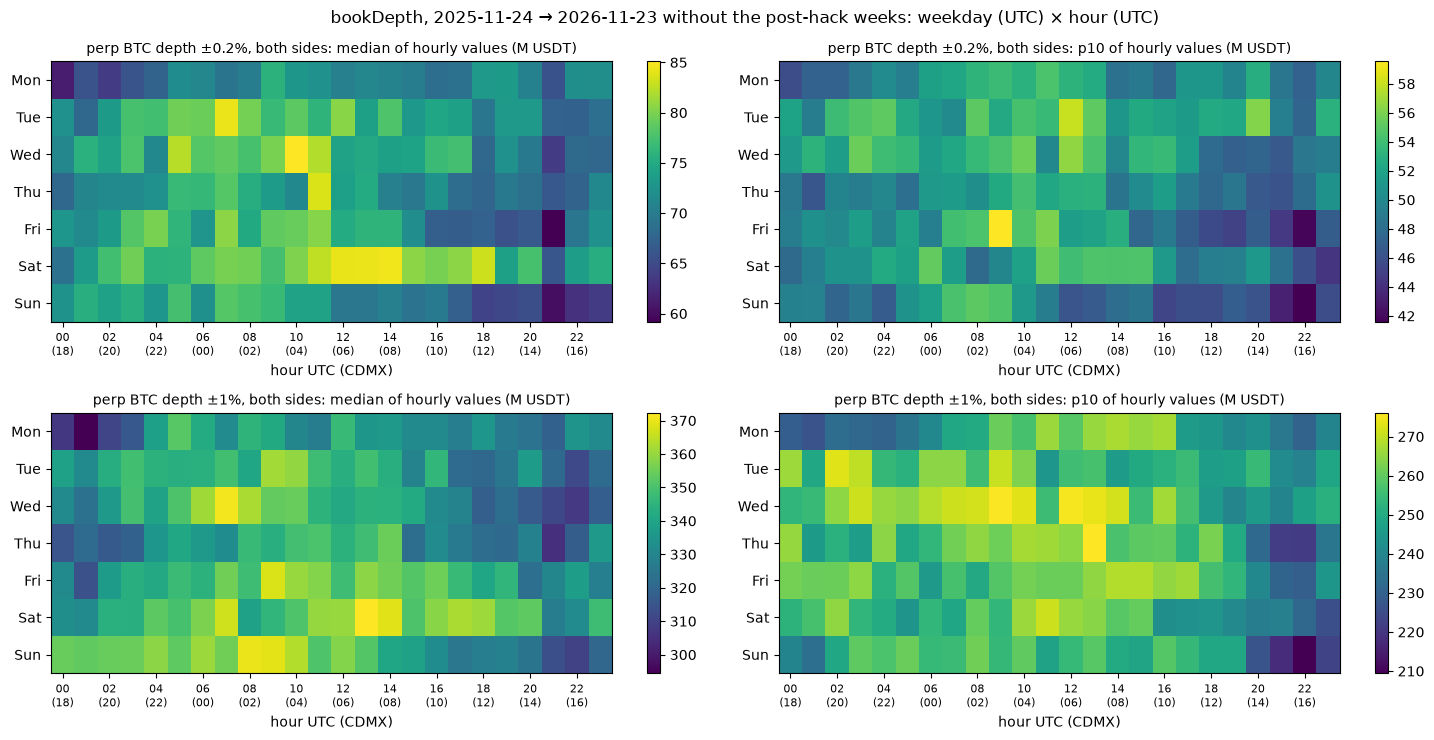

In [29]:
heat = {(col, stat): week_heatmap(normal, col, "median" if stat == "median" else quantile(0.1))
        for col in ("0.2pct_total", "1pct_total") for stat in ("median", "p10")}
fig, axes = plt.subplots(2, 2, figsize=(15, 7.5))
for ax, ((col, stat), table) in zip(axes.ravel(), heat.items()):
    im = ax.imshow(table.to_numpy(), aspect="auto", cmap="viridis")
    ax.set_yticks(range(7))
    ax.set_yticklabels(table.index)
    ax.set_xticks(range(0, 24, 2))
    ax.set_xticklabels([f"{h:02d}\n({int(cdmx_hour(h)):02d})" for h in range(0, 24, 2)], fontsize=8)
    ax.set_xlabel("hour UTC (CDMX)")
    band = col.split("_")[0].replace("pct", "%")
    ax.set_title(f"perp BTC depth ±{band}, both sides: {stat} of hourly values (M USDT)", fontsize=10)
    fig.colorbar(im, ax=ax)
fig.suptitle("bookDepth, 2025-11-24 → 2026-11-23 without the post-hack weeks: weekday (UTC) × hour (UTC)")
fig.tight_layout()
plt.show()

How to read it: four heatmaps. Rows = UTC weekday (Mon at the top), columns = UTC hour (CDMX in
brackets), color = depth in millions of USDT within ±0.2% (top) or ±1% (bottom) of the mid, both
sides added. Left: the **median** hourly value of that cell across the ~50 weeks (a typical
hour); right: the **p10** (one hour in ten was thinner than this: a bad but normal hour). Each
heatmap has its own color scale (bar on the right); bright = deep book, dark = thin book.

hour-of-day shape of the median depth (24 hours, normal period):


,deepest hour,thinnest hour,deepest / thinnest,thinnest vs median hour (%)
0.2pct_total,11 UTC (05 CDMX),21 UTC (15 CDMX),1.227386,-10.549853
1pct_total,09 UTC (03 CDMX),21 UTC (15 CDMX),1.101139,-5.817744


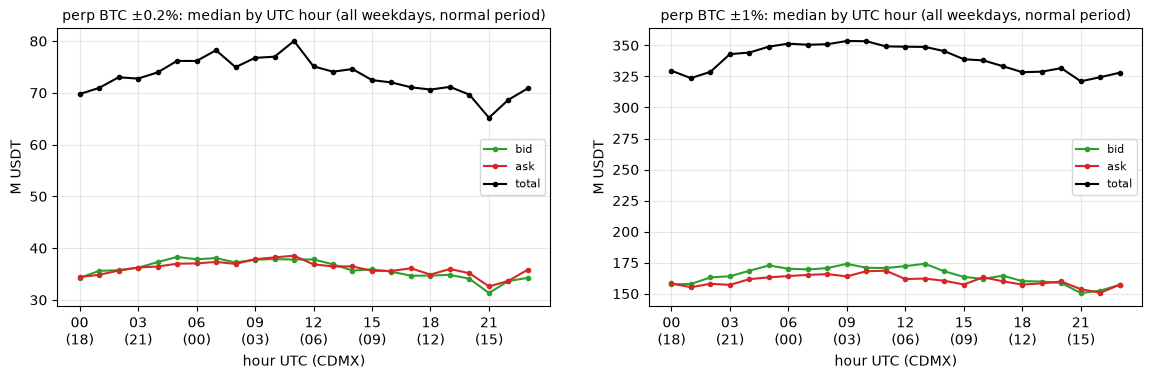

In [30]:
side_profile = normal.groupby("hour_utc")[DEPTH_COLS].median()
HOD = {}
for c in ("0.2pct_total", "1pct_total"):
    prof_c = side_profile[c]
    HOD[c] = {"deepest hour": hour_label(int(prof_c.idxmax())), "thinnest hour": hour_label(int(prof_c.idxmin())),
              "deepest / thinnest": prof_c.max() / prof_c.min(),
              "thinnest vs median hour (%)": 100 * (prof_c.min() / prof_c.median() - 1)}
print("hour-of-day shape of the median depth (24 hours, normal period):")
display(pd.DataFrame(HOD).T.round(3))
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6), sharex=True)
for ax, band in zip(axes, ("0.2pct", "1pct")):
    for part, color in (("bid", "tab:green"), ("ask", "tab:red"), ("total", "black")):
        ax.plot(side_profile.index, side_profile[f"{band}_{part}"], marker=".", color=color, label=part)
    ax.set_title(f"perp BTC ±{band.replace('pct', '%')}: median by UTC hour (all weekdays, normal period)", fontsize=10)
    ax.set_ylabel("M USDT")
    ax.set_xticks(range(0, 24, 3))
    ax.set_xticklabels([f"{h:02d}\n({int(cdmx_hour(h)):02d})" for h in range(0, 24, 3)])
    ax.set_xlabel("hour UTC (CDMX)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.show()

How to read it: x = UTC hour (CDMX), y = median depth in millions of USDT over every normal day
at that hour; green = bids, red = asks, black = both. Left ±0.2%, right ±1%. If the two sides
move together across the day, the hour-of-day pattern is about how much is quoted overall, not
about one side.

In [31]:
heat_all = {c: week_heatmap(normal, c) for c in DEPTH_COLS}
ratios = pd.DataFrame({c: {"Tue 14 UTC (median, M USDT)": t.loc["Tue", 14],
                           "Sun 03 UTC (median, M USDT)": t.loc["Sun", 3],
                           "Tue 14 / Sun 03": t.loc["Tue", 14] / t.loc["Sun", 3],
                           "business 13-21 median (M USDT)": normal.loc[in_window(normal, **BUSINESS), c].median(),
                           "weekend 21-03 median (M USDT)": normal.loc[in_window(normal, **WEEKEND_NIGHT), c].median()}
                       for c, t in heat_all.items()}).T
ratios["business / weekend night"] = ratios["business 13-21 median (M USDT)"] / ratios["weekend 21-03 median (M USDT)"]
print(f"hours behind the general ratio: business {int(in_window(normal, **BUSINESS).sum())}, "
      f"weekend night {int(in_window(normal, **WEEKEND_NIGHT).sum())}")
ratios.round(3)

hours behind the general ratio: business 1904, weekend night 582


,"Tue 14 UTC (median, M USDT)","Sun 03 UTC (median, M USDT)",Tue 14 / Sun 03,business 13-21 median (M USDT),weekend 21-03 median (M USDT),business / weekend night
0.2pct_bid,37.290,36.351,1.026,35.261,33.589,1.050
0.2pct_ask,38.604,37.500,1.029,35.524,34.766,1.022
0.2pct_total,77.984,75.453,1.034,71.744,69.963,1.025
1pct_bid,165.986,167.960,0.988,162.561,158.469,1.026
1pct_ask,162.563,165.065,0.985,157.766,158.762,0.994
1pct_total,343.332,354.605,0.968,335.121,334.064,1.003


How to read it: one row per band and side. The first three columns compare two single cells of
the median heatmap, Tuesday 14 UTC (08 CDMX, Europe and the US both at work) and Sunday 03 UTC
(Saturday 21 CDMX, the quietest stretch of the week); the next three compare the two windows of
H1 (Mon–Fri 13:00–20:59 UTC vs Sat–Sun 21:00–02:59 UTC by UTC day), using the median over every
hour in each window. A ratio above 1 = more depth in the first one.

In [32]:
month_tables = {c: ratio_by_month(normal, c, month_col="month") for c in ("0.2pct_total", "1pct_total", "1pct_bid", "1pct_ask")}
by_month = pd.concat({c: t["ratio"] for c, t in month_tables.items()}, axis=1)
by_month.insert(0, "business hours", month_tables["1pct_total"]["numerator hours"])
by_month.insert(1, "weekend-night hours", month_tables["1pct_total"]["denominator hours"])
RATIO_COLS = ["0.2pct_total", "1pct_total", "1pct_bid", "1pct_ask"]
months_meeting = (by_month[RATIO_COLS] > 1).sum()
months_with_data = by_month[RATIO_COLS].notna().sum()
print("months with business / weekend-night ratio > 1:",
      {c: f"{months_meeting[c]} of {months_with_data[c]}" for c in RATIO_COLS})
by_month.round(3)

months with business / weekend-night ratio > 1: {'0.2pct_total': '8 of 11', '1pct_total': '8 of 12', '1pct_bid': '8 of 12', '1pct_ask': '5 of 12'}


,business hours,weekend-night hours,0.2pct_total,1pct_total,1pct_bid,1pct_ask
month,,,,,,
2025-11-24 to 2025-12-23,176,48,NaN,0.995,1.005,0.973
2025-12-24 to 2026-01-23,184,48,0.875,1.000,0.942,1.004
2026-01-24 to 2026-02-23,168,60,0.959,1.038,1.030,1.053
2026-02-24 to 2026-03-23,152,48,0.983,1.019,0.971,1.017
2026-03-24 to 2026-04-23,176,48,1.041,0.960,1.004,0.940
2026-04-24 to 2026-05-23,168,54,1.075,0.981,0.987,0.943
2026-05-24 to 2026-06-23,176,54,1.151,1.008,1.114,0.858
2026-06-24 to 2026-07-23,176,48,1.044,0.919,1.007,0.918
2026-07-24 to 2026-08-23,168,60,1.029,1.135,1.015,0.976


How to read it: one row per **window month** (24th to 23rd, so the 12 months fit exactly; the last
one is short because the post-hack days are left out; ±0.2% is NaN where the files lack it). The first two columns count the hourly
values behind the ratio; the rest are the ratio business 13–21 / weekend night 21–03 for ±0.2%
total, ±1% total and each side of ±1%. The printed line counts the months where the ratio is
above 1, i.e. where H1's pattern holds in that month.

In [33]:
pct_rows = {}
for c in ("0.2pct_total", "1pct_total"):
    t_med, t_p10 = heat[(c, "median")], heat[(c, "p10")]
    pct_rows[c] = {"Thu 22 UTC median (M USDT)": t_med.loc["Thu", 22],
                   "percentile among the 168 median cells": cell_percentile(t_med, "Thu", 22),
                   "percentile among the 168 p10 cells": cell_percentile(t_p10, "Thu", 22)}
win = bd_clean[(bd_clean.index >= pd.Timestamp(f"{DAY_06} 22:00", tz="UTC"))
               & (bd_clean.index < pd.Timestamp(f"{DAY_06} 22:45", tz="UTC"))] / USDT_M
thu22 = normal[(normal["weekday"] == 3) & (normal["hour_utc"] == 22)
               & (normal["date_utc"] != pd.Timestamp(DAY_06, tz="UTC"))]   # reference without the window itself
for c in ("0.2pct_total", "1pct_total"):
    v = win[c].median()
    pct_rows[c].update({"2026-11-19 22:00-22:45, median (M USDT)": v,
                        "timestamps in that window": len(win),
                        "its percentile among Thu 22 hours": 100 * (thu22[c].dropna() < v).mean(),
                        "Thu 22 hours with data": int(thu22[c].notna().sum()),
                        "its percentile among all normal hours": 100 * (normal[c].dropna() < v).mean()})
m06_window = m06["depth_0.2pct_bid_usdt"] + m06["depth_0.2pct_ask_usdt"]
pct_rows["0.2pct_total"]["notebook 06 collector, same window (M USDT)"] = m06_window.median() / USDT_M
pd.DataFrame(pct_rows).round(3)

,0.2pct_total,1pct_total
Thu 22 UTC median (M USDT),67.480,317.386
percentile among the 168 median cells,14.286,8.929
percentile among the 168 p10 cells,23.214,1.786
"2026-11-19 22:00-22:45, median (M USDT)",81.494,338.420
timestamps in that window,90.000,90.000
its percentile among Thu 22 hours,68.421,64.444
Thu 22 hours with data,38.000,45.000
its percentile among all normal hours,62.972,49.272
"notebook 06 collector, same window (M USDT)",82.544,NaN


How to read it: one column per band (both sides). First, the cell Thursday 22 UTC (16 CDMX, the
hour of notebooks 06 and 07) of the median heatmap and its percentile among the 168 cells (50 =
a middle hour of the week; under 25 = among the thinner hours). Then the depth actually measured
by bookDepth on 2026-11-19 22:00–22:45 UTC (median of its timestamps) and where that falls among
the ~50 Thursday-22 hours of the year and among all normal hours. For ±0.2% the last row is notebook
06's own snapshots of the same window, for comparison.

In [34]:
p10_by_hour = normal.groupby("hour_utc")[["0.2pct_total", "1pct_total"]].quantile(0.1)
worst = {c: int(p10_by_hour[c].idxmin()) for c in p10_by_hour}
worst_cell = {c: heat[(c, "p10")].stack().idxmin() for c in ("0.2pct_total", "1pct_total")}
for c in worst:
    print(f"{c}: worst hour of day (lowest p10) = {hour_label(worst[c])}, p10 = {p10_by_hour[c].min():.2f} M USDT "
          f"(median of p10 over the 24 hours {p10_by_hour[c].median():.2f}); worst weekday x hour cell = "
          f"{worst_cell[c][0]} {hour_label(worst_cell[c][1])}, p10 {heat[(c, 'p10')].stack().min():.2f}")
monthly_p10 = normal.groupby(["month", "hour_utc"])[["0.2pct_total", "1pct_total"]].quantile(0.1)
rows = []
for month, g in monthly_p10.groupby(level="month"):
    g = g.droplevel("month")
    row = {"month": month}
    for c in worst:
        if g[c].isna().all():          # no ±0.2% rows before 2026-01-15
            row[f"{c}: worst hour"] = "no data"
            row[f"{c}: rank of global worst ({worst[c]:02d} UTC), 1 = worst"] = np.nan
            continue
        rank = g[c].rank(method="min")
        row[f"{c}: worst hour"] = hour_label(int(g[c].idxmin()))
        row[f"{c}: rank of global worst ({worst[c]:02d} UTC), 1 = worst"] = int(rank[worst[c]])
    rows.append(row)
worst_by_month = pd.DataFrame(rows).set_index("month")
consistency = {c: {"months where it is the worst hour": int((worst_by_month[f"{c}: rank of global worst ({worst[c]:02d} UTC), 1 = worst"] == 1).sum()),
                   "months where it is in the worst 3": int((worst_by_month[f"{c}: rank of global worst ({worst[c]:02d} UTC), 1 = worst"] <= 3).sum()),
                   "months": int(worst_by_month[f"{c}: rank of global worst ({worst[c]:02d} UTC), 1 = worst"].notna().sum())}
               for c in worst}
print(consistency)
worst_by_month

0.2pct_total: worst hour of day (lowest p10) = 22 UTC (16 CDMX), p10 = 45.17 M USDT (median of p10 over the 24 hours 49.27); worst weekday x hour cell = Sun 22 UTC (16 CDMX), p10 41.60
1pct_total: worst hour of day (lowest p10) = 22 UTC (16 CDMX), p10 = 223.89 M USDT (median of p10 over the 24 hours 250.95); worst weekday x hour cell = Sun 22 UTC (16 CDMX), p10 209.46
{'0.2pct_total': {'months where it is the worst hour': 5, 'months where it is in the worst 3': 10, 'months': 11}, '1pct_total': {'months where it is the worst hour': 3, 'months where it is in the worst 3': 8, 'months': 12}}


,0.2pct_total: worst hour,"0.2pct_total: rank of global worst (22 UTC), 1 = worst",1pct_total: worst hour,"1pct_total: rank of global worst (22 UTC), 1 = worst"
month,,,,
2025-11-24 to 2025-12-23,no data,NaN,22 UTC (16 CDMX),1
2025-12-24 to 2026-01-23,22 UTC (16 CDMX),1.0,22 UTC (16 CDMX),1
2026-01-24 to 2026-02-23,22 UTC (16 CDMX),1.0,23 UTC (17 CDMX),5
2026-02-24 to 2026-03-23,22 UTC (16 CDMX),1.0,22 UTC (16 CDMX),1
2026-03-24 to 2026-04-23,21 UTC (15 CDMX),2.0,21 UTC (15 CDMX),3
2026-04-24 to 2026-05-23,21 UTC (15 CDMX),2.0,21 UTC (15 CDMX),4
2026-05-24 to 2026-06-23,21 UTC (15 CDMX),2.0,21 UTC (15 CDMX),2
2026-06-24 to 2026-07-23,21 UTC (15 CDMX),3.0,23 UTC (17 CDMX),6
2026-07-24 to 2026-08-23,19 UTC (13 CDMX),8.0,21 UTC (15 CDMX),2


How to read it: the printed lines give, per band, the UTC hour of the day whose **p10** depth
(over all normal days) is the lowest, its value, the median p10 of the 24 hours for scale, and the
single worst weekday × hour cell of the p10 heatmap. The table repeats the search month by month
(window months): the worst hour of that month, and the **rank** of the global worst hour within
that month (1 = it was also that month's worst; 24 = that month's best). The dictionary counts in
how many months the global worst hour was the worst, and in how many it was among the worst 3.

### 5.2 Sensitivity: the same key numbers on the raw series (frozen values kept)

In [35]:
def key_numbers(sides, drop_days=()):
    h = resample_hourly(sides)
    h = add_time_labels(h.reset_index().rename(columns={"timestamp_utc": "hour_start_utc"}), "hour_start_utc")
    h = h[h["date_utc"].between(pd.Timestamp(WINDOW_12M[0], tz="UTC"), pd.Timestamp(WINDOW_12M[1], tz="UTC"))
          & ~h["date_utc"].between(*POST_HACK) & ~h["date_utc"].isin(drop_days)]
    h["month"] = window_month(h["date_utc"])
    out = {}
    for c in ("0.2pct_total", "1pct_total"):
        b = h.loc[in_window(h, **BUSINESS), c].median() / h.loc[in_window(h, **WEEKEND_NIGHT), c].median()
        r = ratio_by_month(h, c, month_col="month")["ratio"]
        p10 = h.groupby("hour_utc")[c].quantile(0.1)
        out[c] = {"business / weekend night": round(b, 3),
                  "months with ratio > 1": f"{int((r > 1).sum())} of {int(r.notna().sum())}",
                  "Thu 22 cell percentile (median)": round(cell_percentile(week_heatmap(h, c), "Thu", 22), 1),
                  "worst hour (lowest p10)": hour_label(int(p10.idxmin())),
                  "hourly median (M USDT)": round(h[c].median() / USDT_M, 2)}
    return pd.DataFrame(out)


sensitivity = pd.concat({"cleaned (used)": key_numbers(bd_clean, BAD_DAYS),
                         "frozen values removed, days kept": key_numbers(bd_clean),
                         "raw": key_numbers(bd_sides)}, axis=1)
sensitivity

cleaned (used)                   frozen values removed, days kept                                 raw                  
                                     0.2pct_total        1pct_total                     0.2pct_total        1pct_total      0.2pct_total        1pct_total
business / weekend night                    1.025             1.003                            1.029              1.01             1.028             1.004
months with ratio > 1                     8 of 11           8 of 12                          8 of 11           8 of 12           8 of 11           8 of 12
Thu 22 cell percentile (median)              14.3               8.9                             13.7              13.7              16.1              15.5
worst hour (lowest p10)          22 UTC (16 CDMX)  22 UTC (16 CDMX)                 22 UTC (16 CDMX)  22 UTC (16 CDMX)  21 UTC (15 CDMX)  22 UTC (16 CDMX)
hourly median (M USDT)                      73.01            340.15                            73.26            341.65             74.02             342.9

How to read it: the key numbers of H1 and H2 (and the worst hour) computed three ways: with both rules of section
5.1 (used everywhere in this part), with only rule 1 (frozen values removed but their days kept),
and on the raw series. If the columns of a band agree, the cleaning does not drive the result.

prior 90 days 2026-07-31 -> 2026-10-28 (80 usable days): median daily depth ±0.2% 95.88, ±1% 405.35 M USDT
post-hack 17 days: median of daily ratios ±0.2% 1.077, ±1% 1.051
change of the median daily ±1% depth, post-hack vs prior: +5.1%


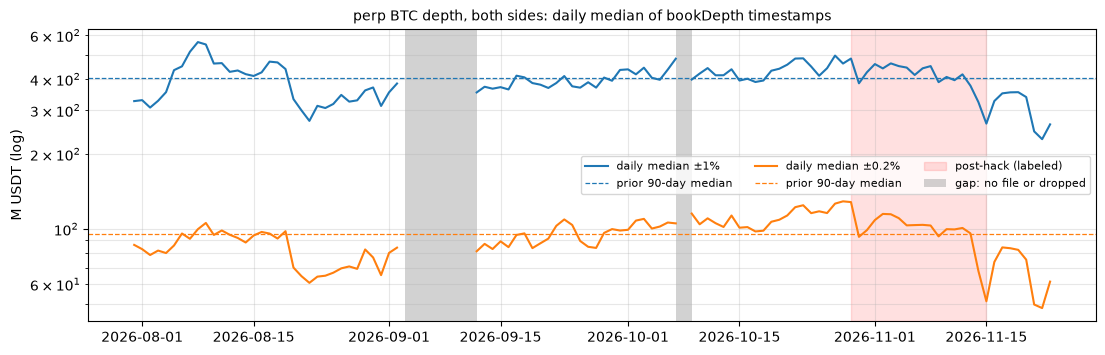

,0.2pct_total,1pct_total,0.2pct_total / prior 90-day median,1pct_total / prior 90-day median
day,,,,
2026-10-29 00:00:00+00:00,128.243,483.916,1.338,1.194
2026-10-30 00:00:00+00:00,92.986,384.858,0.970,0.949
2026-10-31 00:00:00+00:00,98.928,426.134,1.032,1.051
2026-11-01 00:00:00+00:00,108.591,459.728,1.133,1.134
2026-11-02 00:00:00+00:00,114.943,441.674,1.199,1.090
2026-11-03 00:00:00+00:00,114.603,462.704,1.195,1.141
2026-11-04 00:00:00+00:00,110.541,451.173,1.153,1.113
2026-11-05 00:00:00+00:00,103.388,445.008,1.078,1.098
2026-11-06 00:00:00+00:00,103.660,415.669,1.081,1.025


In [36]:
daily_bd = (bd_clean / USDT_M).resample("1D").median()
daily_bd.index.name = "day"
daily_bd.loc[daily_bd.index.isin(BAD_DAYS)] = np.nan          # broken file days (section 5.1)
full_days = pd.date_range(daily_bd.index.min(), daily_bd.index.max(), freq="D", tz="UTC")
daily_bd = daily_bd.reindex(full_days)                         # missing days stay NaN: no interpolation
daily_bd.index.name = "day"


def shade_gaps(ax, lo, hi):
    # Grey band on every gap day (no file or dropped) between lo and hi; label it once.
    first = True
    for d in GAP_DAYS[(GAP_DAYS >= lo) & (GAP_DAYS <= hi)]:
        ax.axvspan(d, d + pd.Timedelta(days=1), color="grey", alpha=0.35, lw=0,
                   label="gap: no file or dropped" if first else None)
        first = False

prior = daily_bd[(daily_bd.index >= POST_HACK[0] - pd.Timedelta(days=90)) & (daily_bd.index < POST_HACK[0])].dropna(how="all")
prior_median = prior.median()
hack_days = daily_bd[(daily_bd.index >= POST_HACK[0]) & (daily_bd.index <= POST_HACK[1])]
hack_table = pd.DataFrame({c: hack_days[c] for c in ("0.2pct_total", "1pct_total")})
for c in ("0.2pct_total", "1pct_total"):
    hack_table[f"{c} / prior 90-day median"] = hack_days[c] / prior_median[c]
print(f"prior 90 days {prior.index.min():%Y-%m-%d} -> {prior.index.max():%Y-%m-%d} ({len(prior)} usable days): median daily depth "
      f"±0.2% {prior_median['0.2pct_total']:.2f}, ±1% {prior_median['1pct_total']:.2f} M USDT")
print(f"post-hack {len(hack_days)} days: median of daily ratios ±0.2% "
      f"{hack_table['0.2pct_total / prior 90-day median'].median():.3f}, ±1% "
      f"{hack_table['1pct_total / prior 90-day median'].median():.3f}")
HACK_CHANGE_PCT = 100 * (hack_days["1pct_total"].median() / prior_median["1pct_total"] - 1)
print(f"change of the median daily ±1% depth, post-hack vs prior: {HACK_CHANGE_PCT:+.1f}%")

fig, ax = plt.subplots(figsize=(13, 3.8))
view = daily_bd[daily_bd.index >= POST_HACK[0] - pd.Timedelta(days=90)]
for c, color in (("1pct_total", "tab:blue"), ("0.2pct_total", "tab:orange")):
    ax.plot(view.index, view[c], color=color, label=f"daily median ±{c.split('_')[0].replace('pct', '%')}")
    ax.axhline(prior_median[c], color=color, ls="--", lw=0.9, label="prior 90-day median")
ax.axvspan(POST_HACK[0], POST_HACK[1] + pd.Timedelta(days=1), color="red", alpha=0.12, label="post-hack (labeled)")
shade_gaps(ax, view.index.min(), view.index.max())
ax.set_yscale("log")
ax.set_ylabel("M USDT (log)")
ax.set_title("perp BTC depth, both sides: daily median of bookDepth timestamps", fontsize=10)
ax.legend(fontsize=8, ncol=3)
ax.grid(alpha=0.3, which="both")
plt.show()
hack_table.round(3)

How to read it: the first line is the reference, the median daily depth of the 90 days before
2026-10-29 (gap days are left out, so the count of usable days is printed); the second, the median over the post-hack days of each day's depth divided by that
reference (1 = no change, 0.7 = 30% less). The plot shows the daily median depth (solid, log
scale, M USDT) from 90 days before the period to the end of the window, the reference as dashed
lines and the post-hack period shaded red; grey bands are gap days (section 5.1b), where the line
is broken on purpose. The table lists each post-hack day with its depth and ratio to the reference.

### 5.3 The same depth in BTC (post-inspection, at the owner's request)

A depth in USDT also moves when the price moves: the same number of BTC on the book is worth fewer
USDT after a fall. Here each bookDepth row is divided by the **perp's last traded price known at
that moment**: the close of the last **completed** 1-minute candle of USDⓈ-M BTCUSDT
(data.binance.vision), i.e. the candle that closed at or before the row's timestamp, never the
candle still forming (no look-ahead). Daily medians, August → November 2026.

perp 1-min candles 2026-08-01 -> 2026-11-23 23:59, 165,600; bookDepth rows without a price: 2 of 325,288; median age of the price used: 23 s


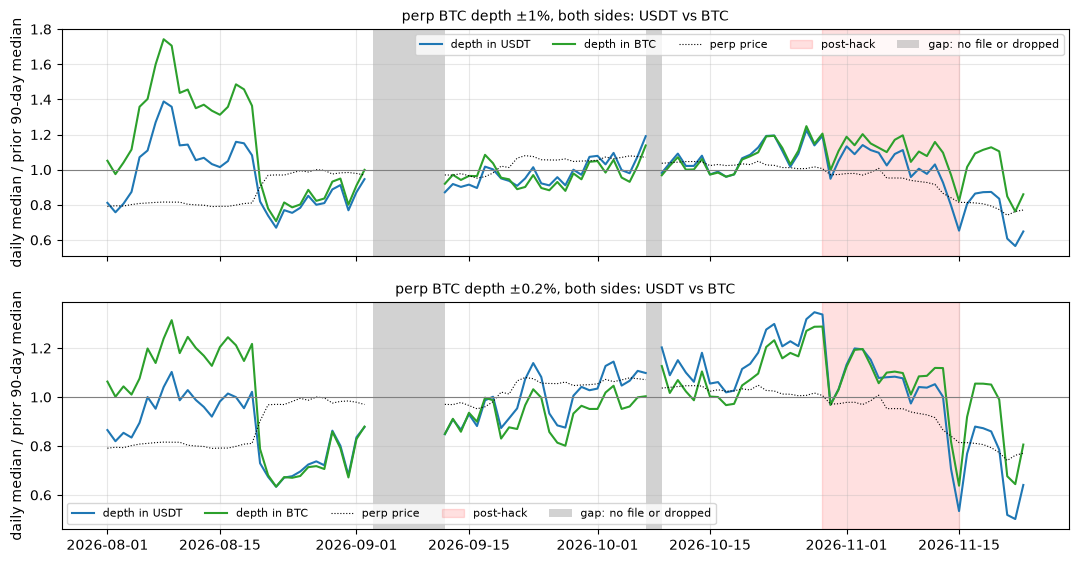

,prior 90 days (median of daily),2026-11-15 -> 11-23 (median of daily),change (%)
±1% depth (USDT),4.058229e+08,3.266276e+08,-19.515
±1% depth (BTC),4.974489e+03,5.048834e+03,1.495
±0.2% depth (USDT),9.590361e+07,7.370266e+07,-23.149
±0.2% depth (BTC),1.239714e+03,1.139024e+03,-8.122
perp price (USDT),7.964260e+04,6.318145e+04,-20.669


In [37]:
perp_k = pd.concat([read_klines_zip(VISION / futures_klines_path("BTCUSDT", "1m", p))
                    for p in klines_periods("2026-08-01", "2026-11-23")]).sort_index()
assert perp_k.index.is_unique
perp_close = pd.DataFrame({"close_time": perp_k.index + pd.Timedelta(minutes=1),   # when the close is known
                           "price": perp_k["close"].to_numpy()})
span = bd_clean[(bd_clean.index >= pd.Timestamp("2026-08-01", tz="UTC"))
                & (bd_clean.index < pd.Timestamp("2026-11-24", tz="UTC"))].copy()
span = pd.merge_asof(span.reset_index(), perp_close.astype({"close_time": "datetime64[ms, UTC]"}),
                     left_on="timestamp_utc", right_on="close_time", direction="backward",
                     tolerance=pd.Timedelta(minutes=2)).set_index("timestamp_utc")
print(f"perp 1-min candles {perp_k.index.min():%Y-%m-%d} -> {perp_k.index.max():%Y-%m-%d %H:%M}, {len(perp_k):,}; "
      f"bookDepth rows without a price: {int(span['price'].isna().sum())} of {len(span):,}; "
      f"median age of the price used: {(span.index - span['close_time']).dt.total_seconds().median():.0f} s")
for c in ("0.2pct_total", "1pct_total"):
    span[f"{c}_btc"] = span[c] / span["price"]
daily_btc = span[["1pct_total", "1pct_total_btc", "0.2pct_total", "0.2pct_total_btc", "price"]].resample("1D").median()
daily_btc = daily_btc.reindex(pd.date_range("2026-08-01", "2026-11-23", freq="D", tz="UTC"))
daily_btc.loc[daily_btc.index.isin(BAD_DAYS)] = np.nan

ref = daily_btc[(daily_btc.index >= POST_HACK[0] - pd.Timedelta(days=90)) & (daily_btc.index < POST_HACK[0])].median()
mid_nov = daily_btc[(daily_btc.index >= pd.Timestamp("2026-11-15", tz="UTC"))].median()
btc_vs_usdt = pd.DataFrame({"prior 90 days (median of daily)": ref, "2026-11-15 -> 11-23 (median of daily)": mid_nov})
btc_vs_usdt["change (%)"] = 100 * (btc_vs_usdt.iloc[:, 1] / btc_vs_usdt.iloc[:, 0] - 1)
btc_vs_usdt.index = ["±1% depth (USDT)", "±1% depth (BTC)", "±0.2% depth (USDT)", "±0.2% depth (BTC)", "perp price (USDT)"]

fig, axes = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True)
for ax, band in zip(axes, ("1pct_total", "0.2pct_total")):
    for col, label, color in ((band, "USDT", "tab:blue"), (f"{band}_btc", "BTC", "tab:green")):
        ax.plot(daily_btc.index, daily_btc[col] / ref[col], color=color, label=f"depth in {label}")
    ax.plot(daily_btc.index, daily_btc["price"] / ref["price"], color="black", lw=0.8, ls=":", label="perp price")
    ax.axhline(1, color="grey", lw=0.8)
    ax.axvspan(POST_HACK[0], POST_HACK[1] + pd.Timedelta(days=1), color="red", alpha=0.12, label="post-hack")
    shade_gaps(ax, daily_btc.index.min(), daily_btc.index.max())
    ax.set_ylabel("daily median / prior 90-day median")
    ax.set_title(f"perp BTC depth ±{band.split('_')[0].replace('pct', '%')}, both sides: USDT vs BTC", fontsize=10)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, ncol=5)
plt.show()
btc_vs_usdt.round(3)

How to read it: the first line checks the price series (candles, rows left without a price, how old
the price is on average). Each panel shows the daily median depth **in USDT** (blue) and **in BTC**
(green), both divided by their own median over the 90 days before the hack window (1 = as usual),
and the perp price on the same scale (dotted). If the USDT line falls and the BTC line does not,
the fall comes from the price; if both fall, there were fewer BTC on the book. Grey bands are gap
days, red the post-hack window. The table compares the median of the daily values from 2026-11-15
(the day after the post-hack window) to 2026-11-23 with the prior 90 days, in USDT, in BTC, and
for the price.

### 5.4 Sensitivity of H1 and H2 to the post-hack window

H1 and H2 recomputed (a) with the post-hack window excluded as fixed before looking
(2026-10-29 → 11-14), and (b) also excluding **2026-11-15 → 2026-11-23**, the days right after it.
Both also leave out the dropped days of section 5.1.

In [38]:
LATE_NOV = pd.date_range("2026-11-15", "2026-11-23", freq="D", tz="UTC")
post_hack_sens = pd.concat({"(a) post-hack excluded": key_numbers(bd_clean, BAD_DAYS),
                            "(b) also 11-15 -> 11-23 excluded": key_numbers(bd_clean, BAD_DAYS.union(LATE_NOV))},
                           axis=1)
for label, frame in (("(a)", bd_h[bd_h["period"] == "normal"]),
                     ("(b)", bd_h[(bd_h["period"] == "normal") & ~bd_h["date_utc"].isin(LATE_NOV)])):
    t = week_heatmap(frame, "1pct_total")
    print(f"{label} Tue 14 / Sun 03 (±1%): {t.loc['Tue', 14] / t.loc['Sun', 3]:.3f}; normal hours: {len(frame)}")
post_hack_sens

(a) Tue 14 / Sun 03 (±1%): 0.968; normal hours: 8039
(b) Tue 14 / Sun 03 (±1%): 0.953; normal hours: 7823


(a) post-hack excluded                   (b) also 11-15 -> 11-23 excluded                  
                                          0.2pct_total        1pct_total                     0.2pct_total        1pct_total
business / weekend night                         1.025             1.003                            0.993             0.993
months with ratio > 1                          8 of 11           8 of 12                          8 of 11           8 of 12
Thu 22 cell percentile (median)                   14.3               8.9                             12.5               4.2
worst hour (lowest p10)               22 UTC (16 CDMX)  22 UTC (16 CDMX)                 21 UTC (15 CDMX)  22 UTC (16 CDMX)
hourly median (M USDT)                           73.01            340.15                            73.09            341.46

How to read it: the printed lines give the Tuesday-14 / Sunday-03 ratio (±1%) and how many normal
hours each version keeps. The table has the H1 numbers (ratio weekdays 13–21 / weekend nights
21–03, months with a ratio above 1) and the H2 number (percentile of the Thursday-22 cell), plus
the worst hour and the median hourly depth, under each exclusion. If (a) and (b) agree, the days
after the hack window do not drive H1 or H2.

### 5.5 The 10 October 2025 case: what is in the raw files?

The hourly series below loses the bids (and so the total) after the crash. Before reading it, the
raw files are checked: rows per percentage, rows per timestamp, and how many **distinct** values
each percentage takes per day. Missing rows would mean the source lacks data; rows that are present
but repeat one value would mean the source is frozen; neither would be a bug in this notebook.

In [39]:
raw_rows = []
for day in pd.date_range("2025-10-09", STRESS_10_10[1], freq="D"):
    r = read_book_depth_day(day.strftime("%Y-%m-%d"))
    per_ts = r.groupby("timestamp_utc").size()
    row = {"day": day.strftime("%Y-%m-%d"), "timestamps": r["timestamp_utc"].nunique(),
           "rows per timestamp": "/".join(str(x) for x in sorted(per_ts.unique())),
           "percentages": len(r["percentage"].unique())}
    for pct in (-5, -3, -1, 1, 5):
        g = r[r["percentage"] == pct]
        row[f"rows at {pct:+d}%"] = len(g)
        row[f"distinct {pct:+d}%"] = g["notional"].nunique()
    row["median depth at -1% (BTC)"] = r.loc[r["percentage"] == -1, "depth"].median()
    row["median depth at +1% (BTC)"] = r.loc[r["percentage"] == 1, "depth"].median()
    raw_rows.append(row)
raw_check = pd.DataFrame(raw_rows).set_index("day")
raw_check.T

day,2025-10-09,2025-10-10,2025-10-11,2025-10-12,2025-10-13,2025-10-14,2025-10-15
timestamps,2821,2879,2845,2812,2812,2815,2795
rows per timestamp,10,10,10,10,10,10,10
percentages,10,10,10,10,10,10,10
rows at -5%,2821,2879,2845,2812,2812,2815,2795
distinct -5%,2821,2865,2824,2665,2811,2811,2794
rows at -3%,2821,2879,2845,2812,2812,2815,2795
distinct -3%,2821,2565,1,457,2347,213,1254
rows at -1%,2821,2879,2845,2812,2812,2815,2795
distinct -1%,2821,1929,1,1,1,1,1254
rows at +1%,2821,2879,2845,2812,2812,2815,2795


How to read it: one column per day (the day before the crash, the crash day, and the days after).
`timestamps` and `rows per timestamp` say whether rows are missing (10 rows per timestamp = one per
percentage, the format of that period). For −5%, −3%, −1%, +1% and +5%: how many rows the day has
and how many **different** values they take. A side whose value never changes has 1 distinct value
over thousands of rows. The last two rows are the median depth in BTC at −1% and +1%.

**Verdict:** this decides whether the missing bids come from the source or from the code; it is
stated in the key takeaways with the numbers of this table.

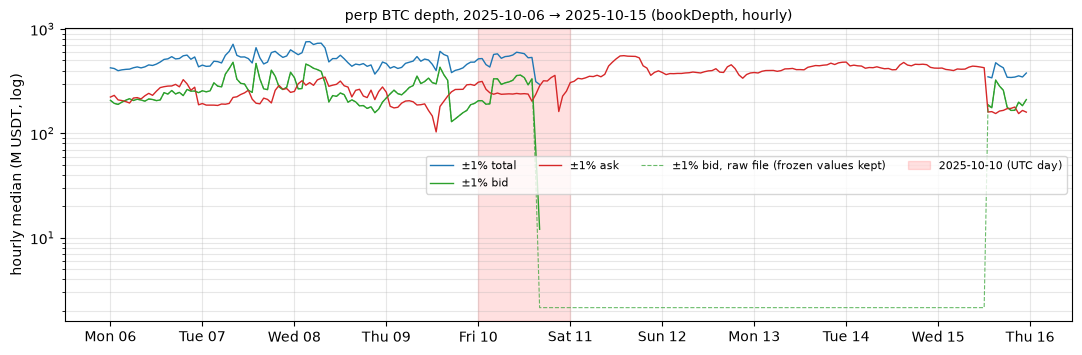

±1% asks, 10-11 Oct vs 6-9 Oct (bids and total: not measurable, see section 5.5):
{'min vs min (%)': np.float64(-13.2), 'median vs median (%)': np.float64(40.7), 'percentile vs normal days': np.float64(85.7)}
thinnest ask hour of 10-11 Oct: 161.9 M USDT; thinnest ask hour per day, 6-9 Oct: [187.9, 185.2, 210.5, 103.2]; normal days (12 months): median of daily thinnest hour 125.0, p10 98.5 M USDT


,1pct_total median,1pct_bid median,1pct_ask median,1pct_total min hour,1pct_bid min hour,1pct_ask min hour
hour_start_utc,,,,,,
2025-10-06 00:00:00+00:00,450.02,212.89,236.56,398.50,189.50,187.92
2025-10-07 00:00:00+00:00,536.43,290.30,212.11,438.46,247.05,185.17
2025-10-08 00:00:00+00:00,519.57,228.28,284.12,369.66,157.92,210.53
2025-10-09 00:00:00+00:00,467.72,255.82,201.84,382.00,129.47,103.23
2025-10-10 00:00:00+00:00,533.73,304.87,240.71,293.94,12.07,161.89
2025-10-11 00:00:00+00:00,NaN,NaN,390.74,NaN,NaN,306.71
2025-10-12 00:00:00+00:00,NaN,NaN,381.91,NaN,NaN,337.50
2025-10-13 00:00:00+00:00,NaN,NaN,415.15,NaN,NaN,378.88
2025-10-14 00:00:00+00:00,NaN,NaN,442.03,NaN,NaN,406.46


In [40]:
stress_h = bd_h[bd_h["period"] == "10/10 case"].set_index("hour_start_utc")
raw_h = resample_hourly(bd_sides[bd_sides.index < pd.Timestamp(WINDOW_12M[0], tz="UTC")])[["1pct_bid", "1pct_total"]] / USDT_M
fig, ax = plt.subplots(figsize=(13, 3.8))
for c, color in (("1pct_total", "tab:blue"), ("1pct_bid", "tab:green"), ("1pct_ask", "tab:red")):
    ax.plot(stress_h.index, stress_h[c], color=color, lw=1, label=f"±{c.replace('pct_', '% ')}")
ax.plot(raw_h.index, raw_h["1pct_bid"], color="tab:green", lw=0.8, ls="--", alpha=0.7,
        label="±1% bid, raw file (frozen values kept)")
ten = pd.Timestamp("2025-10-10", tz="UTC")
ax.axvspan(ten, ten + pd.Timedelta(days=1), color="red", alpha=0.12, label="2025-10-10 (UTC day)")
ax.set_yscale("log")
ax.set_ylabel("hourly median (M USDT, log)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d", tz="UTC"))
ax.set_title("perp BTC depth, 2025-10-06 → 2025-10-15 (bookDepth, hourly)", fontsize=10)
ax.legend(fontsize=8, ncol=4)
ax.grid(alpha=0.3, which="both")
plt.show()
ten_days = stress_h.groupby(stress_h.index.floor("D")).agg(
    **{f"{c} median": (c, "median") for c in ("1pct_total", "1pct_bid", "1pct_ask")},
    **{f"{c} min hour": (c, "min") for c in ("1pct_total", "1pct_bid", "1pct_ask")})
# Like with like (post-review): the thinnest hour of a day against the thinnest hours of other days,
# and a day's median hour against other days' median hours. Asks only: the bids are frozen.
ask_min = stress_h["1pct_ask"].groupby(stress_h.index.floor("D")).min()
ask_med = stress_h["1pct_ask"].groupby(stress_h.index.floor("D")).median()
pre = ask_min.index < pd.Timestamp("2025-10-10", tz="UTC")
crash_days = (ask_min.index >= pd.Timestamp("2025-10-10", tz="UTC")) & (ask_min.index < pd.Timestamp("2025-10-12", tz="UTC"))
normal_day_min = normal.groupby("date_utc")["1pct_ask"].min()
crash_min = ask_min[crash_days].min()
TEN_CHANGE = {"min vs min (%)": 100 * (crash_min / ask_min[pre].median() - 1),
              "median vs median (%)": 100 * (ask_med[crash_days].median() / ask_med[pre].median() - 1),
              "percentile vs normal days": 100 * (normal_day_min < crash_min).mean()}
print("±1% asks, 10-11 Oct vs 6-9 Oct (bids and total: not measurable, see section 5.5):")
print({k: round(v, 1) for k, v in TEN_CHANGE.items()})
print(f"thinnest ask hour of 10-11 Oct: {crash_min:.1f} M USDT; thinnest ask hour per day, 6-9 Oct: "
      f"{[round(v, 1) for v in ask_min[pre]]}; normal days (12 months): median of daily thinnest hour "
      f"{normal_day_min.median():.1f}, p10 {normal_day_min.quantile(0.1):.1f} M USDT")
ten_days.round(2)

How to read it: the plot shows the hourly median depth of the perp from 2025-10-06 to 2025-10-15
(log scale, M USDT): ±1% both sides (blue), ±1% bids alone (green, the side a forced seller
hits) and ±1% asks (red); the dashed green line is the raw bid series with the frozen values kept,
so the reader can see what the cleaning removed. The 2025 files have no ±0.2% rows. Where a line stops, that side was
**frozen** in the file (section 5.1) and is not shown: where the green line stops and the
dashed line goes flat, the bids are frozen, so **the bid side during that stretch cannot be
measured from bookDepth**, and the bid values just before the freeze (the drop at 15–16 UTC) look
like the start of the same fault, not a measurement to trust. The UTC day of 10 October 2025 is shaded. The printed lines give the H6 number for this case, comparing like with like on the ±1% asks: the
thinnest hour of 10–11 October against the median of the thinnest hours of 6–9 October, the median
hour of 10–11 October against that of 6–9 October, and where the 10–11 October thinnest hour falls
among the thinnest hours of every normal day of the 12 months. The table has one row per day: the
median hourly depth and the thinnest hour of that day.

## 6. Part 4 · Volume ≠ liquidity (1-minute spot candles, BTCUSDT and ETHUSDT)

**Volume** (USDT traded) and **range** ((high − low) / close of each hourly candle) describe
**activity and movement**, not cost: they say how much was traded and how far the price moved,
not how much could be traded at a given price. Same 12 months and same exclusion of the
post-hack weeks as Part 3. Hourly candles are built from the 1-minute ones.

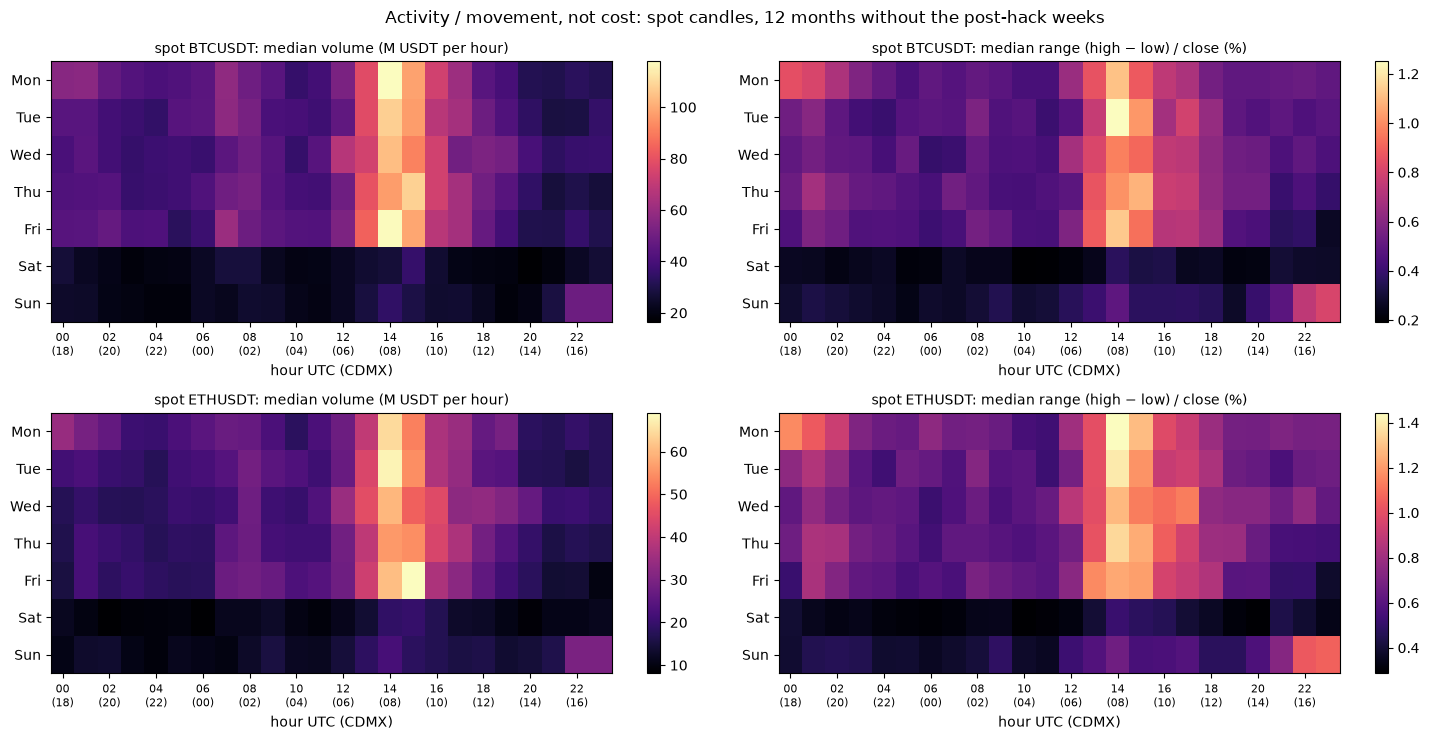

{'BTCUSDT': 8352, 'ETHUSDT': 8352} hourly candles


In [41]:
def hourly_candles(k):
    g = k.resample("1h")
    h = pd.DataFrame({"high": g["high"].max(), "low": g["low"].min(), "close": g["close"].last(),
                      "quote_volume": g["quote_volume"].sum(), "minutes": g.size()})
    h = h[h["minutes"] > 0]
    h["range_pct"] = (h["high"] - h["low"]) / h["close"] * 100
    h["volume_musdt"] = h["quote_volume"] / USDT_M
    h = add_time_labels(h.reset_index(), "open_time_utc")
    return h[~h["date_utc"].between(*POST_HACK)]


candles_h = {s: hourly_candles(k) for s, k in klines.items()}
fig, axes = plt.subplots(2, 2, figsize=(15, 7.5))
for row, (sym, h) in enumerate(candles_h.items()):
    for col, (c, title) in enumerate((("volume_musdt", "volume (M USDT per hour)"),
                                      ("range_pct", "range (high − low) / close (%)"))):
        t = week_heatmap(h, c)
        ax = axes[row, col]
        im = ax.imshow(t.to_numpy(), aspect="auto", cmap="magma")
        ax.set_yticks(range(7))
        ax.set_yticklabels(t.index)
        ax.set_xticks(range(0, 24, 2))
        ax.set_xticklabels([f"{x:02d}\n({int(cdmx_hour(x)):02d})" for x in range(0, 24, 2)], fontsize=8)
        ax.set_xlabel("hour UTC (CDMX)")
        ax.set_title(f"spot {sym}: median {title}", fontsize=10)
        fig.colorbar(im, ax=ax)
fig.suptitle("Activity / movement, not cost: spot candles, 12 months without the post-hack weeks")
fig.tight_layout()
plt.show()
print({s: len(h) for s, h in candles_h.items()}, "hourly candles")

How to read it: four heatmaps with the same layout as Part 3 (rows = UTC weekday, columns = UTC
hour with CDMX in brackets). Left: median USDT traded per hour (millions); right: median hourly
range in % of the price. Top BTC, bottom ETH. Bright = more volume / bigger moves. These are
**not** depth: compare where they are bright with where Part 3's depth heatmaps are bright.

,,points,Pearson corr,rank corr
comparison,perp depth band,,,
"volume vs depth, 24 hours",0.2% total,24,0.142,0.256
"range vs depth, 24 hours",0.2% total,24,-0.129,-0.430
"volume vs depth, 168 hour-of-week cells",0.2% total,168,-0.074,-0.098
"volume vs depth, 24 hours",1% total,24,0.229,0.260
"range vs depth, 24 hours",1% total,24,-0.053,-0.410
"volume vs depth, 168 hour-of-week cells",1% total,168,-0.098,-0.198


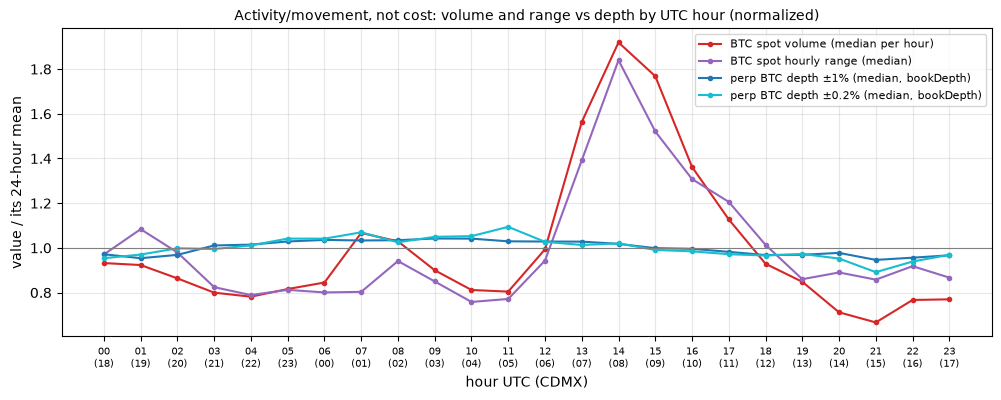

In [42]:
btc_h = candles_h["BTCUSDT"]
vol_prof = btc_h.groupby("hour_utc")["volume_musdt"].median()
rng_prof = btc_h.groupby("hour_utc")["range_pct"].median()
dep_prof = normal.groupby("hour_utc")[["0.2pct_total", "1pct_total"]].median()
vol_week = week_heatmap(btc_h, "volume_musdt").stack()
dep_week = {c: heat_all[c].stack() for c in ("0.2pct_total", "1pct_total")}
rows = []
for c in ("0.2pct_total", "1pct_total"):
    for name, x, y in (("volume vs depth, 24 hours", vol_prof, dep_prof[c]),
                       ("range vs depth, 24 hours", rng_prof, dep_prof[c]),
                       ("volume vs depth, 168 hour-of-week cells", vol_week, dep_week[c])):
        rows.append({"comparison": name, "perp depth band": c.replace("pct_", "% "), "points": len(x),
                     "Pearson corr": x.corr(y), "rank corr": x.rank().corr(y.rank())})
vol_vs_depth = pd.DataFrame(rows).set_index(["comparison", "perp depth band"])
display(vol_vs_depth.round(3))

fig, ax = plt.subplots(figsize=(12, 4))
for s, label, color in ((vol_prof, "BTC spot volume (median per hour)", "tab:red"),
                        (rng_prof, "BTC spot hourly range (median)", "tab:purple"),
                        (dep_prof["1pct_total"], "perp BTC depth ±1% (median, bookDepth)", "tab:blue"),
                        (dep_prof["0.2pct_total"], "perp BTC depth ±0.2% (median, bookDepth)", "tab:cyan")):
    ax.plot(s.index, s / s.mean(), marker=".", color=color, label=label)
ax.axhline(1, color="grey", lw=0.8)
ax.set_xticks(range(24))
ax.set_xticklabels([f"{h:02d}\n({int(cdmx_hour(h)):02d})" for h in range(24)], fontsize=7)
ax.set_xlabel("hour UTC (CDMX)")
ax.set_ylabel("value / its 24-hour mean")
ax.set_title("Activity/movement, not cost: volume and range vs depth by UTC hour (normalized)", fontsize=10)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.show()

How to read it: the table correlates the **hour-of-day profiles** (24 points: the median of each
UTC hour over the normal 12 months) of BTC spot volume and range with the perp's depth, and the
168 weekday × hour medians of volume with those of depth. +1 = depth is high exactly when volume
is high; negative = depth is lower when volume is higher. Points are hours of the day, not
independent observations, so the correlations describe the shape of the profiles and are not a
test. The plot divides each profile by its own 24-hour mean so they share one axis: 1.5 = 50%
above that series' average hour.

## 7. Findings

### 7.1 Sunday (normal) vs Monday (stress), per day

The daily view behind H7: for each market and day of the run, the median spread (bps and ticks),
the median depth within ±0.1% and ±1%, and the median book part of the taker → taker round trip at
the smallest and largest size of Part 2.

In [43]:
day_rows = []
for (market, day), g in run.groupby(["market", "day"]):
    r_ = rt_run[(rt_run["market"] == market) & (rt_run["day"] == day)]
    small, large = min(SIZES[market]), max(SIZES[market])
    day_rows.append({"market": market, "day": day,
                     "spread median (bps)": g["spread_bps"].median(),
                     "spread median (ticks)": g["spread_ticks"].median(),
                     "at 1 tick (%)": 100 * g["at_one_tick"].mean(),
                     "depth ±0.1% median (M USDT)": g["depth_0.1pct_total_usdt"].median() / USDT_M,
                     "depth ±1% median (M USDT)": g["depth_1pct_total_usdt"].median() / USDT_M,
                     f"book part, smallest size (bps)": r_.loc[r_["size_usdt"] == small, "book_bps"].median(),
                     f"book part, largest size (bps)": r_.loc[r_["size_usdt"] == large, "book_bps"].median(),
                     "sizes (USDT)": f"{small:,.0f} / {large:,.0f}"})
by_day = pd.DataFrame(day_rows).set_index(["market", "day"]).reindex(MARKETS, level=0)
ratio_day = by_day.xs(DAYS[1], level="day").drop(columns="sizes (USDT)") / by_day.xs(DAYS[0], level="day").drop(columns="sizes (USDT)")
display(by_day.round(4))
print(f"{DAYS[1]} ÷ {DAYS[0]}:")
ratio_day.round(3)

spread median (bps)  spread median (ticks)  at 1 tick (%)  depth ±0.1% median (M USDT)  depth ±1% median (M USDT)  \
market             day                                                                                                                                          
spot BTC/USDT      Mon 2026-11-23 (stress)               0.0016                    1.0        99.5833                       7.9574                    22.3299   
                   Sun 2026-11-22 (normal)               0.0016                    1.0       100.0000                       7.4787                    20.5085   
spot ETH/USDT      Mon 2026-11-23 (stress)               0.0580                    1.0        99.8611                       4.2782                    15.4248   
                   Sun 2026-11-22 (normal)               0.0586                    1.0        99.7917                       4.1766                    15.2853   
spot PENGU/USDT    Mon 2026-11-23 (stress)               2.3002                    1.0        89.0278                       0.0176                     0.2866   
                   Sun 2026-11-22 (normal)               2.3493                    1.0        92.2917                       0.0168                     0.2999   
perp BTC/USDT:USDT Mon 2026-11-23 (stress)               0.0163                    1.0        99.1667                      25.7521                    69.0194   
                   Sun 2026-11-22 (normal)               0.0165                    1.0        99.6528                      19.4608                    57.2469   

                                            book part, smallest size (bps)  book part, largest size (bps)        sizes (USDT)  
market             day                                                                                                         
spot BTC/USDT      Mon 2026-11-23 (stress)                          0.0016                         2.7309  10,000 / 1,000,000  
                   Sun 2026-11-22 (normal)                          0.0017                         2.7723  10,000 / 1,000,000  
spot ETH/USDT      Mon 2026-11-23 (stress)                          0.0581                         5.4447  10,000 / 1,000,000  
                   Sun 2026-11-22 (normal)                          0.0595                         5.6164  10,000 / 1,000,000  
spot PENGU/USDT    Mon 2026-11-23 (stress)                          6.4273                        62.8355     1,000 / 100,000  
                   Sun 2026-11-22 (normal)                          6.8364                        55.1517     1,000 / 100,000  
perp BTC/USDT:USDT Mon 2026-11-23 (stress)                          0.0163                         1.6840  10,000 / 1,000,000  
                   Sun 2026-11-22 (normal)                          0.0165                         2.0271  10,000 / 1,000,000

Mon 2026-11-23 (stress) ÷ Sun 2026-11-22 (normal):


,spread median (bps),spread median (ticks),at 1 tick (%),depth ±0.1% median (M USDT),depth ±1% median (M USDT),"book part, smallest size (bps)","book part, largest size (bps)"
market,,,,,,,
spot BTC/USDT,0.989,1.0,0.996,1.064,1.089,0.983,0.985
spot ETH/USDT,0.990,1.0,1.001,1.024,1.009,0.976,0.969
spot PENGU/USDT,0.979,1.0,0.965,1.050,0.956,0.940,1.139
perp BTC/USDT:USDT,0.989,1.0,0.995,1.323,1.206,0.989,0.831


How to read it: first table, one row per market and day (each day carries its label from Part 0).
Spread as median in bps and ticks and the share of snapshots at one tick; median depth within
±0.1% and ±1% (perp ±1% = collector lower bound); median book part (spread + impact) of the round
trip at the market's smallest and largest size (listed in the last column). Second table: Monday ÷
Sunday for each measure (1 = same; above 1 = larger on the stress day).

### 7.2 Findings table

One row per question of the introduction: the numbers measured, how many observations they rest
on, and what is measured versus assumed. **No prior hypotheses were recorded for this notebook**,
so these are answers to questions, not tests of beliefs, and no causes are claimed.

In [44]:
c1 = "1pct_total"
tue_sun = ratios.loc[c1, "Tue 14 / Sun 03"]


def cost_span(market, size):
    r = cost_range.loc[(market, f"{size:,.0f}")]
    return (f"{r['spread+impact: lowest hourly median (bps)']:.3f}-"
            f"{r['spread+impact: highest hourly median (bps)']:.3f}")


pengu_1m = fill_table(pengu_rt).loc["1,000,000"]
findings = pd.DataFrame([
    {"H": "H1", "question": "Does perp depth change with the hour of the week?",
     "measured": f"hour-of-day shape: deepest / thinnest hour ±1% {HOD[c1]['deepest / thinnest']:.2f}, ±0.2% "
                 f"{HOD['0.2pct_total']['deepest / thinnest']:.2f} (thinnest {HOD[c1]['thinnest hour']}); "
                 f"Tue 14 / Sun 03 UTC (±1%) {tue_sun:.2f}; weekdays 13-21 / weekend nights 21-03: ±1% "
                 f"{ratios.loc[c1, 'business / weekend night']:.3f}, ±0.2% {ratios.loc['0.2pct_total', 'business / weekend night']:.3f}; "
                 f"months with ratio > 1: ±1% {months_meeting[c1]} of {months_with_data[c1]}, "
                 f"±0.2% {months_meeting['0.2pct_total']} of {months_with_data['0.2pct_total']}",
     "n": f"{int(in_window(normal, **BUSINESS).sum())} vs {int(in_window(normal, **WEEKEND_NIGHT).sum())} hours; 12 window months",
     "measured vs assumed": "measured: bookDepth notional (cleaned, section 5.1); assumed: its meaning (validated on 3 days, Part 1); post-hack and dropped days excluded"},
    {"H": "H2", "question": "Was Thu 22 UTC (notebooks 06/07) a typical hour?",
     "measured": f"Thu 22 cell percentile among 168: ±1% {pct_rows[c1]['percentile among the 168 median cells']:.0f} "
                 f"({sensitivity.loc['Thu 22 cell percentile (median)', ('cleaned (used)', c1)]:.0f}-"
                 f"{sensitivity.loc['Thu 22 cell percentile (median)', ('raw', c1)]:.0f} across cleaning choices), "
                 f"±0.2% {pct_rows['0.2pct_total']['percentile among the 168 median cells']:.0f}; the 2026-11-19 window itself: "
                 f"p{pct_rows[c1]['its percentile among Thu 22 hours']:.0f} of Thu-22 hours (±1%)",
     "n": f"168 cells of {normal.groupby(['weekday', 'hour_utc']).size().min()}-{normal.groupby(['weekday', 'hour_utc']).size().max()} hours (±1%); {len(thu22)} other Thursday-22 hours",
     "measured vs assumed": "measured: bookDepth; assumed: its meaning (Part 1)"},
    {"H": "H3", "question": "Do spot and perp BTC depth move together by hour (48 h)?",
     "measured": f"corr of hourly medians: ±0.1% {spot_perp.loc[(BTC_SPOT, '0.1%'), 'Pearson corr']:.2f}, "
                 f"±0.2% {spot_perp.loc[(BTC_SPOT, '0.2%'), 'Pearson corr']:.2f}, ±1% {spot_perp.loc[(BTC_SPOT, '1%'), 'Pearson corr']:.2f}",
     "n": f"{int(spot_perp.loc[(BTC_SPOT, '0.1%'), 'hours'])} hours (2 days, autocorrelated)",
     "measured vs assumed": "measured: collector (perp ±1%: bookDepth)"},
    {"H": "H4", "question": "Book part of the round trip by hour, min-max (bps)",
     "measured": f"10k: BTC spot {cost_span(BTC_SPOT, 10_000)}, ETH {cost_span(ETH_SPOT, 10_000)}, perp {cost_span(PERP, 10_000)}, "
                 f"PENGU {cost_span(PENGU, 10_000)}; 1M: BTC spot {cost_span(BTC_SPOT, 1_000_000)}, ETH {cost_span(ETH_SPOT, 1_000_000)}, "
                 f"perp {cost_span(PERP, 1_000_000)}, PENGU cannot fill in {100 - pengu_1m.loc['long', 'filled (%)']:.0f}% (long) / "
                 f"{100 - pengu_1m.loc['short', 'filled (%)']:.0f}% (short) of snapshots",
     "n": "48 hourly medians per size",
     "measured vs assumed": "measured: book walk on snapshots; assumed: notebook 07 fees (not in these numbers), frozen book = lower bound of impact"},
    {"H": "H5", "question": "Is volume a proxy for depth?",
     "measured": f"BTC, 12 months, hour-of-day profiles: corr spot volume vs perp depth ±1% "
                 f"{vol_vs_depth.loc[('volume vs depth, 24 hours', '1% total'), 'Pearson corr']:.2f}, 168 cells "
                 f"{vol_vs_depth.loc[('volume vs depth, 168 hour-of-week cells', '1% total'), 'Pearson corr']:.2f}; "
                 f"across coins (48 h): same order by volume and by ±1% depth = {bool(same_order)}",
     "n": "24 hours / 168 cells (12 months); 3 coins (48 h)",
     "measured vs assumed": "measured: candles, bookDepth, collector; spot volume vs perp depth are different products"},
    {"H": "H6", "question": "Depth change after the hack and on 10/10 (%)",
     "measured": f"post-hack (2026-10-29 -> 11-14) median daily ±1% vs prior 90 days: {HACK_CHANGE_PCT:+.1f}%; "
                 f"10/10, ±1% asks, 10-11 vs 6-9 Oct: thinnest hour {TEN_CHANGE['min vs min (%)']:+.1f}%, median hour "
                 f"{TEN_CHANGE['median vs median (%)']:+.1f}%, thinnest hour at p{TEN_CHANGE['percentile vs normal days']:.0f} "
                 f"of normal days; bids and total not measurable (frozen in the source)",
     "n": f"17 days vs {len(prior)} usable days; 10 days of 10/10 hourly data",
     "measured vs assumed": "measured: bookDepth; 10/10 bids not measurable (source frozen, section 5.5)"},
    {"H": "H7", "question": "Does the stress day differ from the normal day?",
     "measured": f"Mon (stress) ÷ Sun (normal), median ±1% depth: BTC spot {ratio_day.loc[BTC_SPOT, 'depth ±1% median (M USDT)']:.2f}, "
                 f"ETH {ratio_day.loc[ETH_SPOT, 'depth ±1% median (M USDT)']:.2f}, PENGU {ratio_day.loc[PENGU, 'depth ±1% median (M USDT)']:.2f}, "
                 f"perp ±0.1% {ratio_day.loc[PERP, 'depth ±0.1% median (M USDT)']:.2f}; book part at the largest size: "
                 f"BTC {ratio_day.loc[BTC_SPOT, 'book part, largest size (bps)']:.2f}, ETH {ratio_day.loc[ETH_SPOT, 'book part, largest size (bps)']:.2f}",
     "n": "1 normal day vs 1 stress day, 1,440 snapshots each",
     "measured vs assumed": "measured: collector; day labels from the stress rule (Part 0); n = 1 day each"},
]).set_index("H")
with pd.option_context("display.max_colwidth", 260):
    display(findings)

,question,measured,n,measured vs assumed
H,,,,
H1,Does perp depth change with the hour of the week?,"hour-of-day shape: deepest / thinnest hour ±1% 1.10, ±0.2% 1.23 (thinnest 21 UTC (15 CDMX)); Tue 14 / Sun 03 UTC (±1%) 0.97; weekdays 13-21 / weekend nights 21-03: ±1% 1.003, ±0.2% 1.025; months with ratio > 1: ±1% 8 of 12, ±0.2% 8 of 11",1904 vs 582 hours; 12 window months,"measured: bookDepth notional (cleaned, section 5.1); assumed: its meaning (validated on 3 days, Part 1); post-hack and dropped days excluded"
H2,Was Thu 22 UTC (notebooks 06/07) a typical hour?,"Thu 22 cell percentile among 168: ±1% 9 (9-16 across cleaning choices), ±0.2% 14; the 2026-11-19 window itself: p64 of Thu-22 hours (±1%)",168 cells of 45-50 hours (±1%); 45 other Thursday-22 hours,measured: bookDepth; assumed: its meaning (Part 1)
H3,Do spot and perp BTC depth move together by hour (48 h)?,"corr of hourly medians: ±0.1% 0.61, ±0.2% 0.47, ±1% 0.51","48 hours (2 days, autocorrelated)",measured: collector (perp ±1%: bookDepth)
H4,"Book part of the round trip by hour, min-max (bps)","10k: BTC spot 0.002-0.002, ETH 0.056-0.236, perp 0.016-0.017, PENGU 11.673-18.621; 1M: BTC spot 1.924-4.100, ETH 4.746-7.647, perp 1.419-2.553, PENGU cannot fill in 100% (long) / 100% (short) of snapshots",48 hourly medians per size,"measured: book walk on snapshots; assumed: notebook 07 fees (not in these numbers), frozen book = lower bound of impact"
H5,Is volume a proxy for depth?,"BTC, 12 months, hour-of-day profiles: corr spot volume vs perp depth ±1% 0.23, 168 cells -0.10; across coins (48 h): same order by volume and by ±1% depth = True",24 hours / 168 cells (12 months); 3 coins (48 h),"measured: candles, bookDepth, collector; spot volume vs perp depth are different products"
H6,Depth change after the hack and on 10/10 (%),"post-hack (2026-10-29 -> 11-14) median daily ±1% vs prior 90 days: +5.1%; 10/10, ±1% asks, 10-11 vs 6-9 Oct: thinnest hour -13.2%, median hour +40.7%, thinnest hour at p86 of normal days; bids and total not measurable (frozen in the source)",17 days vs 80 usable days; 10 days of 10/10 hourly data,"measured: bookDepth; 10/10 bids not measurable (source frozen, section 5.5)"
H7,Does the stress day differ from the normal day?,"Mon (stress) ÷ Sun (normal), median ±1% depth: BTC spot 1.09, ETH 1.01, PENGU 0.96, perp ±0.1% 1.32; book part at the largest size: BTC 0.99, ETH 0.97","1 normal day vs 1 stress day, 1,440 snapshots each",measured: collector; day labels from the stress rule (Part 0); n = 1 day each


How to read it: one row per question of the introduction. `measured` gives the numbers this
notebook computed (each comes from a table above); `n` how many observations stand behind them;
the last column separates what was measured from what was assumed or chosen.

## Limitations

- **Two days of collector data.** Parts 0–2 rest on one Sunday (labeled normal) and one Monday
  (labeled stress). Each comparison between them is one day against one day; hour-to-hour
  differences of that run are one draw, not a pattern.
- **bookDepth is validated, not documented.** The four assumptions passed on three days (Part 1);
  they are assumed to hold on the other days. The files also have faults found here: an older
  format without ±0.2%, one day not published, many short files, holes of minutes, and frozen or
  distorted stretches (sections 5.1, 5.1b, 5.5). The cleaning rules are post-inspection; sections
  5.2 and 5.4 show the key numbers with and without them.
- **bookDepth is the perpetual only.** There is no free spot depth history, so every 12-month
  pattern is about the BTCUSDT perpetual; spot is only seen in the 48 h run. Part 4 compares spot
  volume with perp depth: two different products.
- **Depth is not cost.** Depth within ±0.2% / ±1% counts resting orders near the mid; it ignores
  hidden orders (RPI orders are not visible on USDⓈ-M), cancellations when an order arrives,
  and latency. Round-trip costs use frozen snapshots, so impact is a lower bound (notebook 07).
- **Depth in BTC uses a trade price, not the book's mid.** The conversion of section 5.3 uses the
  last completed 1-minute close of the perp, up to a minute old; the book's own mid is not in the
  file.
- **Hourly medians hide the worst minutes.** Each hourly bookDepth value is the median of ~120
  rows; a 2-minute hole in the book inside an hour barely moves it.
- **Statistics are descriptive.** Correlations over 24 or 48 hourly points are not tests: hours are
  autocorrelated, and many cells and comparisons were looked at (the worst cell of 168 will look
  bad by chance alone).
- **No funding, no fees beyond notebook 07's.** The perp's cost here leaves out funding (M8).

## Conclusions (key takeaways)

Run: Binance, Saturday 2026-11-21 23:46 → Tuesday 2026-11-24 00:10 UTC, 2,905 snapshots per market,
0 failed. **Sunday 2026-11-22 is labeled normal** (BTC range 4.74%, p86 of the previous 90 days;
|return| p70) and **Monday 2026-11-23 stress** (range 6.88%, **p94**; return −0.00%). Patterns
over 12 months: perp BTCUSDT bookDepth, 8,039 normal hours. No prior hypotheses were recorded; no
causes are claimed.

1. **Binance's free `bookDepth` file measures what we measure, but has faults that come from the
   source.** Its ±0.2% depth matches our own perp snapshots with a median ratio of **0.997 (bids)
   and 0.996 (asks)**, best time shift **0 h**. But ±0.2% only exists from **2026-01-15**,
   **2026-10-08** has no file, **133** days of the window have under 95% of their timestamps
   (2026-10-07: **11.8%**), and **11 days** are dropped as frozen or distorted (2026-03-20,
   2026-04-22, 2026-09-03 → 09-11). On 10/10 the loss of the bids is **in the source, not the
   code**: every timestamp still has its 10 rows, but on 2025-10-11 the −1% and −3% bids take **1
   distinct value** over 2,845 rows (17.654 BTC), while +1% takes 2,845.
2. **H1 and H2: depth has a mild hour-of-day shape, but the pre-set weekday/weekend windows show
   no difference; Thursday 22 UTC is one of the thinner hours.** The median ±1% depth by UTC hour
   runs from its thinnest hour, **21 UTC (15 CDMX)**, to its deepest, 09 UTC, a factor of **1.10**
   (±0.2%: **1.23**). The fixed windows, weekdays 13–21 UTC ÷ weekend nights 21–03 UTC, give **1.003**
   (±1%), above 1 in **8 of 12** months, because each window mixes thin and deep hours; Tuesday 14 ÷
   Sunday 03 UTC is **0.97**. The Thursday-22 cell is at the **9th percentile** of 168 (±1%; **9–16**
   depending on the cleaning), though the 2026-11-19 window itself was at the **64th percentile** of
   the year's other Thursday-22 hours. Also excluding 2026-11-15 → 11-23 gives **0.993**, **8 of 12**
   and the **4th percentile**: no conclusion changes.
3. **The spread sits at one tick in all four markets, so the book cost barely moves with the
   hour (H4), except where size meets a thin book.** Median spread **1 tick** in every market and
   day (89.0–100% of snapshots at one tick). Book part by hour at 10k: at most **0.24 bps** (BTC,
   ETH, perp); at 1M: BTC spot **1.92–4.10**, ETH **4.75–7.65**, perp **1.42–2.55 bps**, against
   fees of 20 / 10 bps. PENGU 100k fills in **100%** of snapshots at **77.3 bps** (notebook 07's
   window: **82.3**, same method); the ±1% total is the same (**0.295 M** both), but the ask side a
   buy walks held **0.139 vs 0.123 M**, and 100k is most of one side's ±1% depth. PENGU 1M **cannot
   fill in 100%** of snapshots: the exit sell needs more than all visible bids (**0.38 M**).
4. **H6: depth did not fall after the hack, and the late-November fall is the price.** Post-hack
   median daily ±1% depth: **+5.1%** vs the prior 90 days. From 2026-11-15 to 11-23 the ±1% depth was
   **−19.5% in USDT but +1.5% in BTC**, while the perp price was **−20.7%**; at ±0.2% it was **−23.1%
   in USDT and −8.1% in BTC** (mostly price, partly fewer BTC). On 10/10 only the asks can be
   measured: comparing like with like, the thinnest ask hour of 10–11 October was **−13.2%** below
   the typical thinnest hour of 6–9 October and sits at the **86th percentile** of the thinnest
   hours of normal days, so **the asks did not thin out**; the bids, the side a forced seller hits,
   are frozen in the file.
5. **H3, H5, H7: BTC spot and perp depth partly move together; volume orders coins but not hours;
   the stress day was not thinner for BTC and ETH, but PENGU was.** BTC spot vs perp hourly depth:
   corr **0.61** (±0.1%, 48 h). Across coins volume and depth give the same order (BTC **41.1**,
   ETH **16.5**, PENGU **0.10** M USDT per hour; ±1% depth **21.2 / 15.4 / 0.30** M), but within BTC
   over 12 months the hourly volume profile correlates only **0.23** with perp depth (**−0.10** over
   168 cells). Monday (stress) ÷ Sunday (normal): BTC spot ±1% depth **1.09**, perp ±0.1% **1.32**,
   BTC 1M book part **0.99**; PENGU ±1% depth **0.96** and 100k book part **1.14** (14% dearer).
   One day of each.